In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### Import the data
* Import data that describe countries in one point

In [2]:
one_point_countries_win6 = pd.read_parquet('../data/one_point_countries_winsorized.parquet')

In [3]:
one_point_countries_win6.head()

,Country,labor_force_mean,labor_force_median,labor_force_std,labor_force_min,labor_force_max,labor_force_last,livestock_prod_mean,livestock_prod_median,livestock_prod_std,...,govermment_effective__mean,govermment_effective__median,govermment_effective__cv,govermment_effective__min,govermment_effective__max,govermment_effective__last,govermment_effective__growth,govermment_effective__skew,govermment_effective__kurtosis,govermment_effective__trend
0,Australia,2.679788,2.679994,0.481437,2.619583,2.740840,2.740840,4.582413,4.585987,1.820075,...,0.907532,0.896973,0.138675,0.852072,0.783123,0.991862,-0.183282,-0.557676,0.418830,0.517477
1,Austria,1.736775,1.731656,0.088532,1.717395,1.763017,1.763017,4.614130,4.615121,1.027869,...,0.800186,0.807935,0.138675,0.812366,0.810674,0.651612,-0.219351,-0.255483,0.418830,-0.060887
2,Belgium,1.825355,1.821318,0.140643,1.791759,1.859418,1.859418,4.636378,4.628887,1.027869,...,0.423795,0.390140,0.138675,0.428533,0.521389,0.272102,-0.262785,0.825197,-0.006636,-0.915149
3,Brazil,3.719821,3.718924,0.695575,3.706474,3.736955,3.733375,4.672829,4.675629,1.646041,...,-1.172808,-1.123510,0.138675,-1.000910,-1.200545,-1.023467,-0.126735,0.825197,-0.714821,-0.915149
4,Bulgaria,1.448095,1.451614,0.091234,1.408545,1.477049,1.408545,4.582413,4.585987,1.688591,...,-1.172808,-1.109812,0.138675,-1.000910,-1.172995,-1.023467,-0.268474,-0.822060,0.057350,-0.412401


### Delete countries that represent most outliers in house price index

In [4]:
def remove_rows_by_countries(df, country_list, column="Country"):
    """
    Removes rows from the DataFrame where the value in the specified column matches any country in the list.
    Prints a message if any country in the list is not found.

    Parameters:
    - df: Original DataFrame.
    - country_list: List of country names to remove.
    - column: Name of the column containing country names (default is 'Country').

    Returns:
    - DataFrame without the rows corresponding to those countries.
    """
    df = df.copy()
    existing_countries = set(df[column].dropna().astype(str).unique())
    not_found = [country for country in country_list if country not in existing_countries]

    if not_found:
        print(f"⚠️ The following countries were not found in column '{column}': {not_found}")

    return df[~df[column].isin(country_list)].copy()

In [5]:
delete_countries = ["Hong-Kong","India","Turkey"]

In [6]:
one_point_countries_win6 = remove_rows_by_countries(one_point_countries_win6, delete_countries)

⚠️ The following countries were not found in column 'Country': ['Hong-Kong']


### Apply PCA

In [7]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [8]:
pca_input = one_point_countries_win6.select_dtypes(include='number')

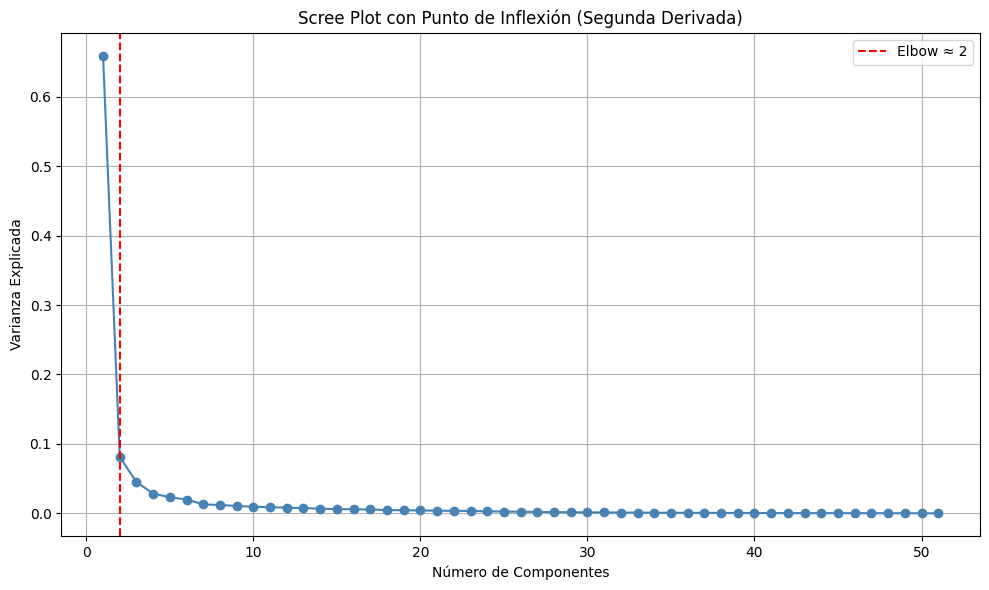

Punto de inflexión sugerido por segunda derivada: 2


In [9]:
# PCA completo
pca_full = PCA()
pca_full.fit(pca_input)

# Varianza explicada
explained_var = pca_full.explained_variance_ratio_

# Segunda derivada
second_derivative = np.diff(explained_var, n=2)
elbow_point = np.argmax(second_derivative) + 2  # +2 para alinear con el número de componentes

# Plot
plt.figure(figsize=(10, 6))
plt.plot(range(1, len(explained_var) + 1), explained_var, marker='o', linestyle='-', color='steelblue')
plt.axvline(x=elbow_point, color='red', linestyle='--', label=f'Elbow ≈ {elbow_point}')
plt.xlabel('Número de Componentes')
plt.ylabel('Varianza Explicada')
plt.title('Scree Plot con Punto de Inflexión (Segunda Derivada)')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

# Imprimir punto de inflexión
print(f"Punto de inflexión sugerido por segunda derivada: {elbow_point}")

In [10]:
pca_2 = PCA(n_components=2)

In [11]:
countries_win6_pca = pca_2.fit_transform(pca_input)

In [12]:
pca_df = pd.DataFrame(countries_win6_pca, columns=['PC1', 'PC2'])

In [13]:
pca_df.head()

,PC1,PC2
0,2.064226,1.489614
1,-7.648769,0.995875
2,-6.580014,0.441960
3,9.370254,-1.189187
4,-10.818940,-1.642285


In [14]:
print(pca_2.explained_variance_ratio_)
print(pca_2.explained_variance_ratio_.sum())

[0.65911374 0.08126612]
0.7403798562035435


### Develop Cluster KMeans++
* With elbow method
* With silhouette plot for quality
* Export df with country, iso_a3, cluster category and continent in parquet format, manage missing values before importing

In [15]:
from sklearn.cluster import KMeans

In [16]:
pca_df.head()

,PC1,PC2
0,2.064226,1.489614
1,-7.648769,0.995875
2,-6.580014,0.441960
3,9.370254,-1.189187
4,-10.818940,-1.642285


In [17]:
pca_df.shape

(51, 2)

#### Using the elbow method to find the optimal number of clusters

In [18]:
import time

In [19]:
distortions = []
# Parameters
n_init_list = [10, 20]
max_iter_list = [100, 500]
n_clusters_range = range(1, 11)
random_states = [21, 42]

KMeans algorithm:
- n_clusters: Specifies the number of clusters to form. It directly determines the granularity of the grouping.
- init: Defines the method for initializing centroids. 'k-means++' is preferred for better convergence.
- n_init: Sets how many times the algorithm runs with different centroid seeds. Higher values improve robustness.
- max_iter: Limits the number of iterations per run. Controls convergence depth.
- tol: Sets the tolerance for declaring convergence. Affects when the algorithm stops based on centroid movement.
- random_state: Fixes the seed for reproducibility. Ensures consistent results across runs.
- algorithm: Chooses the internal algorithm variant ('lloyd' or 'elkan'). 'elkan' is faster for well-separated clusters.



Running elbow plots for random_state=21


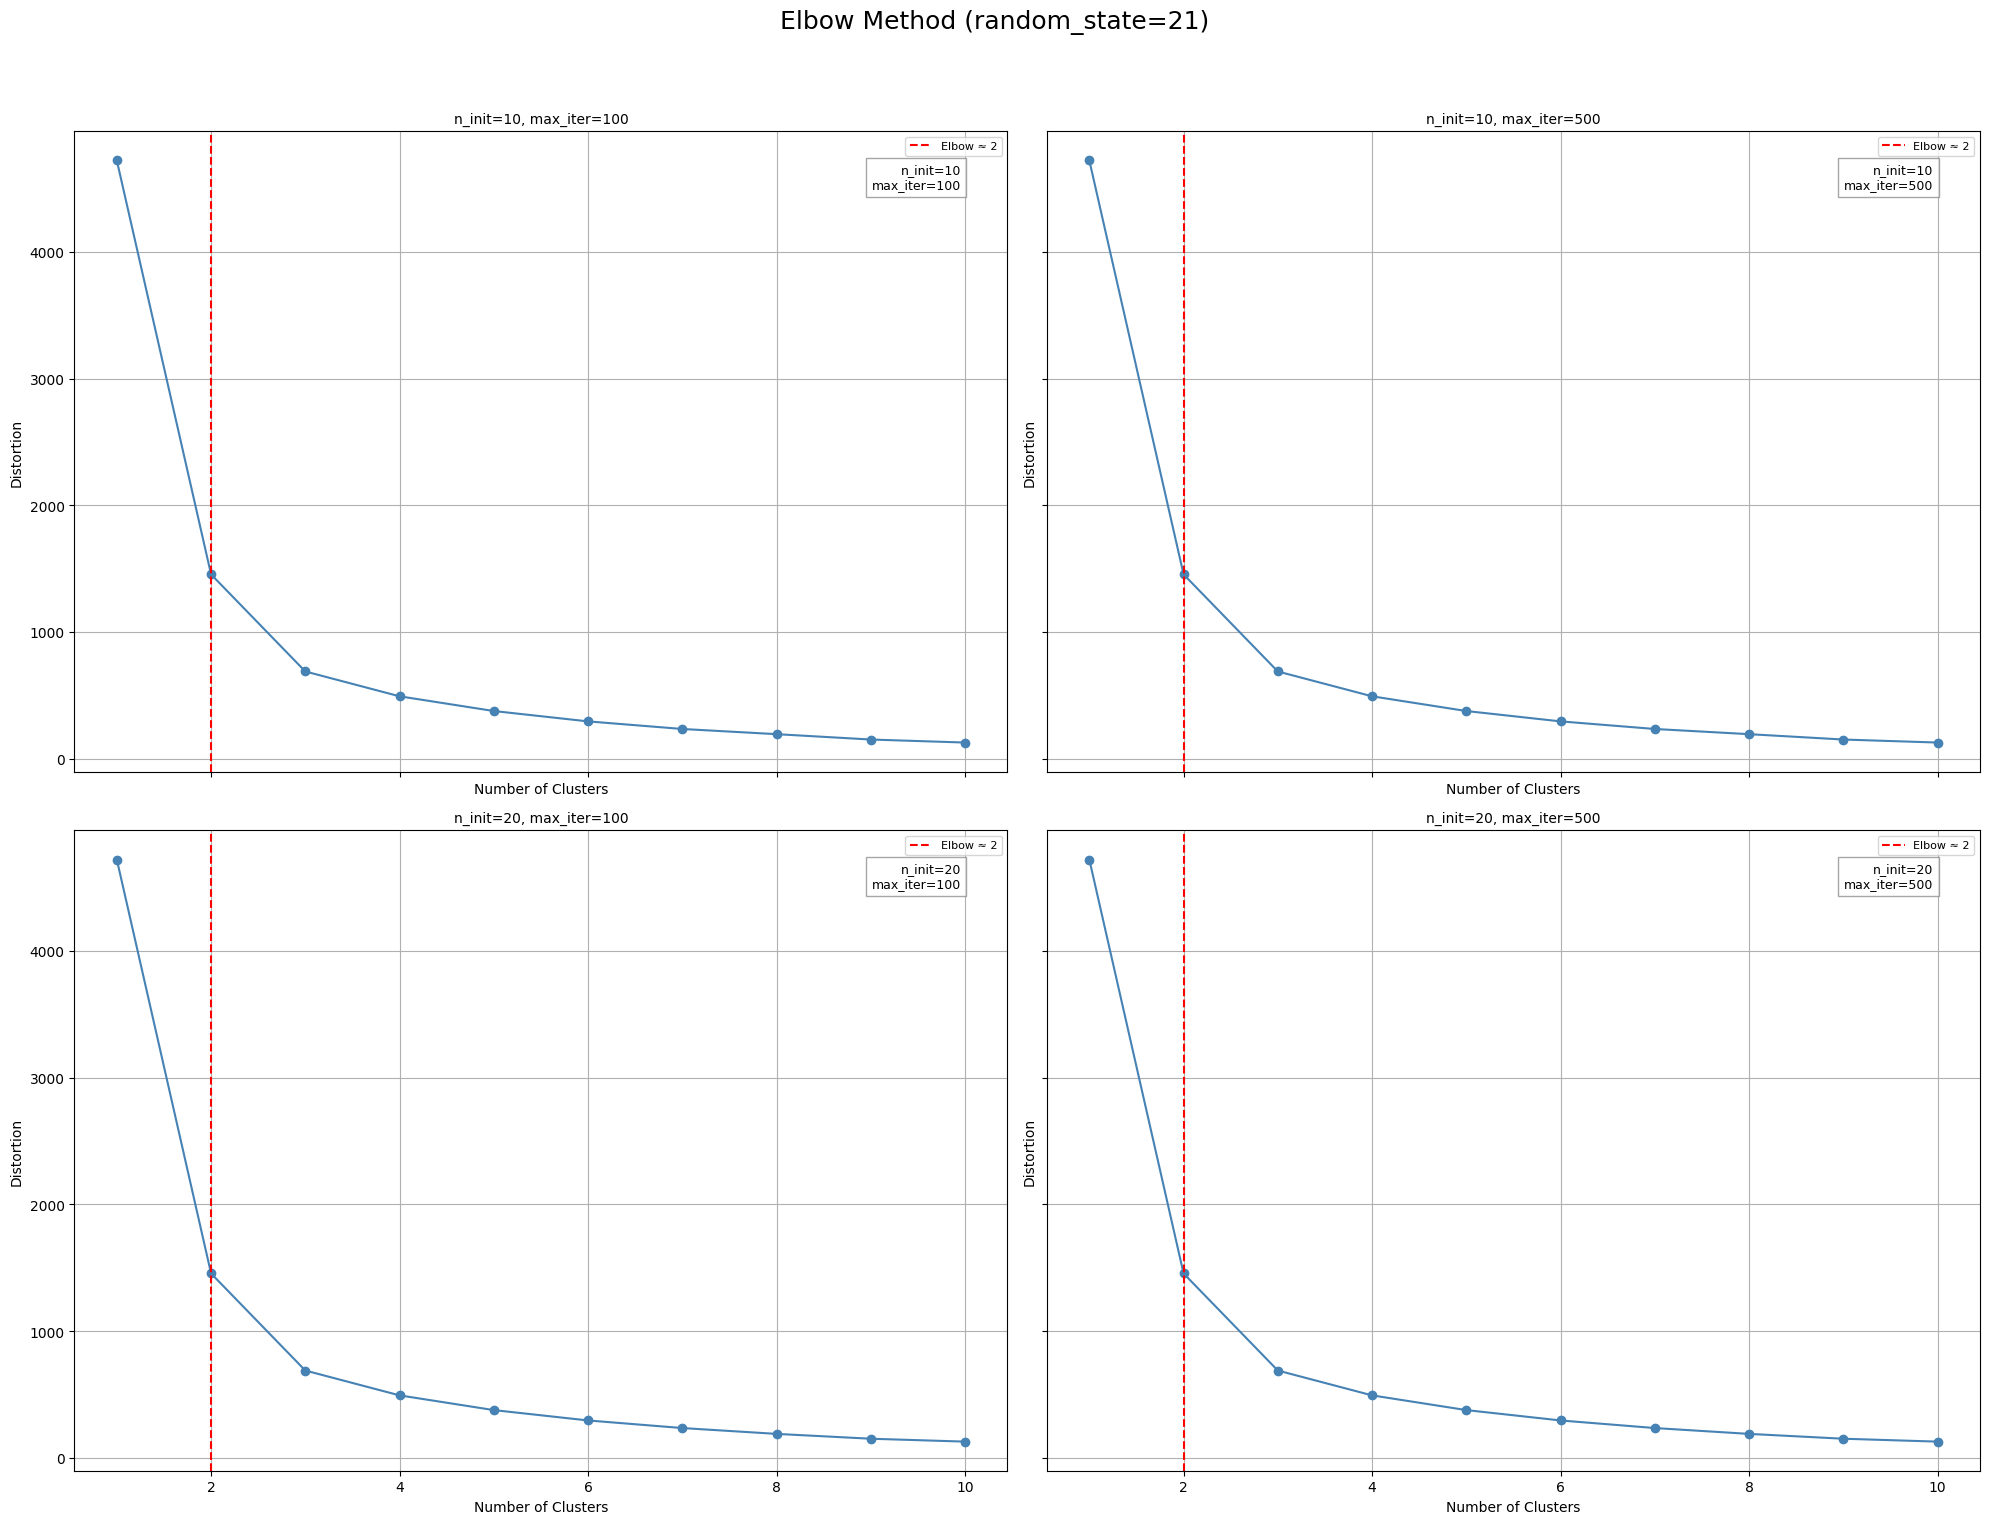


Running elbow plots for random_state=42


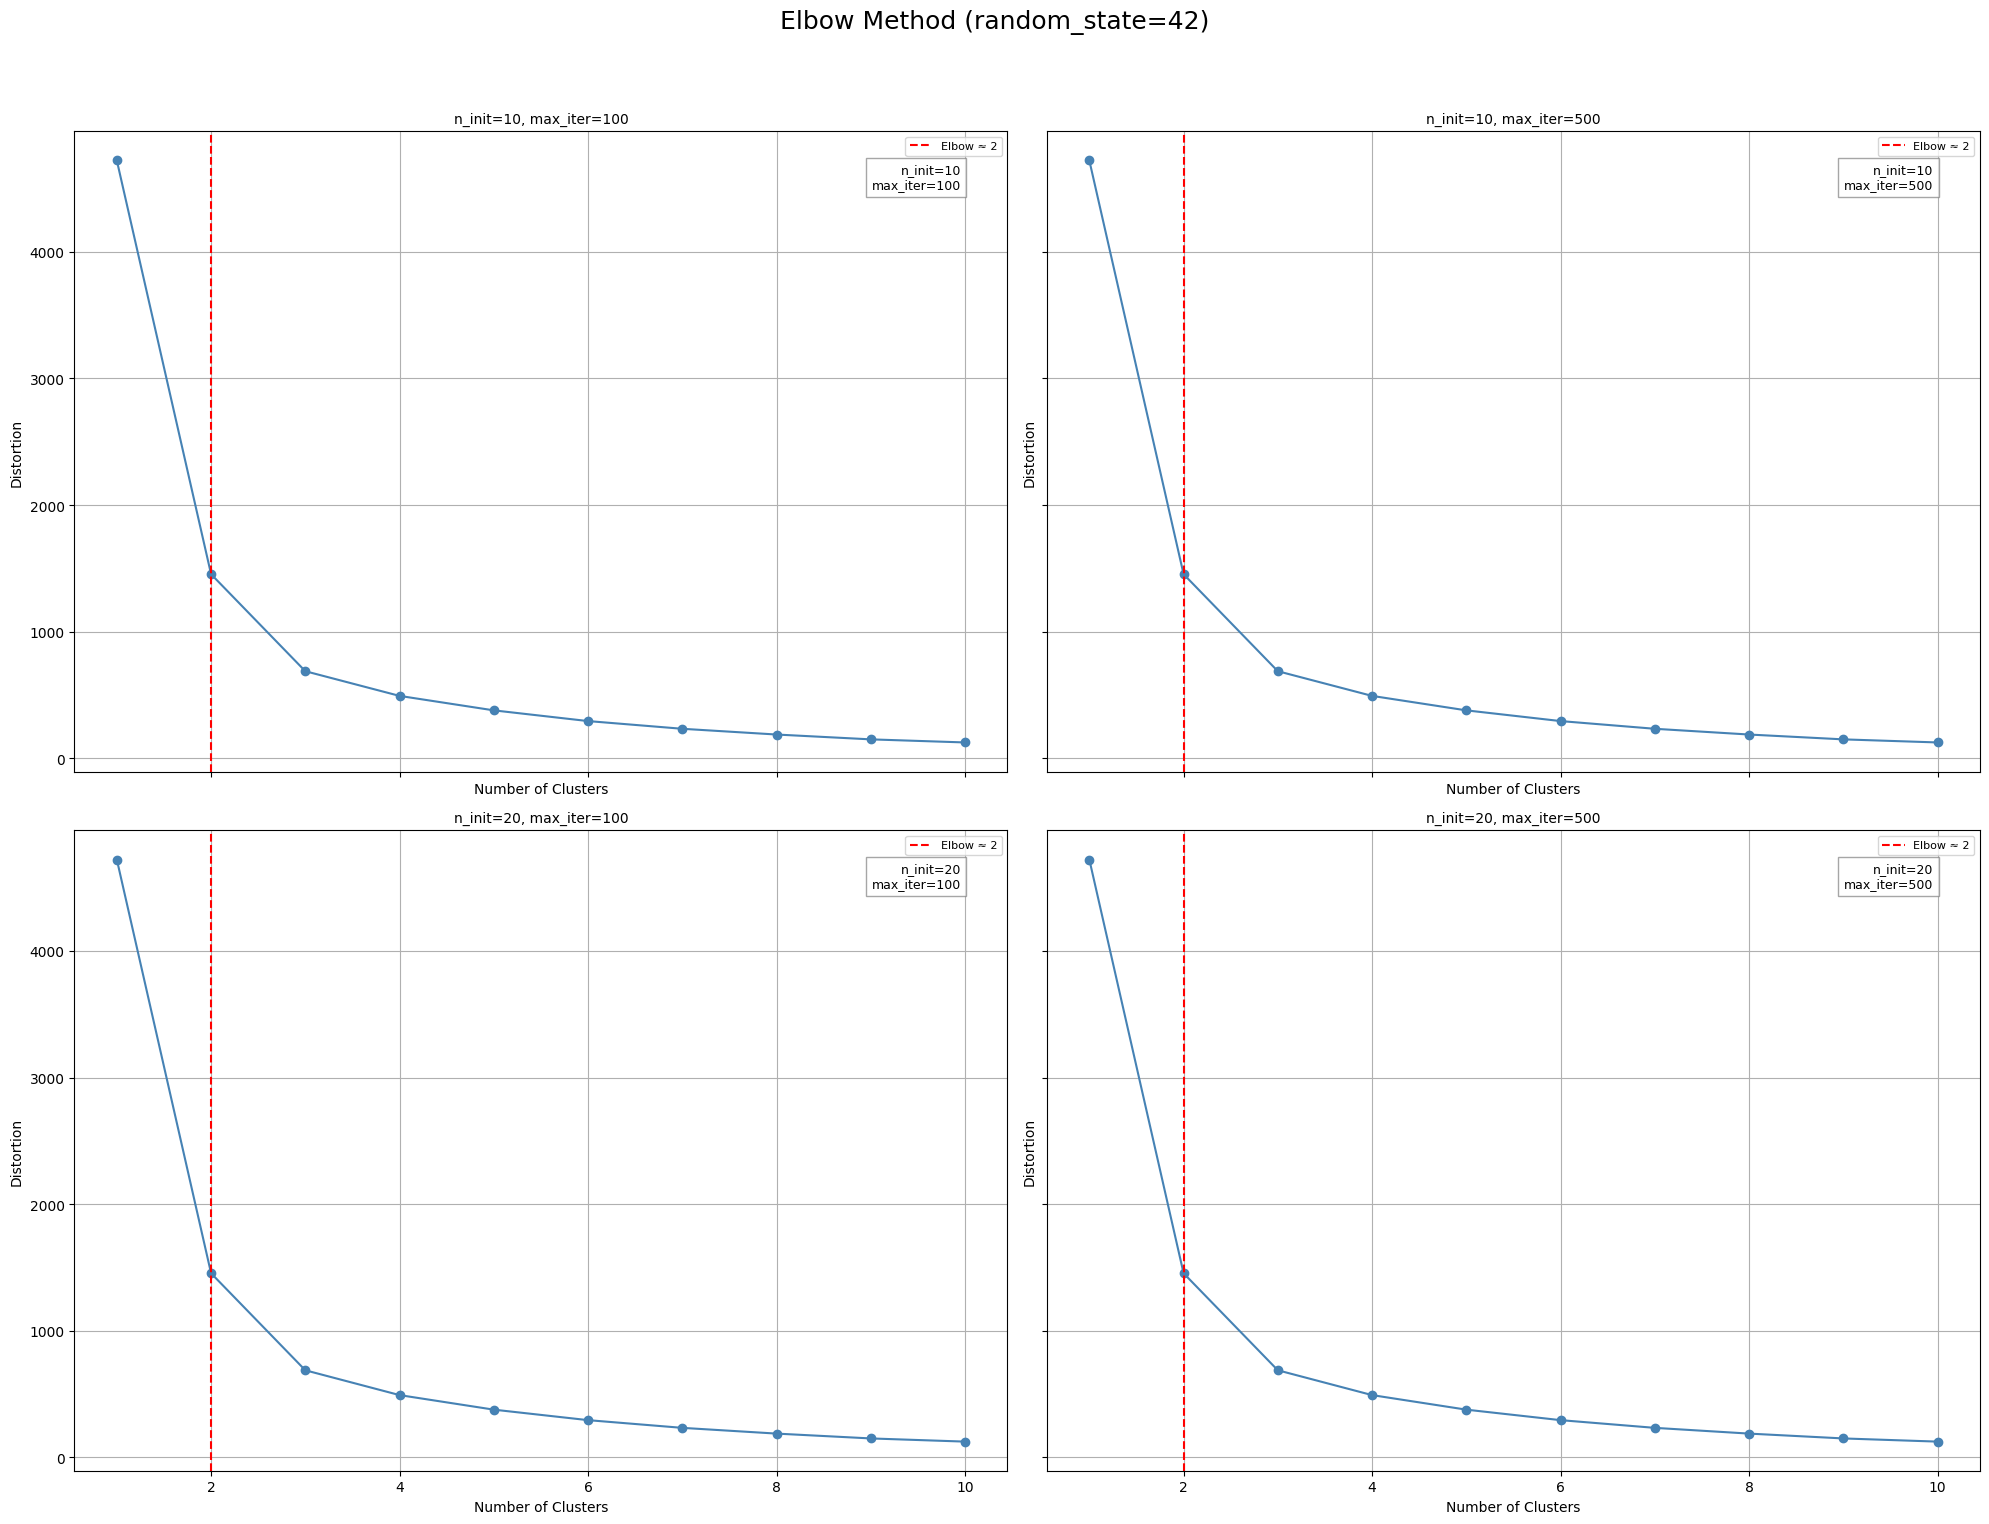


Total execution time: 9.04 seconds


In [32]:
# Start timer
start_time = time.time()

# Iterate over random states
for rs in random_states:
    print(f"\nRunning elbow plots for random_state={rs}")

    # Create figure grid
    fig, axes = plt.subplots(len(n_init_list), len(max_iter_list), figsize=(20, 16), sharex=True, sharey=True)
    fig.suptitle(f'Elbow Method (random_state={rs})', fontsize=18)

    # Iterate over parameter combinations
    for i, n_init in enumerate(n_init_list):
        for j, max_iter in enumerate(max_iter_list):
            distortions = []
            for k in n_clusters_range:
                km = KMeans(
                    n_clusters=k,
                    init='k-means++',
                    n_init=n_init,
                    max_iter=max_iter,
                    random_state=rs
                )
                km.fit(pca_df)
                distortions.append(km.inertia_)

            # Compute second derivative to find elbow
            second_derivative = np.diff(distortions, n=2)
            elbow_point = np.argmax(second_derivative) + 2  # +2 to align with cluster count

            # Plot
            ax = axes[i, j]
            ax.plot(n_clusters_range, distortions, marker='o', linestyle='-', color='steelblue')
            ax.axvline(x=elbow_point, color='red', linestyle='--', label=f'Elbow ≈ {elbow_point}')
            ax.set_title(f'n_init={n_init}, max_iter={max_iter}', fontsize=10)
            ax.set_xlabel('Number of Clusters')
            ax.set_ylabel('Distortion')
            ax.grid(True)
            ax.legend(loc='upper right', fontsize=8)

            # Annotate parameters inside plot
            ax.text(
                0.95, 0.95,
                f'n_init={n_init}\nmax_iter={max_iter}',
                transform=ax.transAxes,
                fontsize=9,
                verticalalignment='top',
                horizontalalignment='right',
                bbox=dict(facecolor='white', alpha=0.7, edgecolor='gray')
            )

    # Final layout and display
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

# End timer
end_time = time.time()
print(f"\nTotal execution time: {end_time - start_time:.2f} seconds")

* Compared to the "parent" experiment from which this one evolves, the distortions achieved with a two-cluster configuration give a much better result.

#### Quantifying the quality of clustering via silhouette plots

The previous code was a nonsense since each iteration found the same elbow, so we will see if each iteration with a different hyperparameter results in a cluster with different members.

The code for each model will be as follows:
- cx = where c corresponds to 'clusters' and x corresponds to the number of clusters used
- nix = where ni corresponds to 'n_init' and x to the number of initializations used
- maxix = where maxi corresponds to 'max_iter' and x to the number of maximum iterations selected

In [20]:
from sklearn.metrics import silhouette_samples

In [21]:
from matplotlib import cm

In [22]:
def plot_silhouette(kmeans_model, X):
    """
    Generates a silhouette plot to evaluate the quality of KMeans clustering.

    Parameters:
    - kmeans_model: a fitted KMeans model.
    - X: the input feature matrix used for clustering.

    Returns:
    - silhouette_avg: the average silhouette coefficient across all samples.
    """
    labels = kmeans_model.labels_
    n_clusters = len(np.unique(labels))
    silhouette_vals = silhouette_samples(X, labels, metric='euclidean')
    silhouette_avg = np.mean(silhouette_vals)

    y_ax_lower, yticks = 0, []

    for i in range(n_clusters):
        cluster_vals = silhouette_vals[labels == i]
        cluster_vals.sort()
        y_ax_upper = y_ax_lower + len(cluster_vals)

        color = cm.jet(float(i) / n_clusters)
        plt.barh(
            range(y_ax_lower, y_ax_upper),
            cluster_vals,
            height=1.0,
            edgecolor='none',
            color=color
        )

        yticks.append((y_ax_lower + y_ax_upper) / 2.)
        y_ax_lower = y_ax_upper

    plt.axvline(silhouette_avg, color="red", linestyle="--", label=f"Average: {silhouette_avg:.2f}")
    plt.yticks(yticks, [f'Cluster {i+1}' for i in range(n_clusters)])
    plt.ylabel('Cluster')
    plt.xlabel('Silhouette coefficient')
    plt.title('Silhouette plot by cluster')
    plt.legend()
    plt.tight_layout()
    plt.show()

    return silhouette_avg

In [23]:
km_c2_ni20_maxi500_pca2 = KMeans(n_clusters=2,
            init='k-means++',
            n_init=20,
            max_iter=500,
            random_state=42)

In [24]:
ym_c2_ni20_maxi500_pca2 = km_c2_ni20_maxi500_pca2.fit(pca_df)

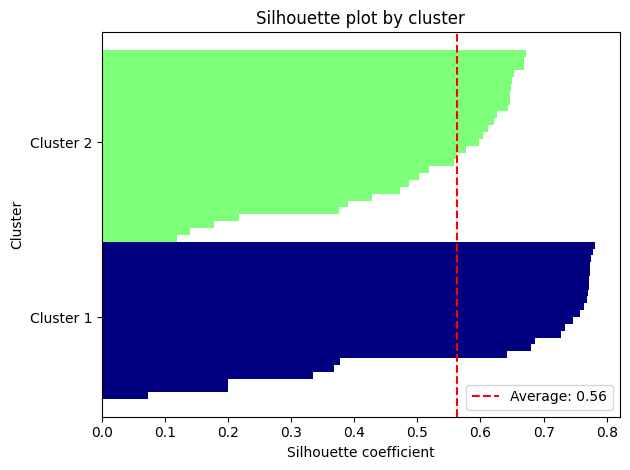

In [25]:
silhoutte_score_pca2 = plot_silhouette(ym_c2_ni20_maxi500_pca2, pca_df)

1. Uniform height on the Y axis
- Each row represents a cluster.
- Height ≠ quality, but if all clusters have a similar number of samples, the bars should have similar heights.
- If you see a very thin cluster (low height), it may indicate that the group has too few elements → possible outlier or oversegmentation.

2. Length of the bars on the X-axis
- This does indicate quality: it is the Silhouette Coefficient of each point.
- Values ​​close to +1 → the point is correctly assigned to its cluster.
- Values ​​close to 0 → the point is on the border between clusters.
- Negative values ​​→ the point is probably incorrectly assigned.

In [26]:
pca_df.head()

,PC1,PC2
0,2.064226,1.489614
1,-7.648769,0.995875
2,-6.580014,0.441960
3,9.370254,-1.189187
4,-10.818940,-1.642285


In [27]:
pca_df.shape

(51, 2)

In [28]:
one_point_countries_win6.shape

(51, 189)

In [29]:
final_pca2 = pca_df.copy()
final_pca2['cluster'] = ym_c2_ni20_maxi500_pca2.labels_
final_pca2.head()

,PC1,PC2,cluster
0,2.064226,1.489614,1
1,-7.648769,0.995875,0
2,-6.580014,0.441960,0
3,9.370254,-1.189187,1
4,-10.818940,-1.642285,0


In [30]:
one_point_countries_win6 = one_point_countries_win6.reset_index()

In [31]:
final_pca2['Country'] = one_point_countries_win6.Country

In [32]:
import country_converter as coco

In [33]:
final_pca2['ISO_A3'] = coco.convert(names=final_pca2['Country'], to='ISO3')

In [34]:
final_pca2.loc[:, 'Continent'] = coco.convert(
    names=final_pca2['Country'], to='continent'
)

In [35]:
def print_cluster_groups(df_clusters):
    """
    Groups countries by their cluster and prints each group with country name and continent.

    Parameters:
    - df_clusters: DataFrame containing 'Country', 'cluster', and 'CONTINENT' columns
    """

    # Ensure required columns exist
    required_cols = {'Country', 'cluster', 'Continent'}
    if not required_cols.issubset(df_clusters.columns):
        print("Missing required columns in the DataFrame.")
        return

    # Group countries by cluster
    grouped = df_clusters.groupby('cluster')

    # Print each cluster group
    for cluster_id, group in grouped:
        print(f"\n🌍 Cluster {cluster_id} ({len(group)} countries):")
        for _, row in group.iterrows():
            country = row['Country']
            continent = row['Continent']
            print(f" - {country} ({continent})")

In [36]:
print_cluster_groups(final_pca2)


🌍 Cluster 0 (23 countries):
 - Austria (Europe)
 - Belgium (Europe)
 - Bulgaria (Europe)
 - Croatia (Europe)
 - Cyprus (Asia)
 - Estonia (Europe)
 - Finland (Europe)
 - Greece (Europe)
 - Ireland (Europe)
 - Latvia (Europe)
 - Lithuania (Europe)
 - Luxembourg (Europe)
 - Malta (Europe)
 - Netherlands (Europe)
 - New Zealand (Oceania)
 - Peru (America)
 - Portugal (Europe)
 - Romania (Europe)
 - Singapore (Asia)
 - Slovakia (Europe)
 - Slovenia (Europe)
 - Spain (Europe)
 - Switzerland (Europe)

🌍 Cluster 1 (28 countries):
 - Australia (Oceania)
 - Brazil (America)
 - Canada (America)
 - Chile (America)
 - Colombia (America)
 - Czech (Europe)
 - Denmark (Europe)
 - France (Europe)
 - Germany (Europe)
 - Hungary (Europe)
 - Iceland (Europe)
 - Israel (Asia)
 - Italy (Europe)
 - Japan (Asia)
 - Malaysia (Asia)
 - Mexico (America)
 - Norway (Europe)
 - Paraguay (America)
 - Philippines (Asia)
 - Poland (Europe)
 - Russia (Europe)
 - Serbia (Europe)
 - South Africa (Africa)
 - South Korea 

* It gives the same result that the "parent" experiment from wich this one evolves

In [37]:
final_pca2['Country'] = final_pca2['Country'].replace('Czech','Czech Republic')

In [83]:
final_pca2.to_parquet('../data/clusters/clusters_plusplus_c2_ni20_maxi500_without_outliers_3countries_deleted_pca2.parquet')

In [49]:
df_continet = pd.read_parquet('../data/clusters/clusters_plusplus_c2_ni20_maxi500_without_outliers_3countries_deleted_pca2.parquet')

### Import and clean data for create synthetic data
* Import the data for hpi by country
* Observe if have Pararguay country
* Look if have the same countries that the df with the culsters
* Look if the name of the countries are in the same format "-" or "_"
* Delete countries that do not exist in the HPI dataframe

In [2]:
df_hpi_winsorized = pd.read_parquet('../data/hpi_3_deleted_countries_winsorized4.parquet')

In [3]:
df_hpi_winsorized.shape

(15, 51)

In [4]:
def find_countries_missing_from_clusters(df_hpi, df_clusters, country_column='Country'):
    """
    Identifies which countries are present in the HPI DataFrame but missing from the cluster DataFrame.

    Parameters:
    - df_hpi: DataFrame where columns are country names and rows are years (House Price Index data)
    - df_clusters: DataFrame with country names and cluster assignments
    - country_column: Name of the column in df_clusters that contains country names (default: 'Country')

    Returns:
    - List of country names that are in df_hpi but not in df_clusters
    """

    # Extract country names from HPI DataFrame (column headers)
    hpi_countries = set(df_hpi.columns)

    # Extract country names from cluster DataFrame
    cluster_countries = set(df_clusters[country_column].unique())

    # Find countries present in HPI but missing from clusters
    missing_countries = hpi_countries - cluster_countries

    # Print results
    if missing_countries:
        print("Countries in HPI that are missing from the cluster DataFrame:")
        for country in sorted(missing_countries):
            print(f" - {country}")
    else:
        print("All countries in the HPI DataFrame are present in the cluster DataFrame.")

    return list(missing_countries)

In [6]:
find_countries_missing_from_clusters(df_hpi_winsorized, df_continet)

Countries in HPI that are missing from the cluster DataFrame:
 - Year


['Year']

### Leverage The Law of Large Numbers and compute metrics
* Run the sampling process for each cluster, exclude one country of that cluster to compare

In [8]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

In [27]:
import country_converter as coco

In [50]:
df_continet['UNregion'] = coco.convert(names=df_continet['Country'], to='UNregion')

In [51]:
df_continet.head()

,PC1,PC2,cluster,Country,ISO_A3,Continent,UNregion
0,2.064226,1.489614,1,Australia,AUS,Oceania,Australia and New Zealand
1,-7.648769,0.995875,0,Austria,AUT,Europe,Western Europe
2,-6.580014,0.441960,0,Belgium,BEL,Europe,Western Europe
3,9.370254,-1.189187,1,Brazil,BRA,America,South America
4,-10.818940,-1.642285,0,Bulgaria,BGR,Europe,Eastern Europe


In [11]:
def plot_cluster_hpi_with_bootstrap(df_hpi, df_clusters, cluster_id,
                                    yearly_bootstrap_means,
                                    yearly_mean,
                                    cluster_column='Continent', country_column='Country',
                                    year_column='Year'):
    """
    Plots HPI values for each country in a cluster over time,
    along with the synthetic bootstrap mean per year and the actual cluster mean.

    Parameters:
    - df_hpi: DataFrame with HPI values (columns = countries, rows = years, plus 'Year' column)
    - df_clusters: DataFrame with country names and cluster assignments
    - cluster_id: Cluster number to plot
    - yearly_bootstrap_means: Dict with year as key and synthetic mean value
    - yearly_mean: Dict with year as key and actual mean HPI of all countries in the cluster
    """
    # Obtener países del cluster
    cluster_countries = df_clusters[df_clusters[cluster_column] == cluster_id][country_column].tolist()
    cluster_countries = [c for c in cluster_countries if c in df_hpi.columns]

    if len(cluster_countries) == 0:
        raise ValueError("No hay países válidos en el cluster para graficar.")

    # Graficar HPI real por país
    plt.figure(figsize=(12, 6))
    for country in cluster_countries:
        country_data = df_hpi[[year_column, country]].dropna()
        plt.plot(country_data[year_column], country_data[country], label=country, alpha=0.6)

    # Graficar curva sintética del bootstrap
    bootstrap_years = sorted(yearly_bootstrap_means.keys())
    bootstrap_values = [yearly_bootstrap_means[year] for year in bootstrap_years]
    plt.plot(bootstrap_years, bootstrap_values, label='Bootstrap Mean', color='black', linewidth=2.5)

    # Graficar media real del cluster (línea discontinua)
    mean_years = sorted(yearly_mean.keys())
    mean_values = [yearly_mean[year] for year in mean_years]
    plt.plot(mean_years, mean_values, label='Real Cluster Mean', color='gray', linestyle='--', linewidth=2.5)

    # Estética del gráfico
    plt.title(f"HPI por País en Continente {cluster_id} + Medias Sintéticas y Reales")
    plt.xlabel("Año")
    plt.ylabel("Índice HPI")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

In [12]:
def calculate_hpi_variance_by_cluster(df_hpi, df_clusters,
                                      cluster_column='Continent', country_column='Country',
                                      year_column='Year'):
    """
    Calculates average HPI variance across countries for each cluster.

    Parameters:
    - df_hpi: DataFrame with HPI values (columns = countries, rows = years, plus 'Year' column)
    - df_clusters: DataFrame with country names and cluster assignments
    - cluster_column: Column name in df_clusters with cluster labels
    - country_column: Column name in df_clusters with country names
    - year_column: Column name in df_hpi with year values

    Returns:
    - cluster_variances: dict with cluster_id as key and average variance as value
    """
    cluster_variances = {}

    for cluster_id in sorted(df_clusters[cluster_column].unique()):
        # Get countries in this cluster that are present in HPI data
        countries = df_clusters[df_clusters[cluster_column] == cluster_id][country_column].tolist()
        cluster_countries = [c for c in countries if c in df_hpi.columns]

        if len(cluster_countries) < 2:
            cluster_variances[cluster_id] = np.nan
            continue

        # Extract HPI values for cluster countries
        hpi_values = df_hpi[cluster_countries]

        # Calculate variance across countries for each year
        yearly_variances = hpi_values.var(axis=1, skipna=True)

        # Compute average variance across all years
        avg_variance = yearly_variances.mean()
        cluster_variances[cluster_id] = avg_variance

    return cluster_variances

In [67]:
def evaluate_cluster_sampling_errors(df_hpi, df_clusters, cluster_id,
                                     cluster_column='Continent', country_column='Country',
                                     year_column='Year', sample_size=30, n_samples=1000,
                                     plot=True, seed=None, start_year=None):

    """
    Evaluates synthetic HPI estimation via bootstrap sampling for each country in a cluster.

    Returns:
    - avg_mse: Average MSE across all countries in the cluster
    - avg_mae: Average MAE across all countries in the cluster
    - best_country: Country with the lowest MSE
    - yearly_bootstrap_means: Dict with year as key and synthetic mean using best_country as excluded
    - yearly_mean: Dict with year as key and actual mean HPI of all countries in the cluster
    """
    if seed is not None:
        random.seed(seed)
        np.random.seed(seed)

    if start_year is not None:
        df_hpi = df_hpi[df_hpi[year_column] >= start_year]

    all_cluster_countries = df_clusters[df_clusters[cluster_column] == cluster_id][country_column].tolist()
    cluster_countries = [c for c in all_cluster_countries if c in df_hpi.columns]

    if len(cluster_countries) < 2:
        raise ValueError("Cluster must contain at least two countries present in HPI data.")

    mse_scores = {}
    mae_scores = {}

    for excluded_country in cluster_countries:
        sampling_countries = [c for c in cluster_countries if c != excluded_country]
        synthetic_values = []
        actual_values = []

        for _, row in df_hpi.iterrows():
            year = row[year_column]
            values = row[sampling_countries].dropna().values
            actual_value = row.get(excluded_country, np.nan)

            if len(values) == 0 or np.isnan(actual_value):
                continue

            sample_means = [np.mean(np.random.choice(values, size=sample_size, replace=True))
                            for _ in range(n_samples)]
            synthetic_mean = np.mean(sample_means)

            synthetic_values.append(synthetic_mean)
            actual_values.append(actual_value)

        if len(synthetic_values) == 0:
            mse_scores[excluded_country] = np.nan
            mae_scores[excluded_country] = np.nan
        else:
            errors = np.array(synthetic_values) - np.array(actual_values)
            mse_scores[excluded_country] = np.mean(errors ** 2)
            mae_scores[excluded_country] = np.mean(np.abs(errors))

    best_country = min(mse_scores, key=lambda k: mse_scores[k] if not np.isnan(mse_scores[k]) else np.inf)

    # Plot for best country
    if plot:
        synthetic_values = []
        actual_values = []
        years = []

        sampling_countries = [c for c in cluster_countries if c != best_country]

        for _, row in df_hpi.iterrows():
            year = row[year_column]
            values = row[sampling_countries].dropna().values
            actual_value = row.get(best_country, np.nan)

            if len(values) == 0 or np.isnan(actual_value):
                continue

            sample_means = [np.mean(np.random.choice(values, size=sample_size, replace=True))
                            for _ in range(n_samples)]
            cumulative_means = [np.mean(sample_means[:j+1]) for j in range(n_samples)]

            lower_bound = np.percentile(sample_means, 2.5)
            upper_bound = np.percentile(sample_means, 97.5)

            fig, axes = plt.subplots(1, 2, figsize=(14, 4))

            axes[0].hist(sample_means, bins=30, color='lightgreen', edgecolor='black')
            axes[0].axvline(actual_value, color='red', linestyle='--', label=f"Actual: {best_country}")
            axes[0].axvline(lower_bound, color='blue', linestyle=':', label='95% CI Lower')
            axes[0].axvline(upper_bound, color='blue', linestyle=':', label='95% CI Upper')
            axes[0].set_title(f"HPI Sampling Distribution - Year {year}")
            axes[0].set_xlabel("Sample Mean HPI")
            axes[0].set_ylabel("Frequency")
            axes[0].legend()
            axes[0].grid(True)

            axes[1].plot(cumulative_means, color='purple')
            axes[1].axhline(np.mean(sample_means), color='gray', linestyle='--', label='Final Mean')
            axes[1].set_title("Mean Convergence Over Iterations")
            axes[1].set_xlabel("Iteration")
            axes[1].set_ylabel("Cumulative Mean")
            axes[1].legend()
            axes[1].grid(True)

            plt.tight_layout()
            plt.show()

    # Synthetic mean per year using best_country as excluded
    yearly_bootstrap_means = {}
    sampling_countries = [c for c in cluster_countries if c != best_country]

    for _, row in df_hpi.iterrows():
        year = row[year_column]
        values = row[sampling_countries].dropna().values

        if len(values) == 0:
            continue

        sample_means = [np.mean(np.random.choice(values, size=sample_size, replace=True))
                        for _ in range(n_samples)]
        synthetic_mean = np.mean(sample_means)
        yearly_bootstrap_means[year] = synthetic_mean

    # Real mean per year using all countries in the cluster
    yearly_mean = {}
    for _, row in df_hpi.iterrows():
        year = row[year_column]
        values = row[cluster_countries].dropna().values

        if len(values) == 0:
            continue

        yearly_mean[year] = np.mean(values)

    avg_mse = np.nanmean(list(mse_scores.values()))
    avg_mae = np.nanmean(list(mae_scores.values()))

    return avg_mse, avg_mae, best_country, yearly_bootstrap_means, yearly_mean

In [14]:
def count_points_within_iqr_by_cluster(df_hpi, df_clusters,
                                       cluster_column='Continent', country_column='Country',
                                       year_column='Year'):
    """
    Cuenta cuántos puntos de HPI están dentro del IQR (Q1–Q3) por cluster.

    Returns:
    - dict con cluster_id como clave y cantidad total de puntos dentro del IQR como valor
    """
    cluster_iqr_counts = {}

    for cluster_id in sorted(df_clusters[cluster_column].unique()):
        # Obtener países del cluster presentes en df_hpi
        countries = df_clusters[df_clusters[cluster_column] == cluster_id][country_column].tolist()
        cluster_countries = [c for c in countries if c in df_hpi.columns]

        if len(cluster_countries) < 2:
            cluster_iqr_counts[cluster_id] = 0
            continue

        # Extraer valores de HPI para esos países
        hpi_values = df_hpi[cluster_countries]

        total_within_iqr = 0

        # Iterar por año
        for _, row in hpi_values.iterrows():
            values = row.dropna().values
            if len(values) < 2:
                continue

            q1 = np.percentile(values, 25)
            q3 = np.percentile(values, 75)

            # Contar cuántos valores están dentro del IQR
            count = np.sum((values >= q1) & (values <= q3))
            total_within_iqr += count

        cluster_iqr_counts[cluster_id] = total_within_iqr

    return cluster_iqr_counts

In [98]:
def plot_region_clusters(df, x_col, y_col, region_col='UNregion',
                         country_col='Country', highlight_country='Paraguay'):
    # Extraer coordenadas
    X = df[[x_col, y_col]].values
    regions = df[region_col].values
    countries = df[country_col].values

    # Crear figura
    plt.figure(figsize=(10, 6))

    # Colores y marcadores por región
    unique_regions = sorted(df[region_col].unique())
    colors = ['lightgreen', 'orange', 'lightblue', 'purple', 'gold', 'pink', 'gray', 'brown', 'cyan', 'red']
    markers = ['o', 's', 'v', '^', '<', '>', 'D', 'p', '*', 'h']
    special_marker = 'X'  # marcador especial para Paraguay

    region_color_map = {region: colors[i % len(colors)] for i, region in enumerate(unique_regions)}
    region_marker_map = {region: markers[i % len(markers)] for i, region in enumerate(unique_regions)}

    # Graficar cada región
    for region in unique_regions:
        region_mask = (regions == region)
        region_color = region_color_map[region]
        region_marker = region_marker_map[region]

        # Separar Paraguay del resto
        paraguay_mask = region_mask & (countries == highlight_country)
        others_mask = region_mask & (countries != highlight_country)

        # Graficar otros países de la región
        plt.scatter(X[others_mask, 0], X[others_mask, 1],
                    s=50, c=region_color, marker=region_marker,
                    edgecolor='black', label=f'{region}')

        # Graficar Paraguay con marcador especial
        if paraguay_mask.any():
            plt.scatter(X[paraguay_mask, 0], X[paraguay_mask, 1],
                        s=100, c=region_color, marker=special_marker,
                        edgecolor='black', label=f'{highlight_country} ({region})')

    plt.xlabel(x_col)
    plt.ylabel(y_col)
    plt.legend(scatterpoints=1)
    plt.grid(True)
    plt.tight_layout()
    plt.title(f'Regional Clustering: {x_col} vs {y_col}')
    plt.show()

In [52]:
df_continet.UNregion.unique()

array(['Australia and New Zealand', 'Western Europe', 'South America',
       'Eastern Europe', 'Northern America', 'Southern Europe',
       'Western Asia', 'Northern Europe', 'Eastern Asia',
       'South-eastern Asia', 'Central America', 'Southern Africa'],
      dtype=object)

In [53]:
df_continet[df_continet["Continent"]=="Oceania"]

,PC1,PC2,cluster,Country,ISO_A3,Continent,UNregion
0,2.064226,1.489614,1,Australia,AUS,Oceania,Australia and New Zealand
30,-7.793652,1.523987,0,New Zealand,NZL,Oceania,Australia and New Zealand


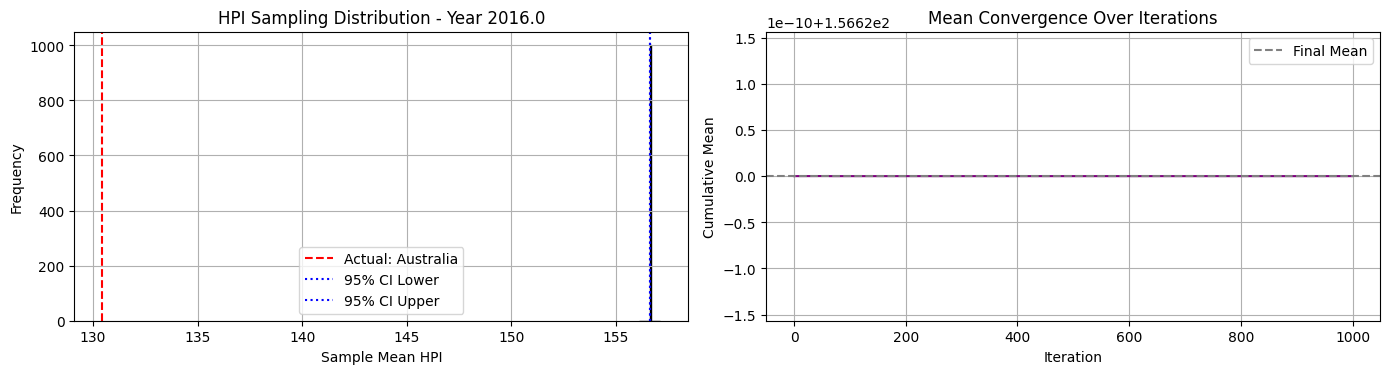

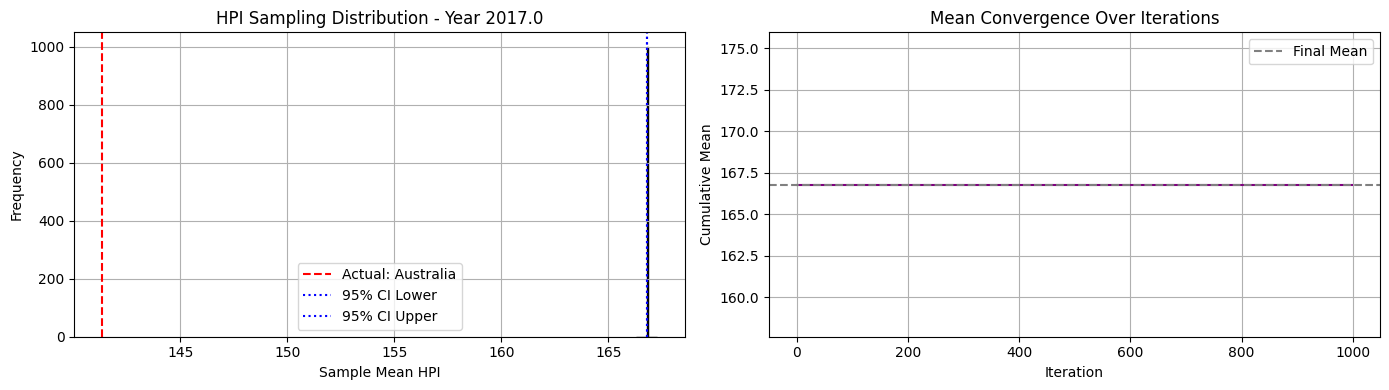

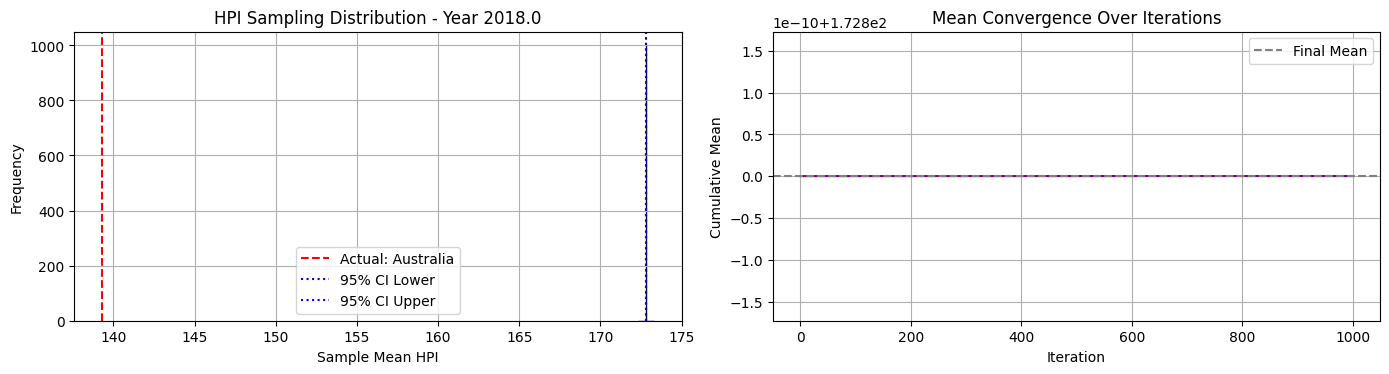

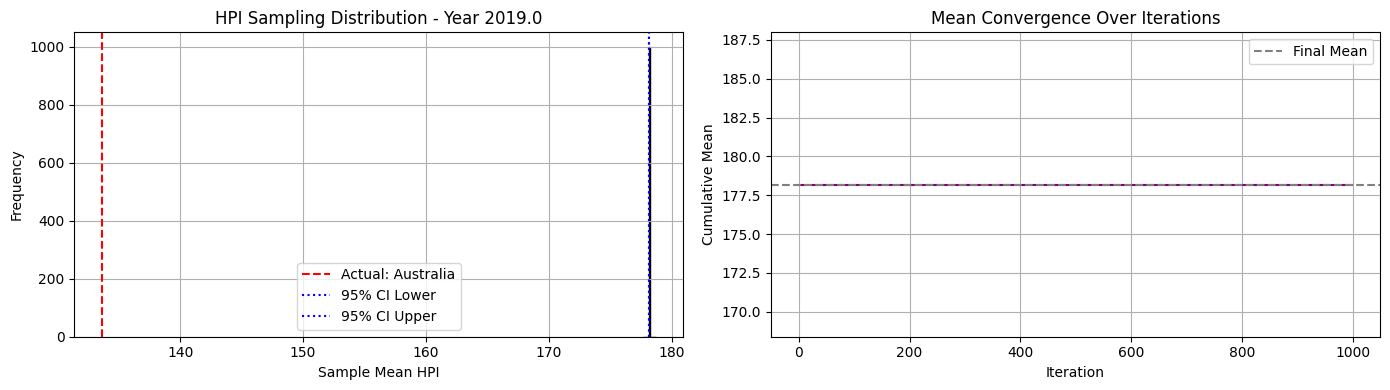

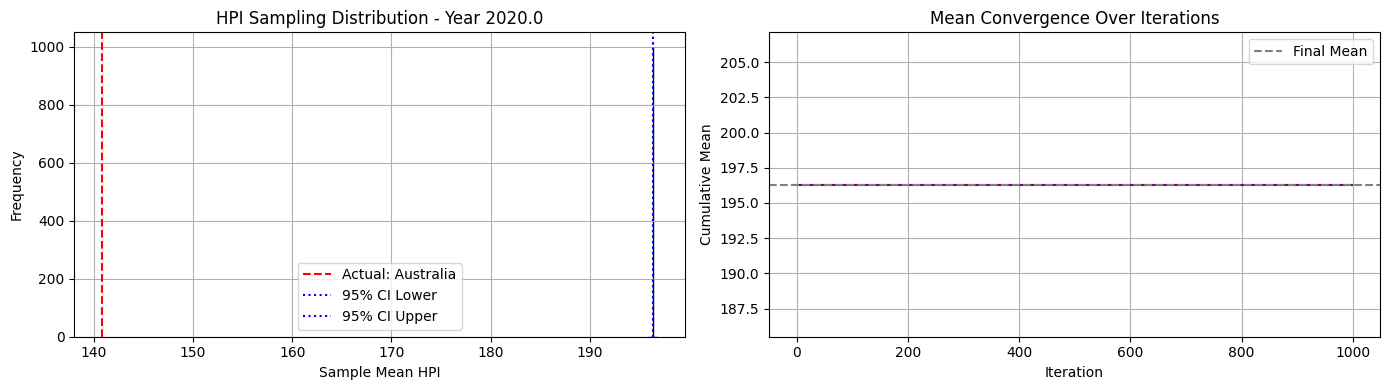

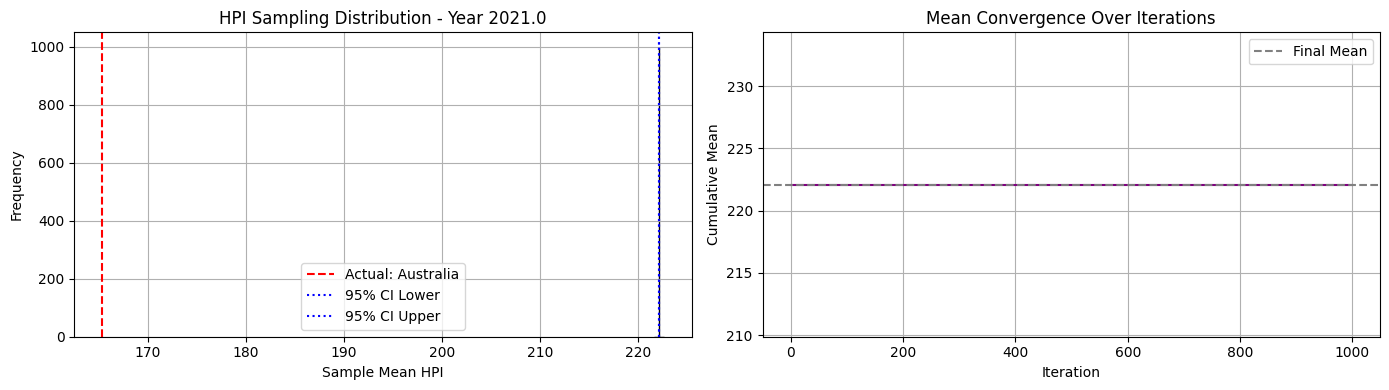

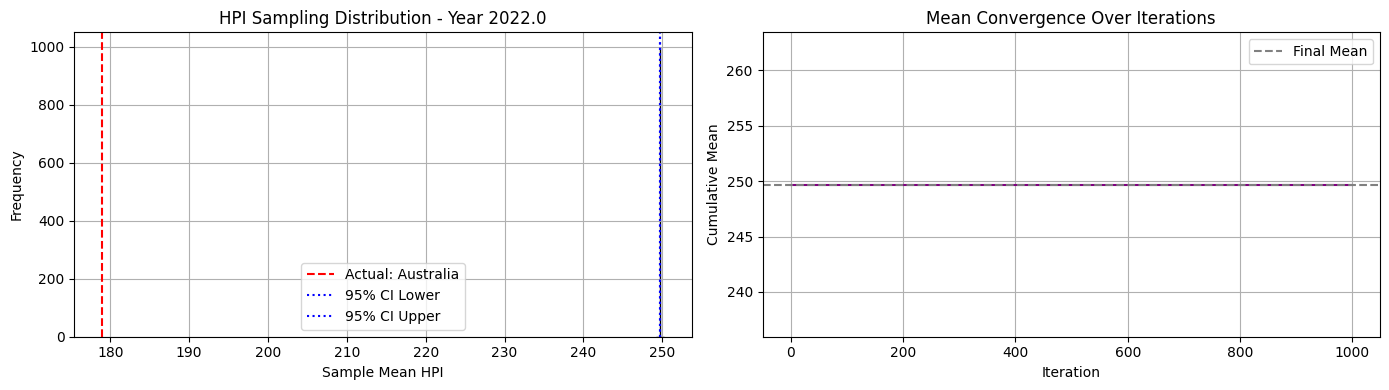

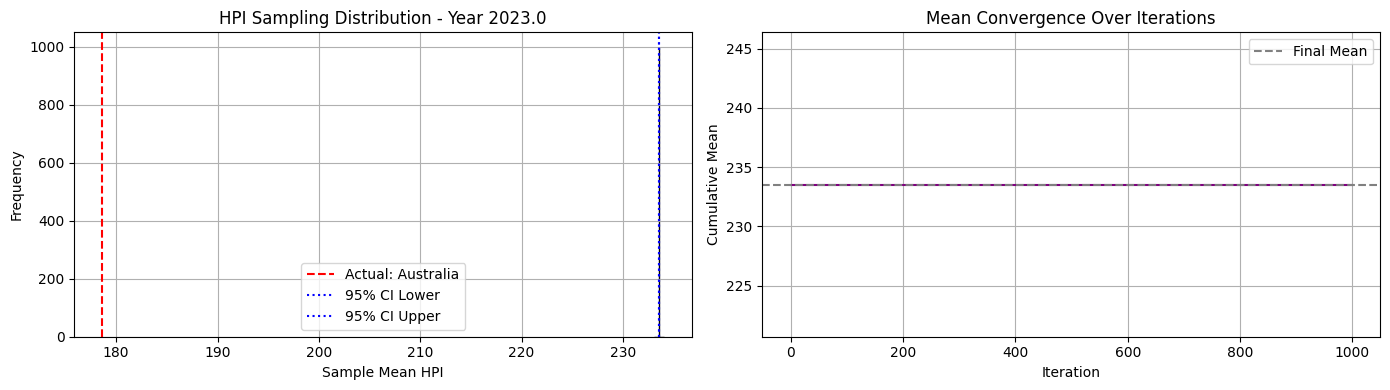

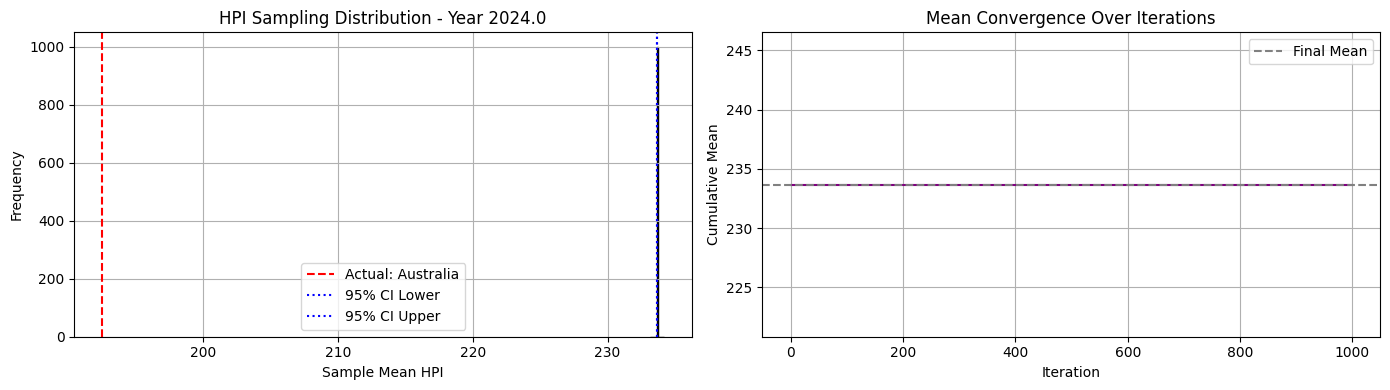

In [68]:
avg_mse_00, avg_mae_00, best_country_00, yearly_bootstrap_means_00, yearly_mean_00 = evaluate_cluster_sampling_errors(df_hpi_winsorized, df_clusters=df_continet, cluster_id="Oceania", start_year=2016)

In [54]:
df_continet[df_continet["UNregion"]=="Western Europe"]

,PC1,PC2,cluster,Country,ISO_A3,Continent,UNregion
1,-7.648769,0.995875,0,Austria,AUT,Europe,Western Europe
2,-6.580014,0.441960,0,Belgium,BEL,Europe,Western Europe
14,3.083746,3.008716,1,France,FRA,Europe,Western Europe
15,4.929904,3.858738,1,Germany,DEU,Europe,Western Europe
25,-12.629845,-0.344519,0,Luxembourg,LUX,Europe,Western Europe
29,-3.463999,1.351977,0,Netherlands,NLD,Europe,Western Europe
47,-3.081657,6.948384,0,Switzerland,CHE,Europe,Western Europe


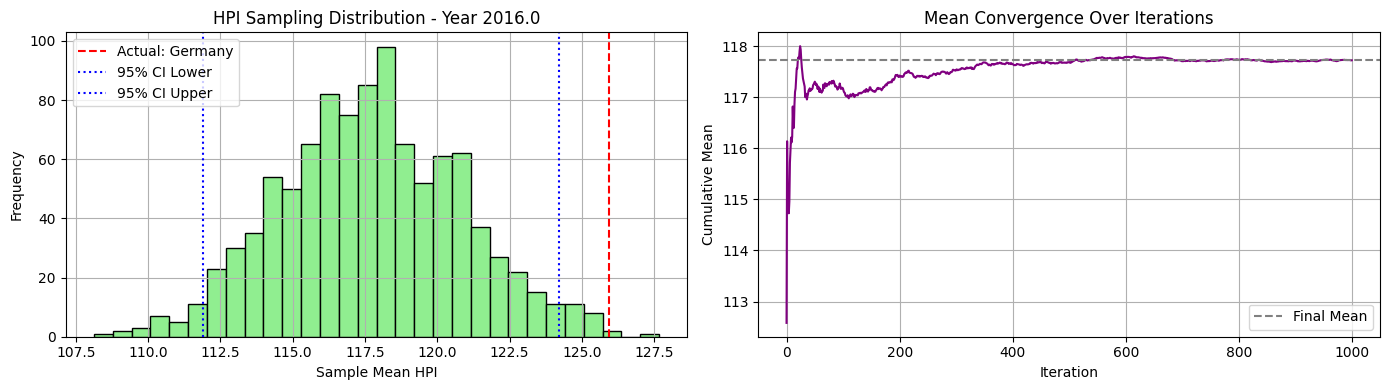

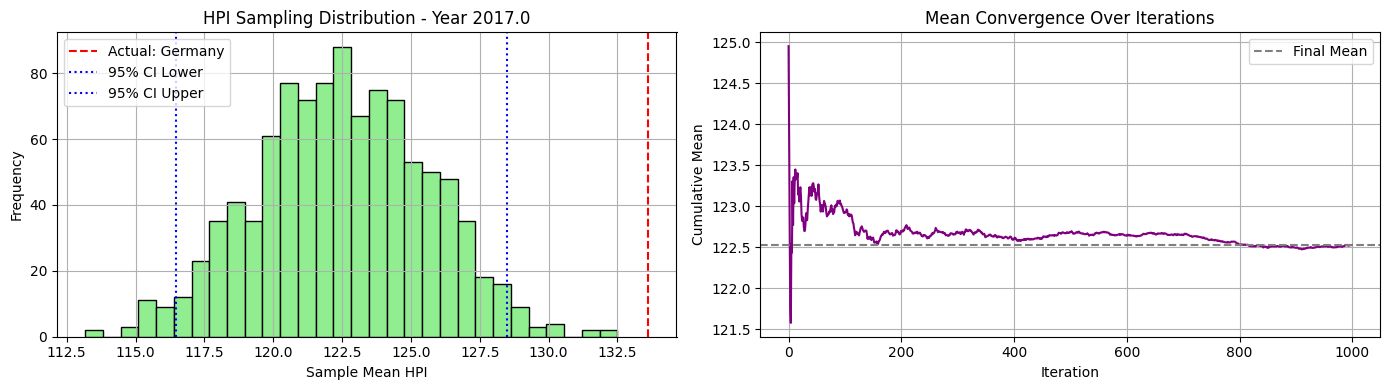

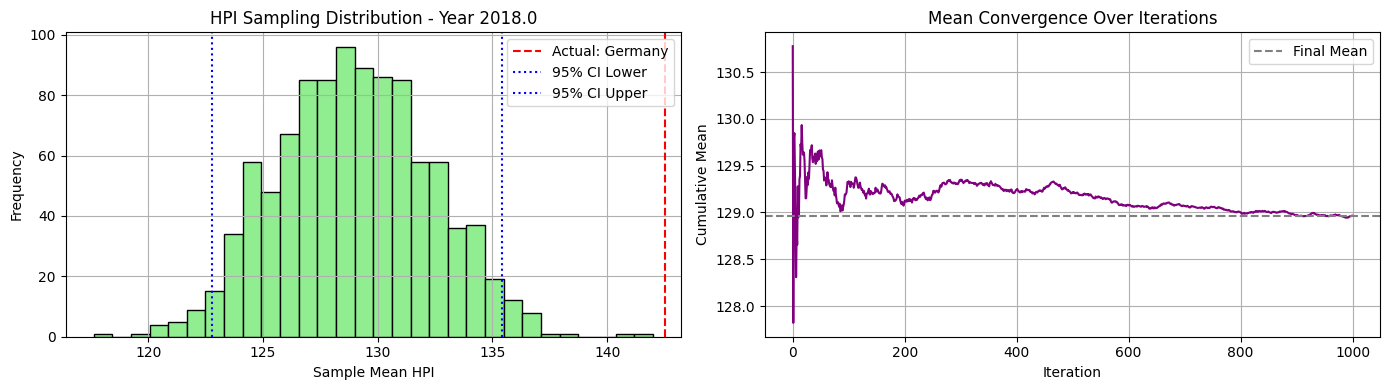

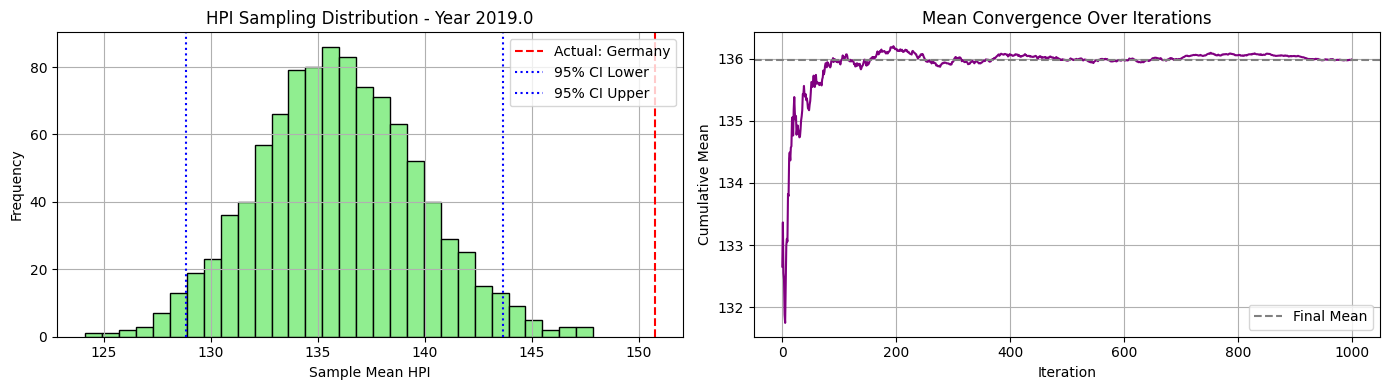

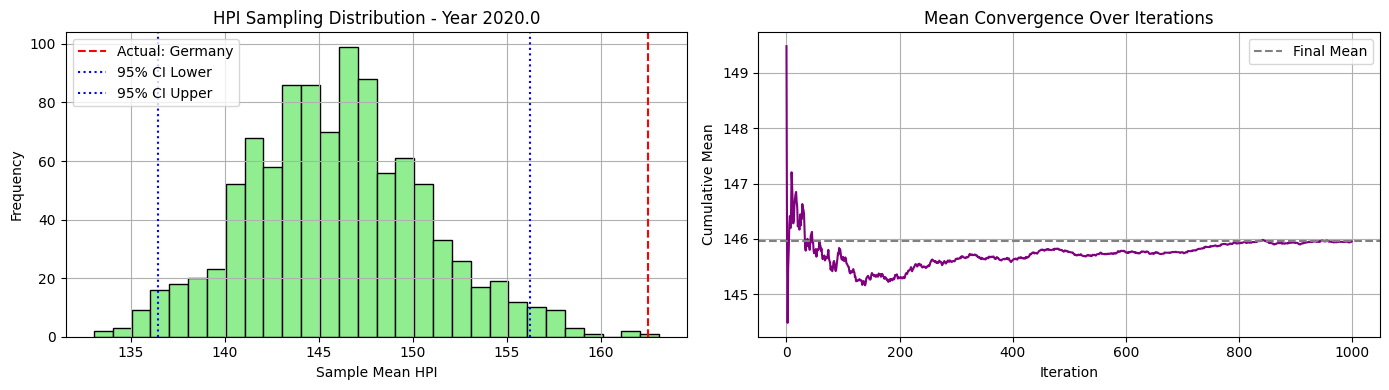

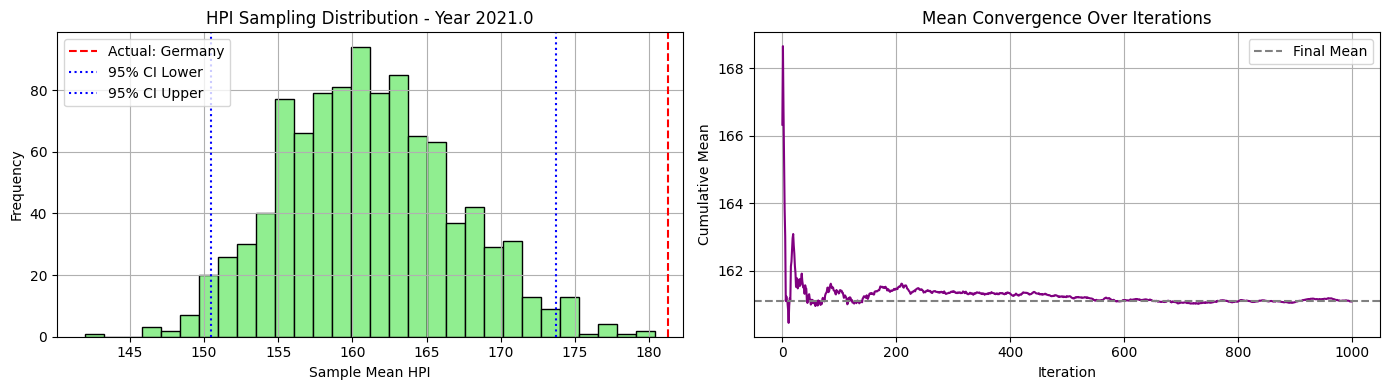

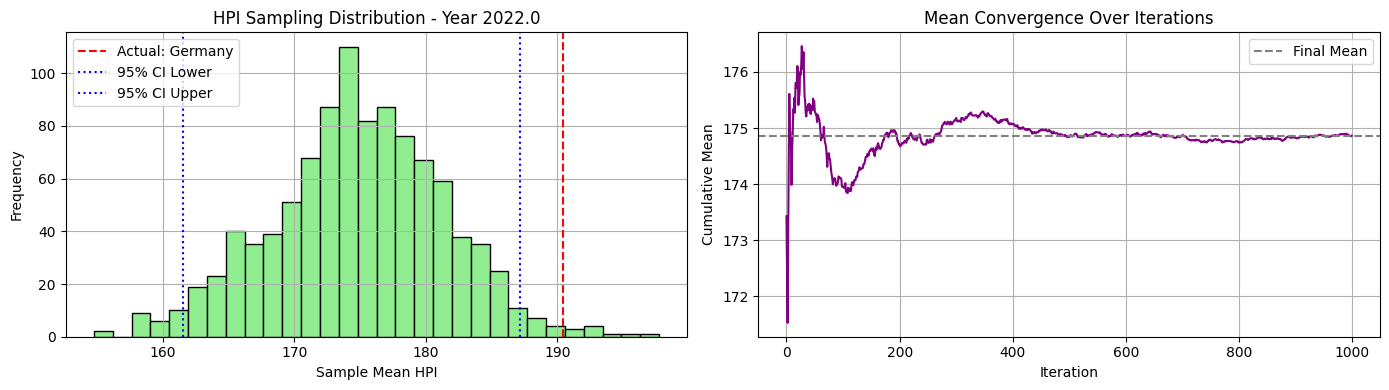

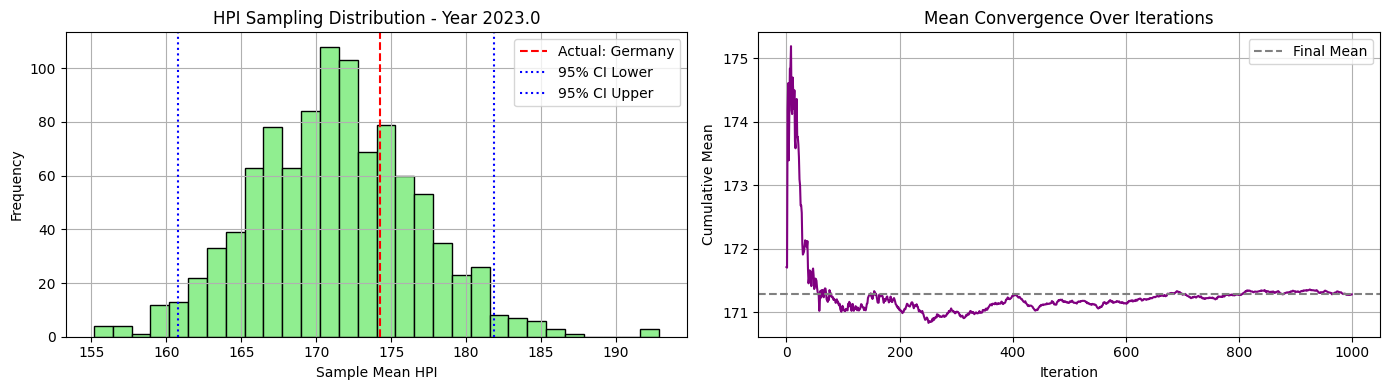

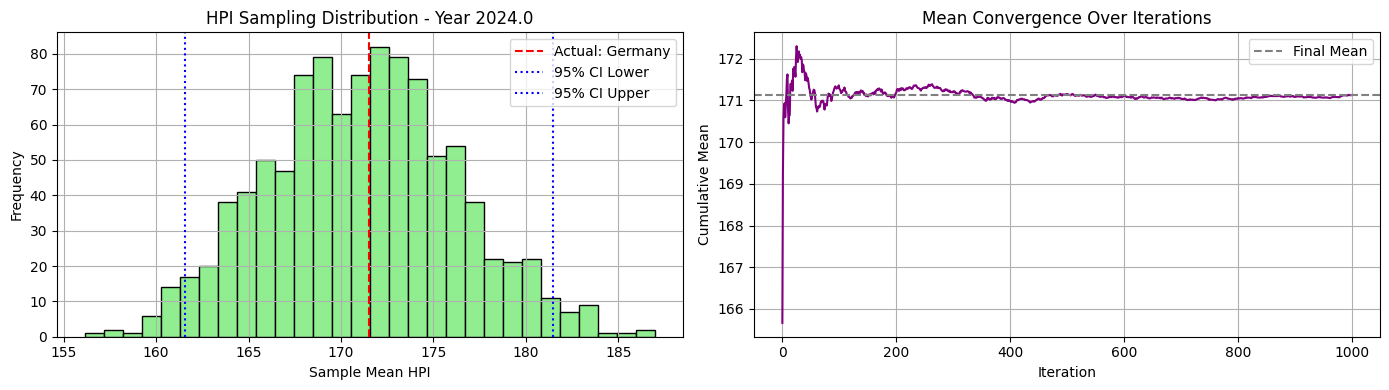

In [69]:
avg_mse_01, avg_mae_01, best_country_01, yearly_bootstrap_means_01, yearly_mean_01 = evaluate_cluster_sampling_errors(df_hpi_winsorized, df_clusters=df_continet, cluster_id="Western Europe", cluster_column="UNregion", start_year=2016)

In [55]:
df_continet[df_continet["UNregion"]=="South America"]

,PC1,PC2,cluster,Country,ISO_A3,Continent,UNregion
3,9.370254,-1.189187,1,Brazil,BRA,America,South America
6,11.313440,-3.520124,1,Chile,CHL,America,South America
7,12.057846,-5.641059,1,Colombia,COL,America,South America
32,10.529278,-8.589597,1,Paraguay,PRY,America,South America
33,-3.223028,-1.718274,0,Peru,PER,America,South America


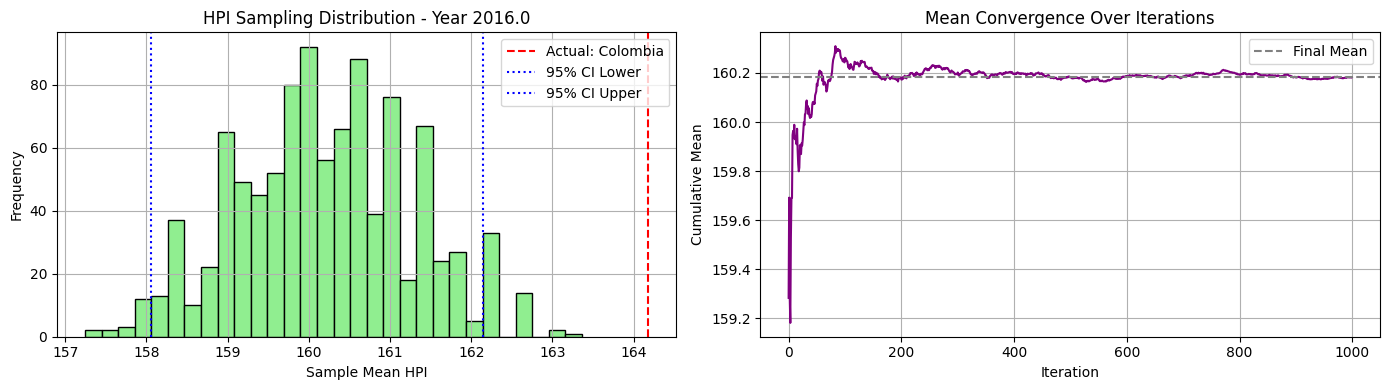

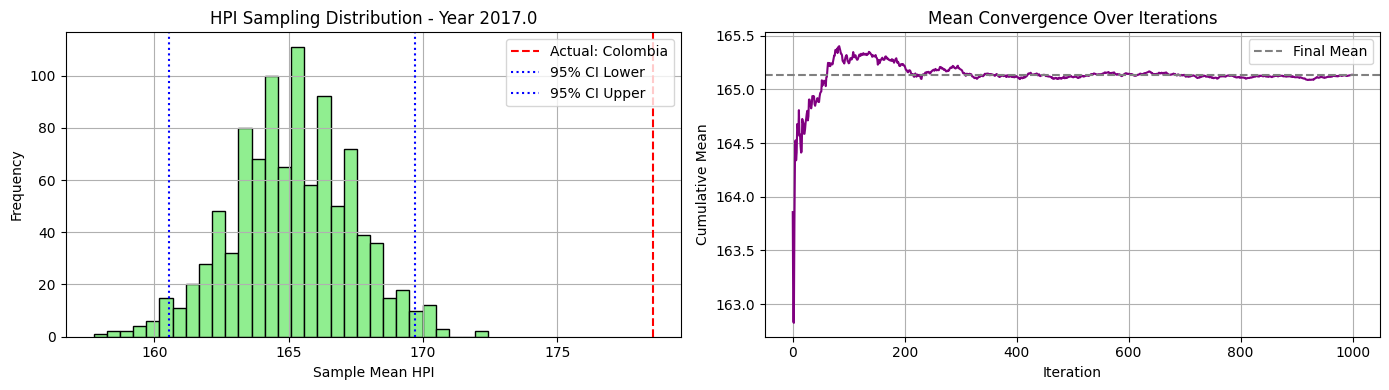

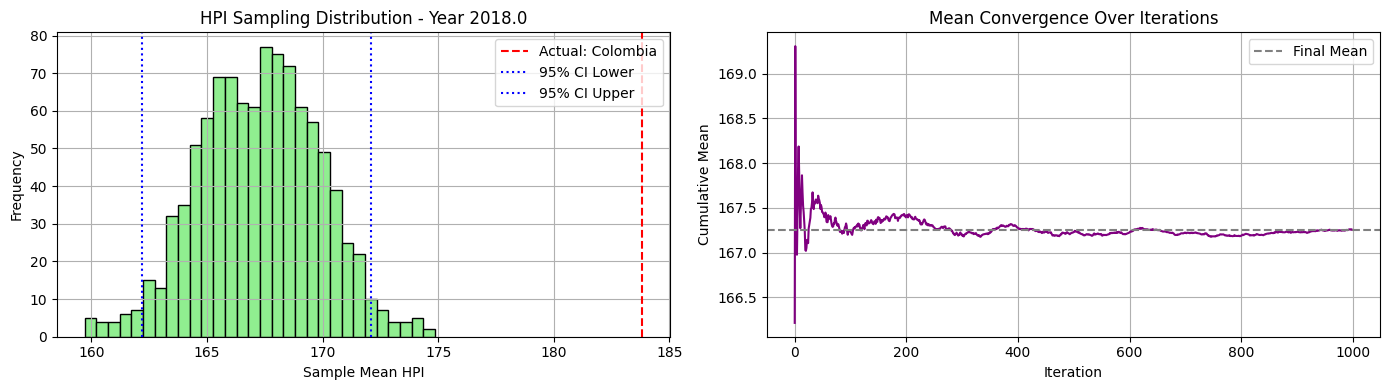

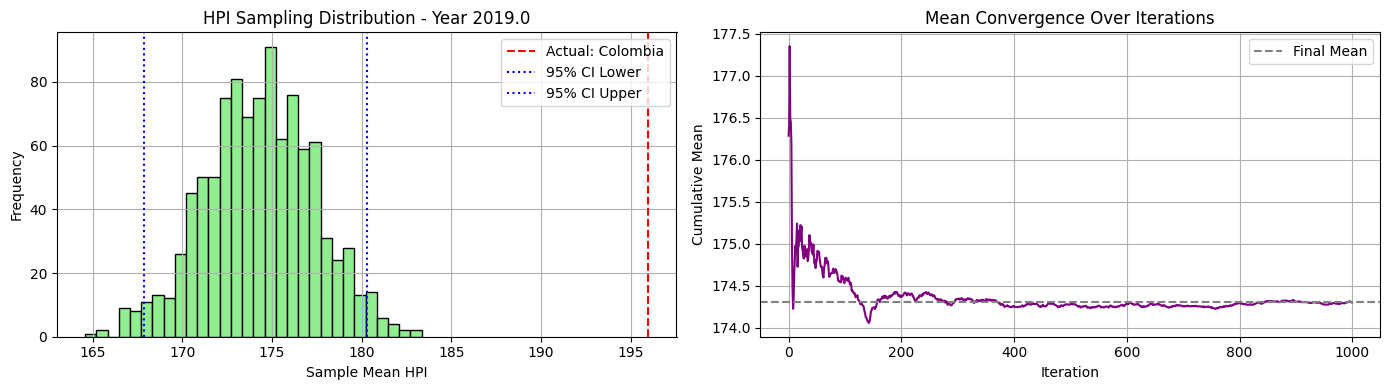

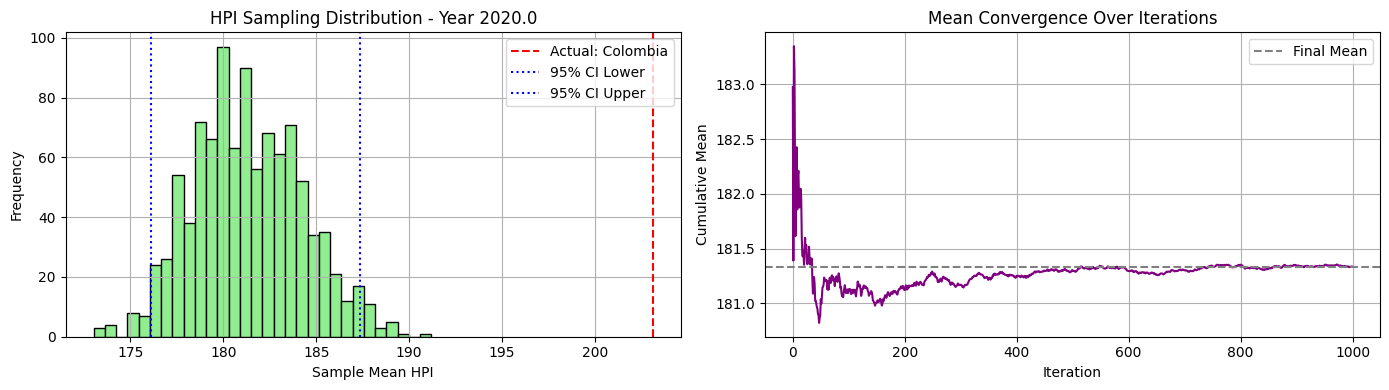

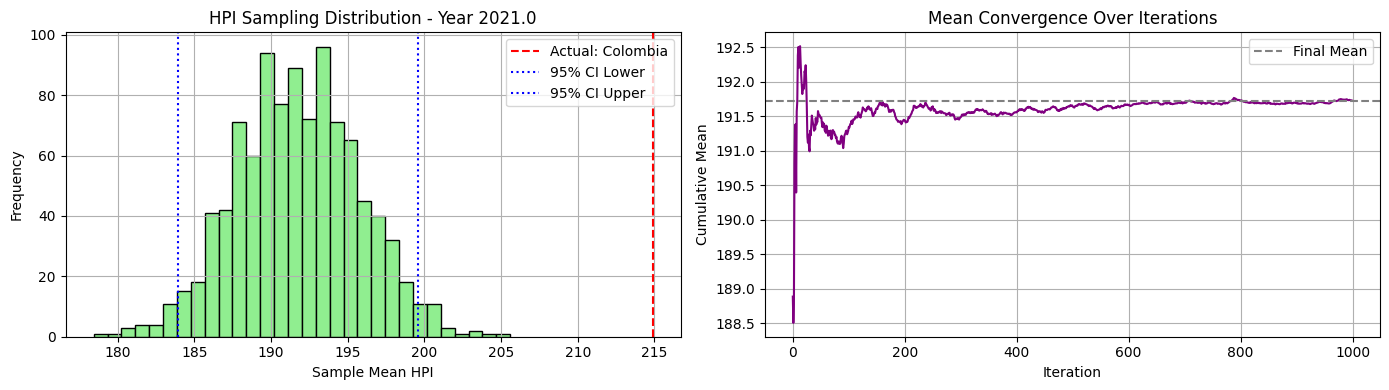

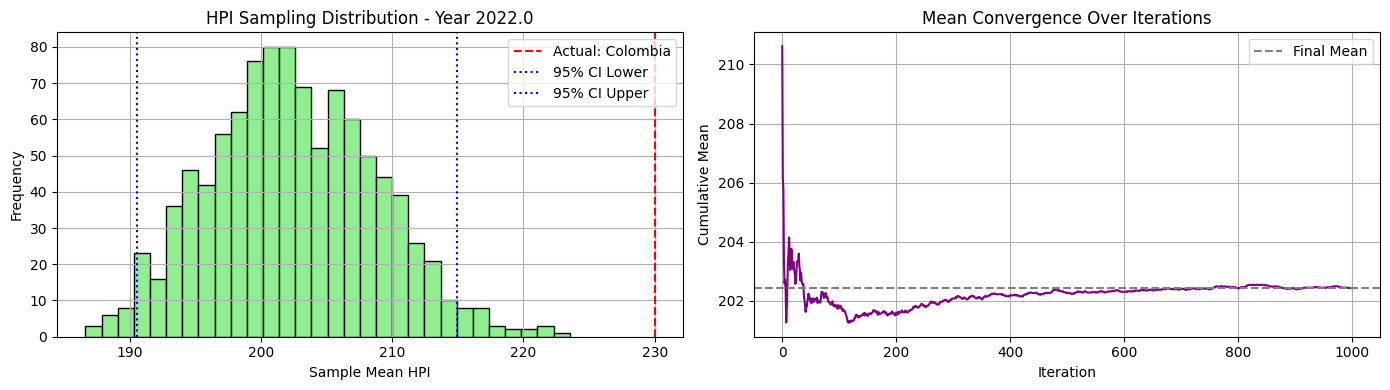

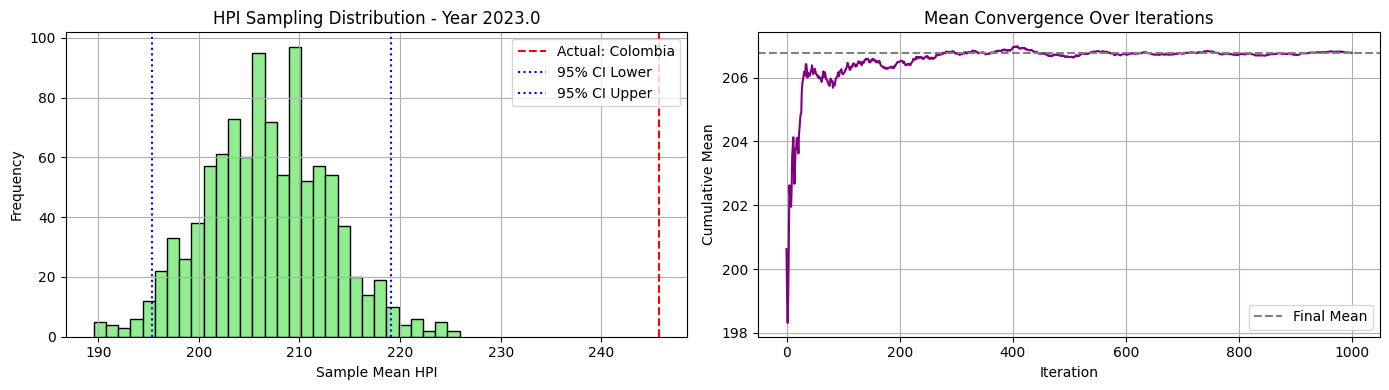

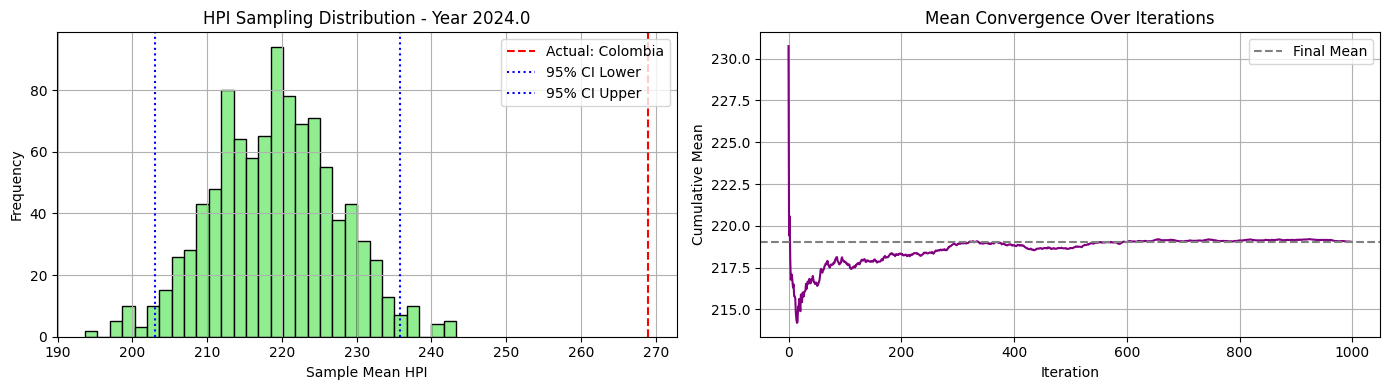

In [85]:
avg_mse_02, avg_mae_02, best_country_02, yearly_bootstrap_means_02, yearly_mean_02 = evaluate_cluster_sampling_errors(df_hpi_winsorized, df_clusters=df_continet, cluster_id="South America", cluster_column="UNregion", start_year=2016)

In [86]:
df_continet[df_continet["UNregion"]=="Eastern Europe"]

,PC1,PC2,cluster,Country,ISO_A3,Continent,UNregion
4,-10.818940,-1.642285,0,Bulgaria,BGR,Europe,Eastern Europe
10,7.656329,1.924567,1,Czech Republic,CZE,Europe,Eastern Europe
17,10.849171,-5.055863,1,Hungary,HUN,Europe,Eastern Europe
35,3.194950,1.379322,1,Poland,POL,Europe,Eastern Europe
37,-1.920823,-2.860329,0,Romania,ROU,Europe,Eastern Europe
38,13.775198,-0.769284,1,Russia,RUS,Europe,Eastern Europe
41,-12.098298,-2.664210,0,Slovakia,SVK,Europe,Eastern Europe


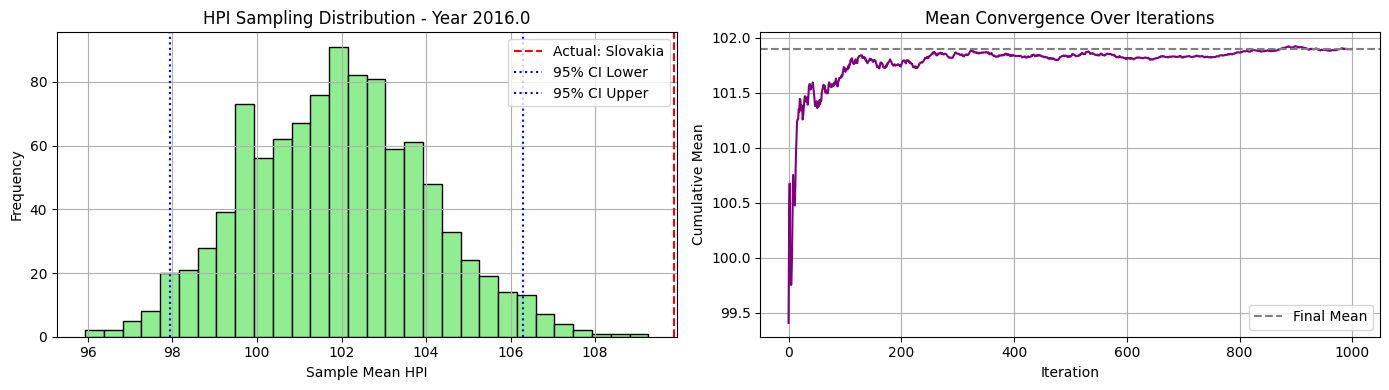

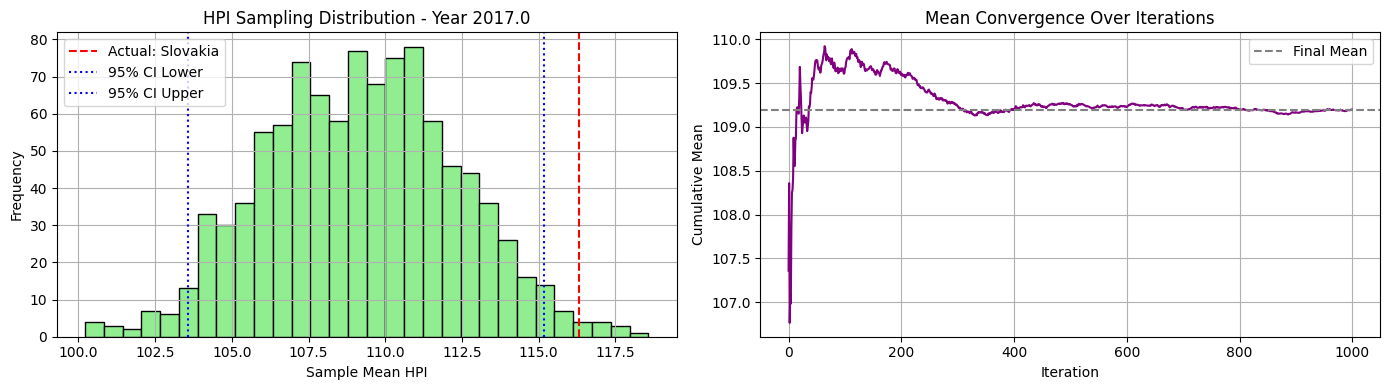

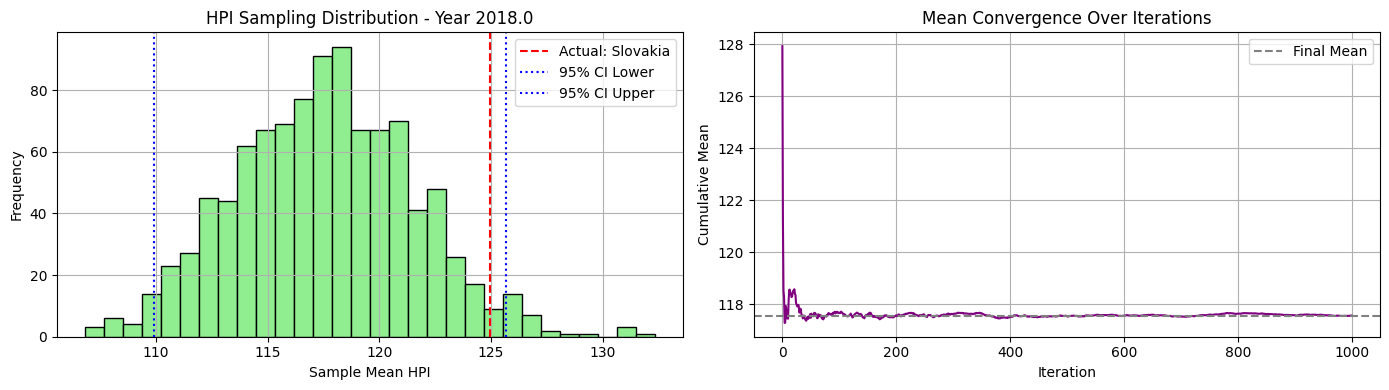

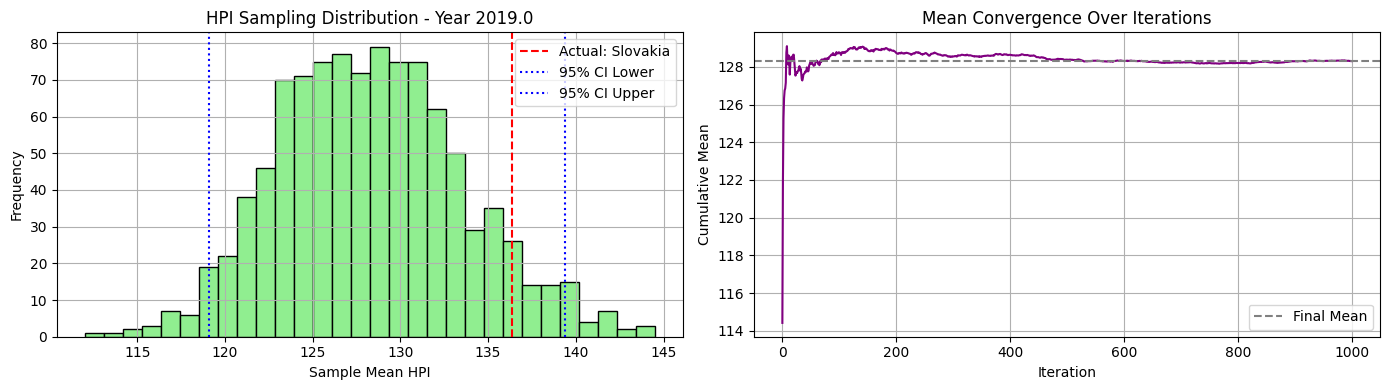

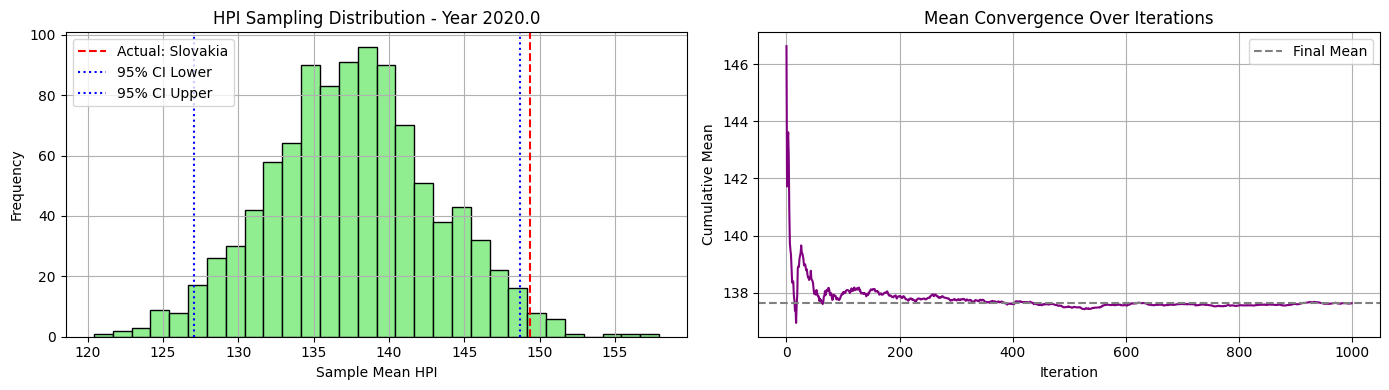

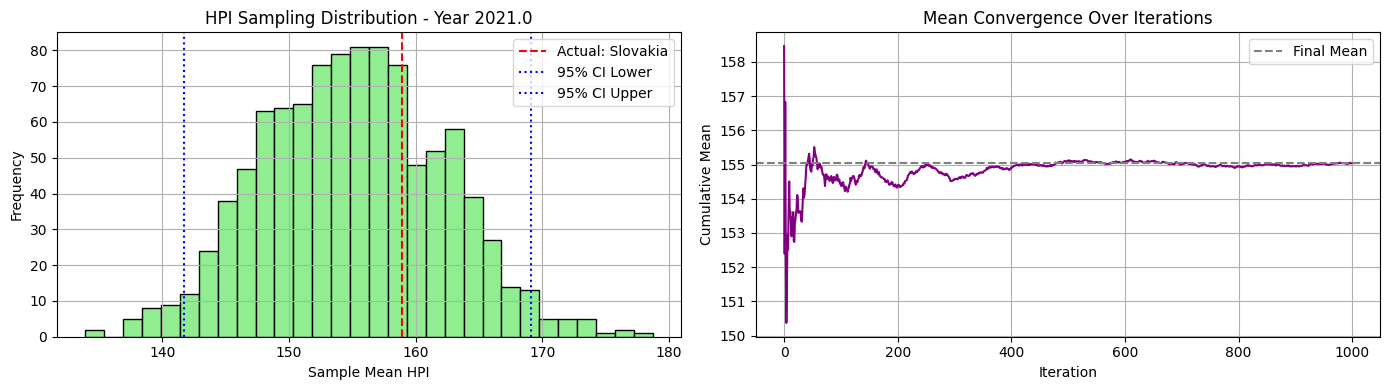

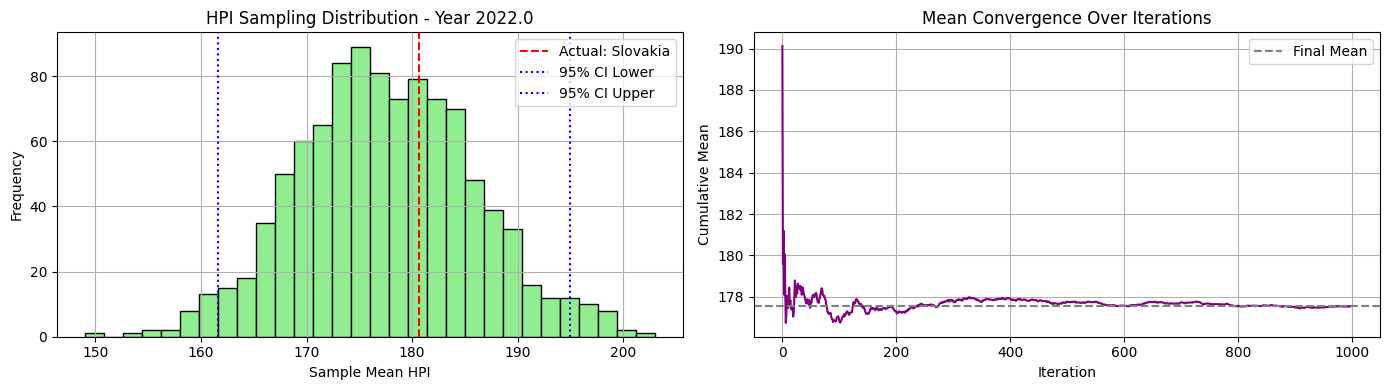

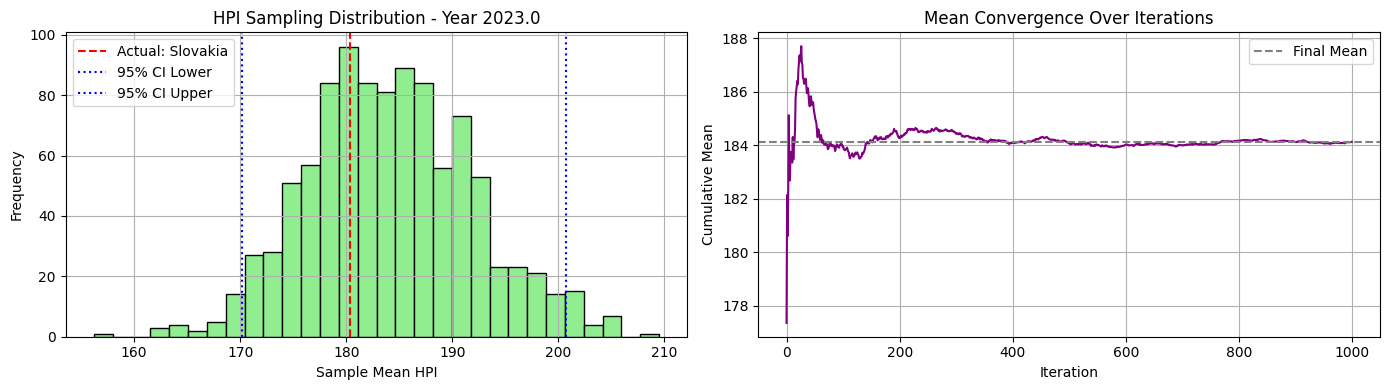

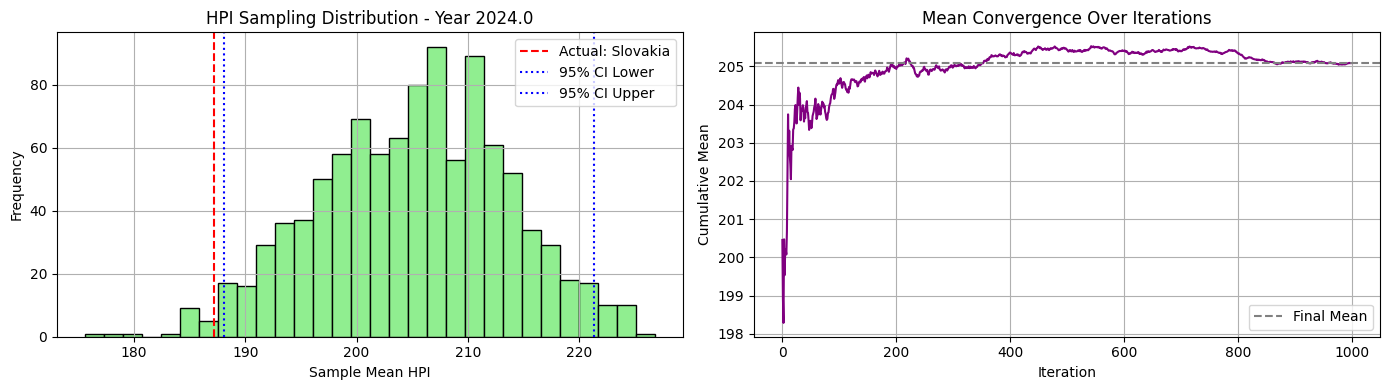

In [72]:
avg_mse_03, avg_mae_03, best_country_03, yearly_bootstrap_means_03, yearly_mean_03 = evaluate_cluster_sampling_errors(df_hpi_winsorized, df_clusters=df_continet, cluster_id="Eastern Europe", cluster_column="UNregion", start_year=2016)

In [57]:
df_continet[df_continet["UNregion"]=="Northern America"]

,PC1,PC2,cluster,Country,ISO_A3,Continent,UNregion
5,3.698850,2.479485,1,Canada,CAN,America,Northern America
50,12.188211,0.558488,1,USA,USA,America,Northern America


In [58]:
df_continet[df_continet["UNregion"]=="Central America"]

,PC1,PC2,cluster,Country,ISO_A3,Continent,UNregion
28,12.503979,-2.837293,1,Mexico,MEX,America,Central America


In [61]:
df_continet.loc[df_continet["ISO_A3"] == "MEX", "UNregion"] = "Northern America"

In [62]:
df_continet[df_continet["UNregion"]=="Northern America"]

,PC1,PC2,cluster,Country,ISO_A3,Continent,UNregion
5,3.698850,2.479485,1,Canada,CAN,America,Northern America
28,12.503979,-2.837293,1,Mexico,MEX,Northern America,Northern America
50,12.188211,0.558488,1,USA,USA,America,Northern America


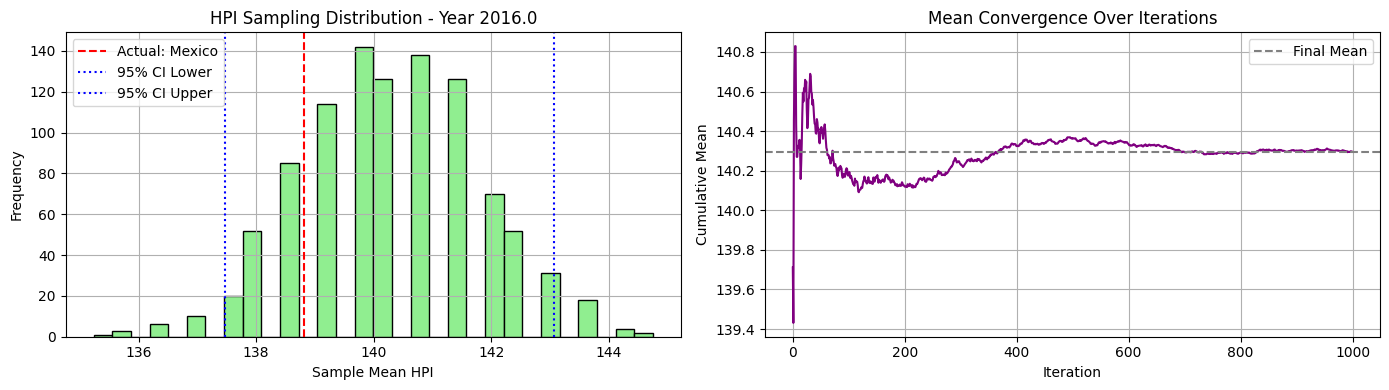

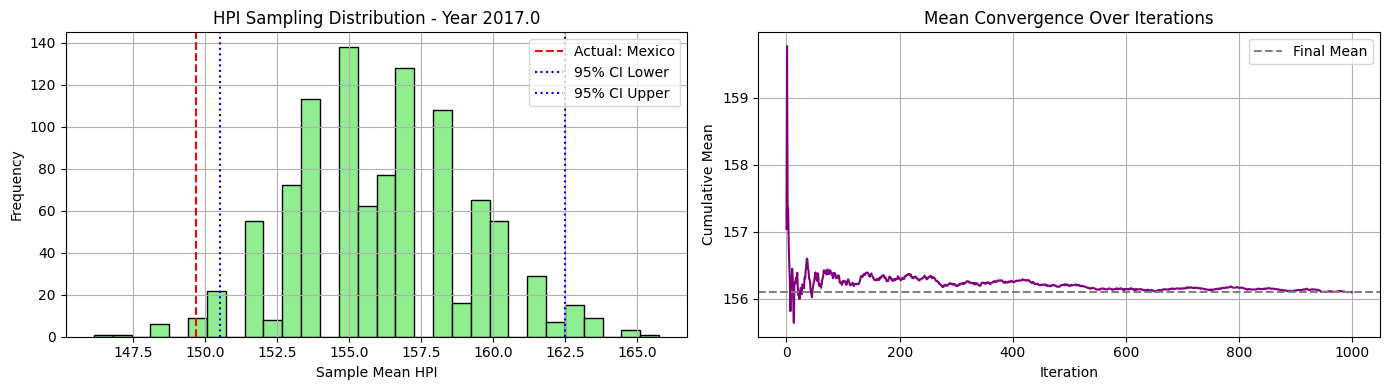

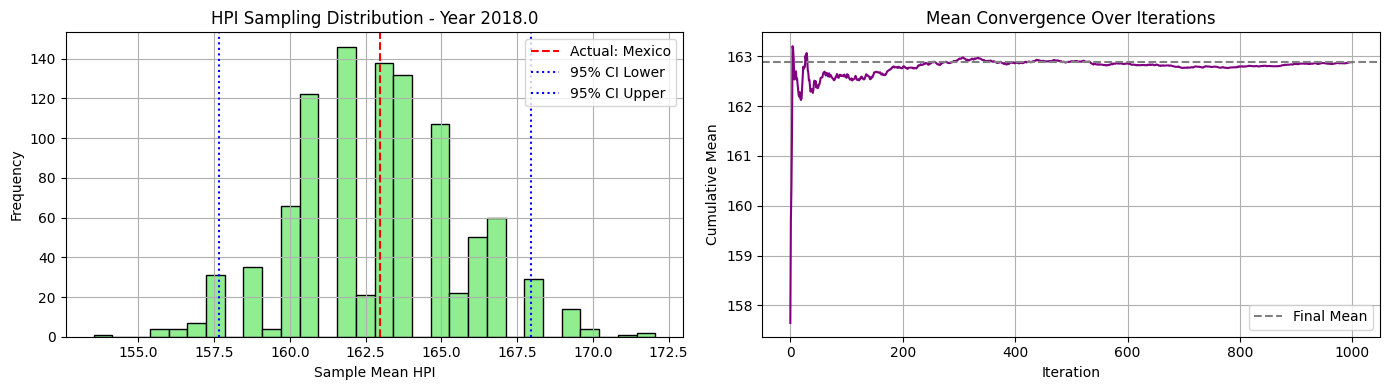

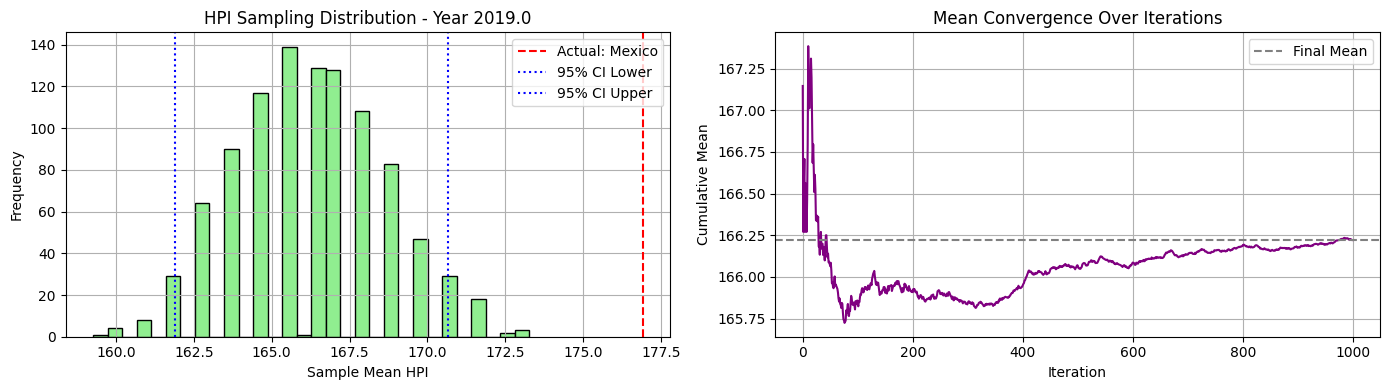

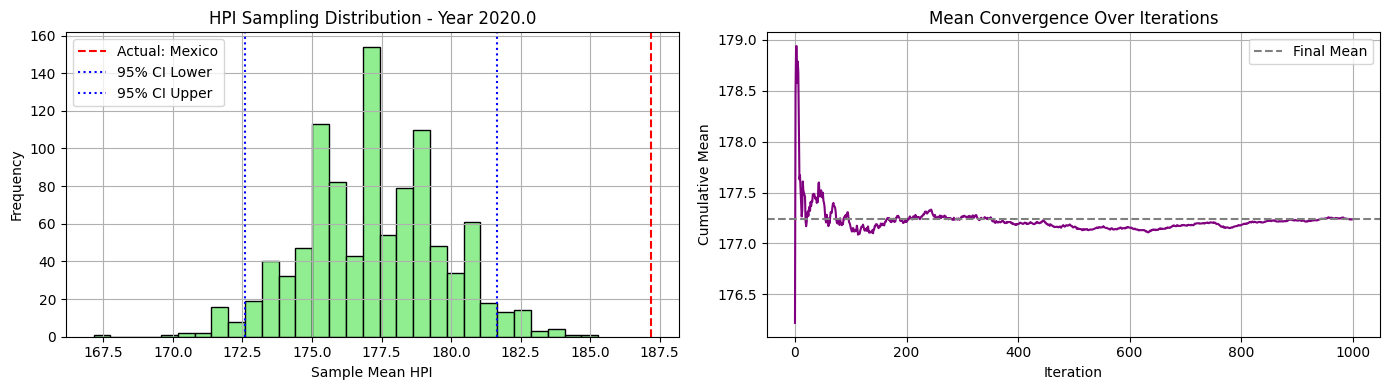

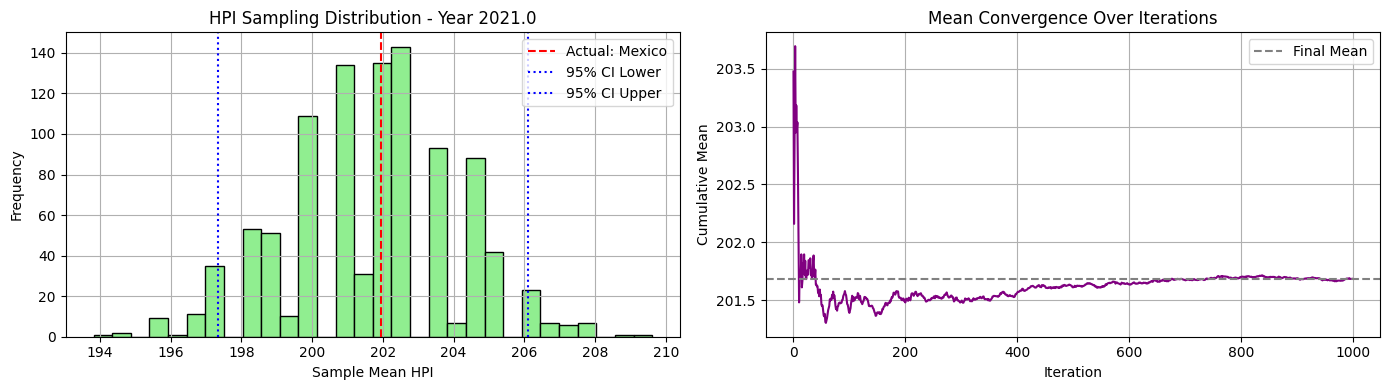

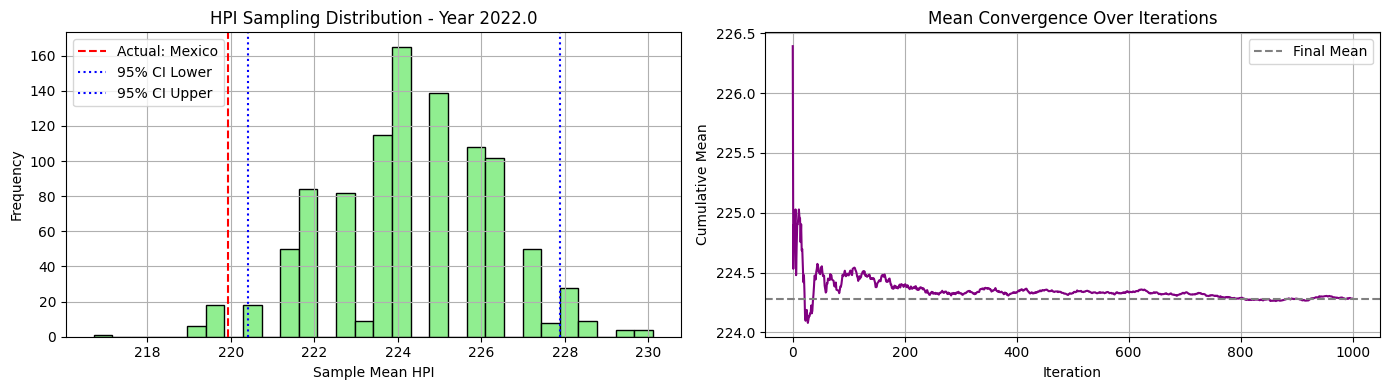

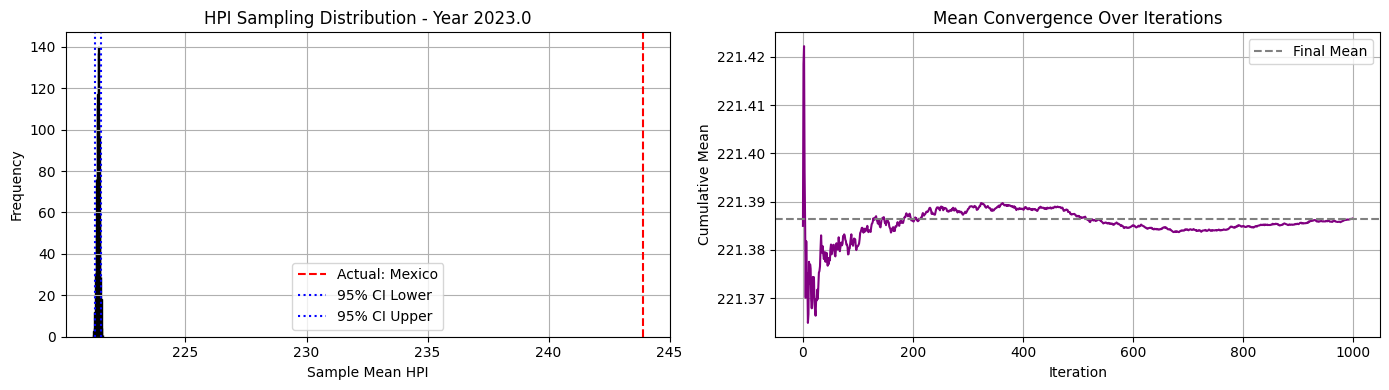

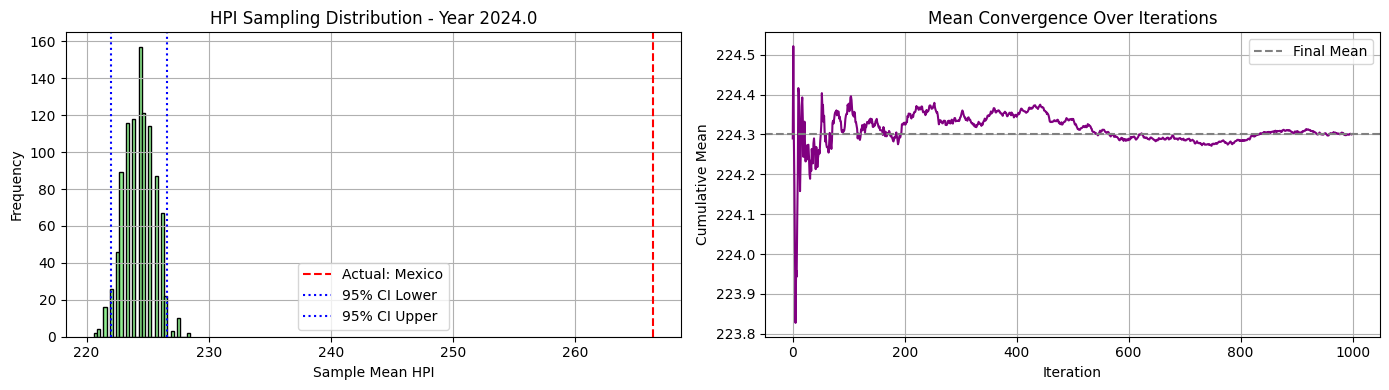

In [76]:
avg_mse_04, avg_mae_04, best_country_04, yearly_bootstrap_means_04, yearly_mean_04 = evaluate_cluster_sampling_errors(df_hpi_winsorized, df_clusters=df_continet, cluster_id="Northern America", cluster_column="UNregion", start_year=2016)

In [38]:
df_continet[df_continet["UNregion"]=="Southern Europe"]

,PC1,PC2,cluster,Country,ISO_A3,Continent,UNregion
8,-12.115571,-2.024072,0,Croatia,HRV,Europe,Southern Europe
16,-11.998487,-3.629059,0,Greece,GRC,Europe,Southern Europe
21,0.463777,0.596509,1,Italy,ITA,Europe,Southern Europe
27,-11.609290,-1.013082,0,Malta,MLT,Europe,Southern Europe
36,-10.684799,-0.239316,0,Portugal,PRT,Europe,Southern Europe
39,5.359881,-6.541855,1,Serbia,SRB,Europe,Southern Europe
42,-12.189767,-1.540384,0,Slovenia,SVN,Europe,Southern Europe
45,-1.284110,0.487111,0,Spain,ESP,Europe,Southern Europe


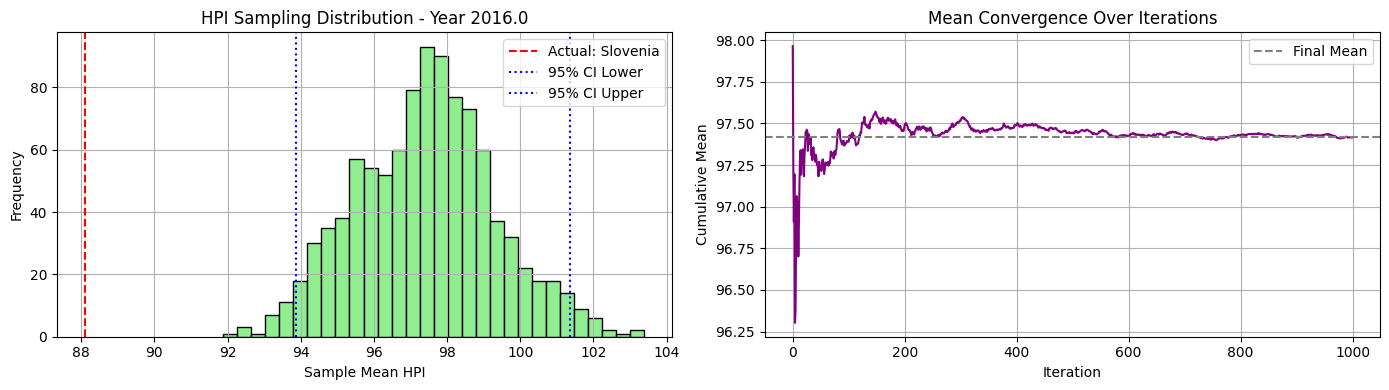

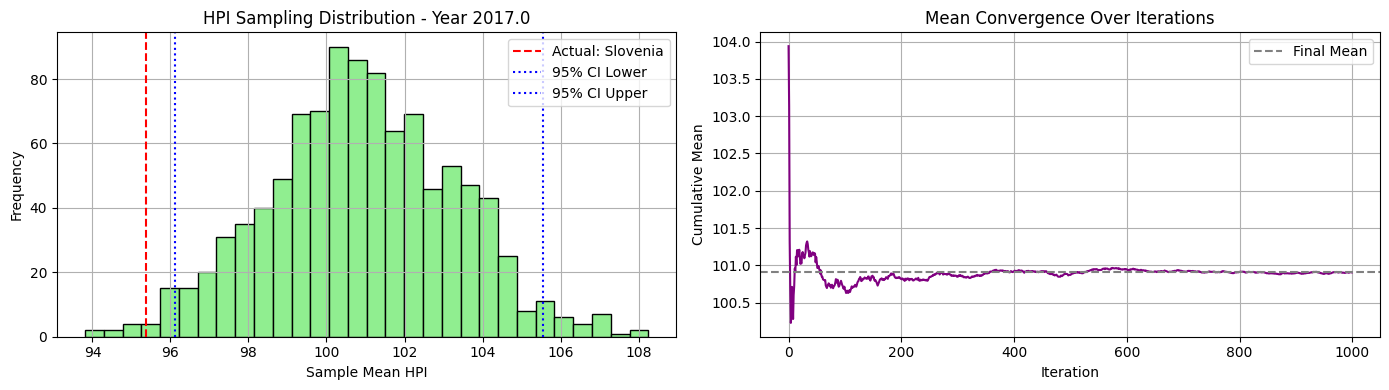

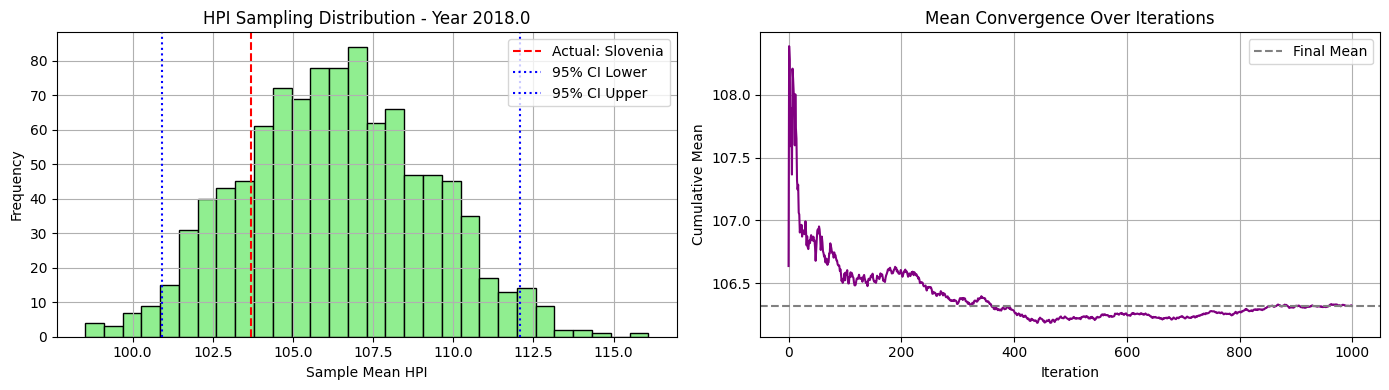

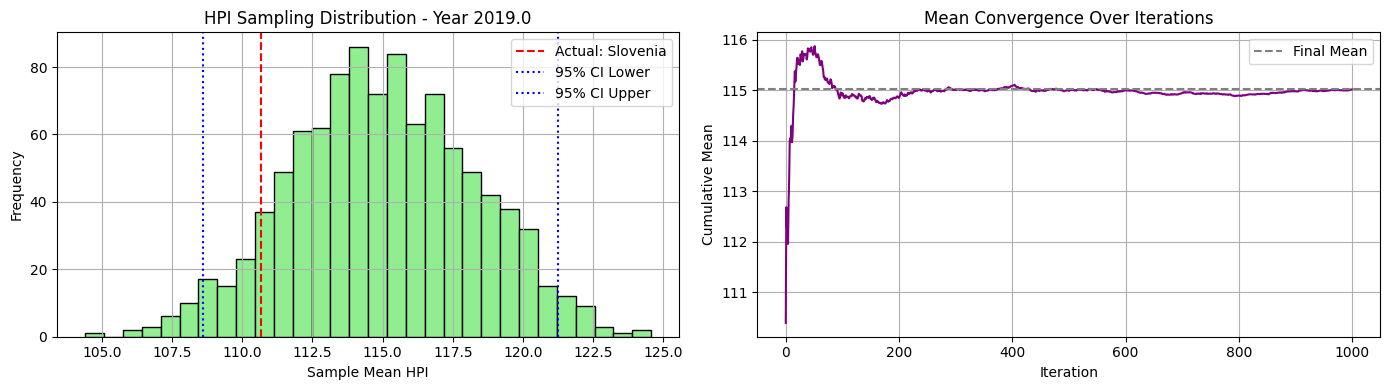

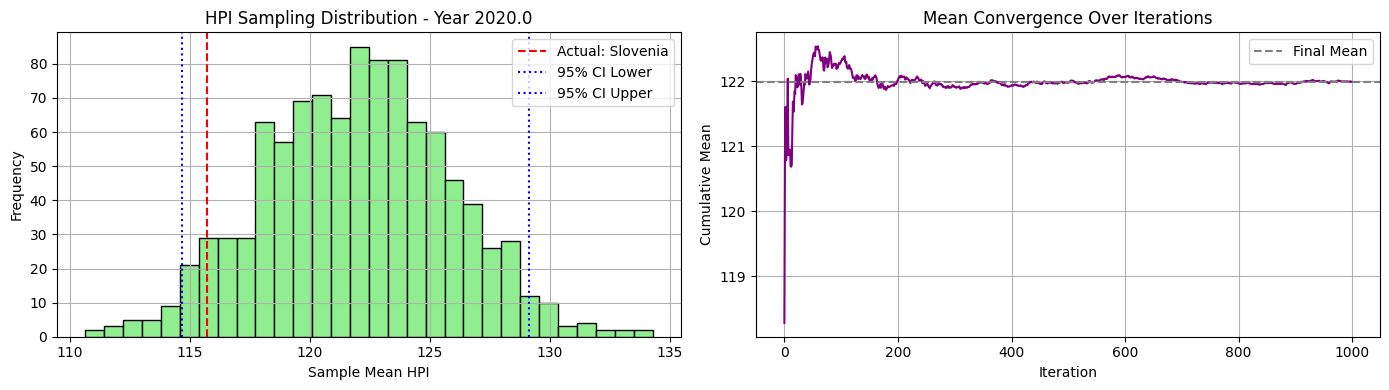

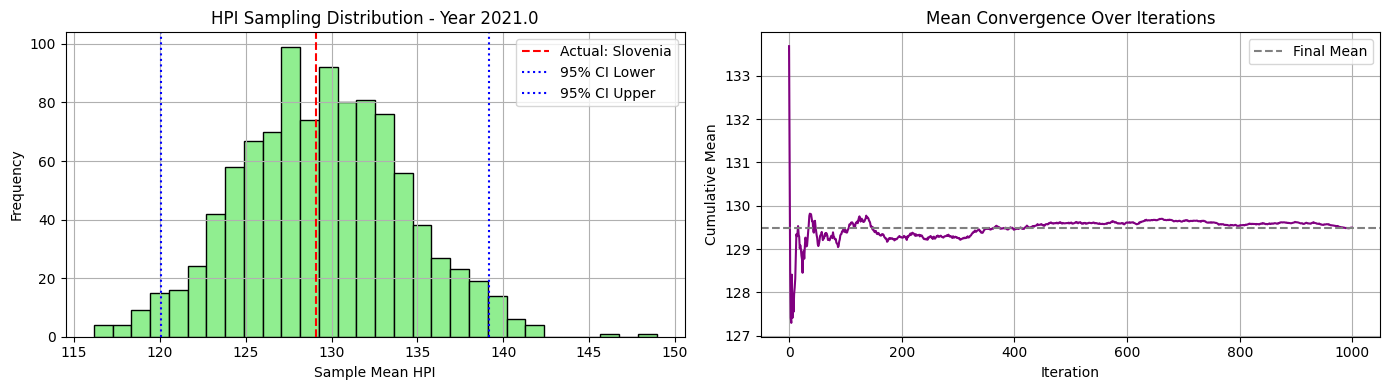

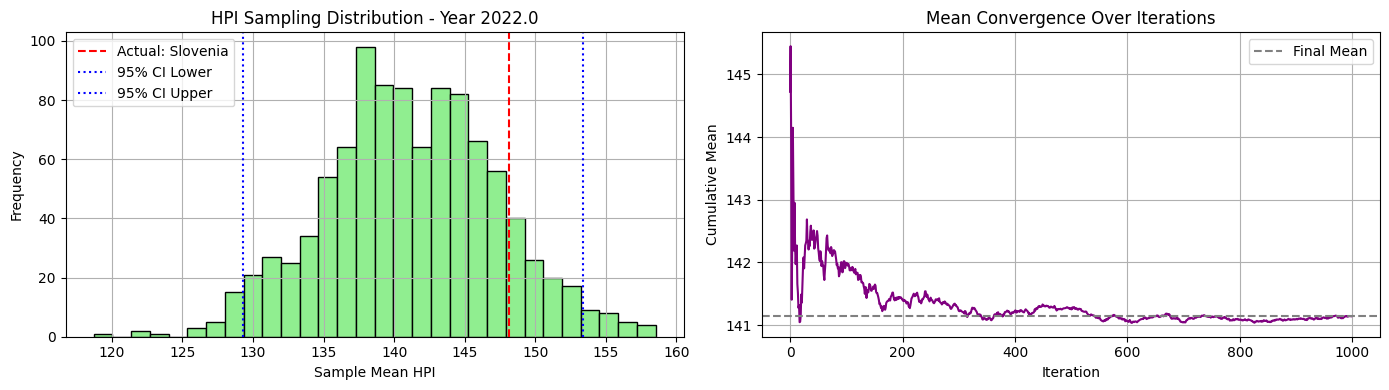

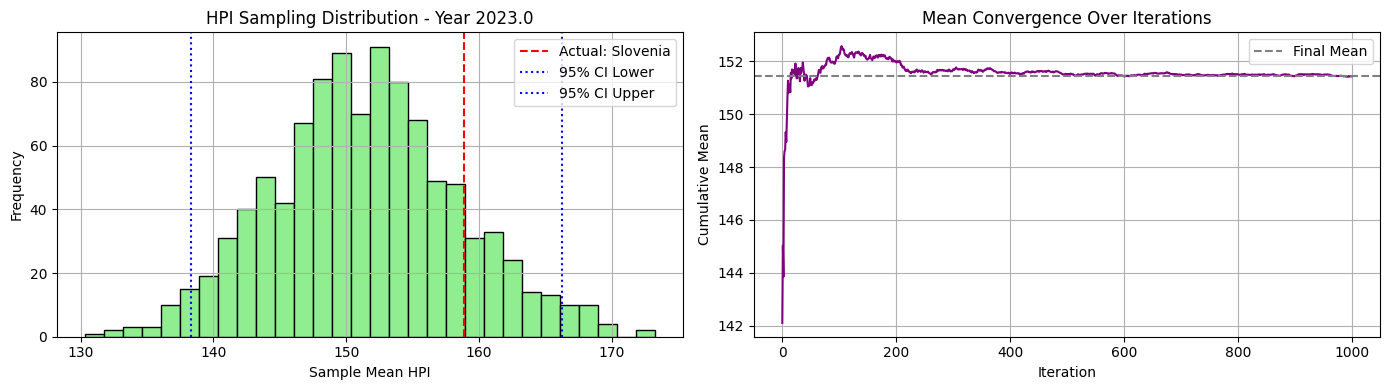

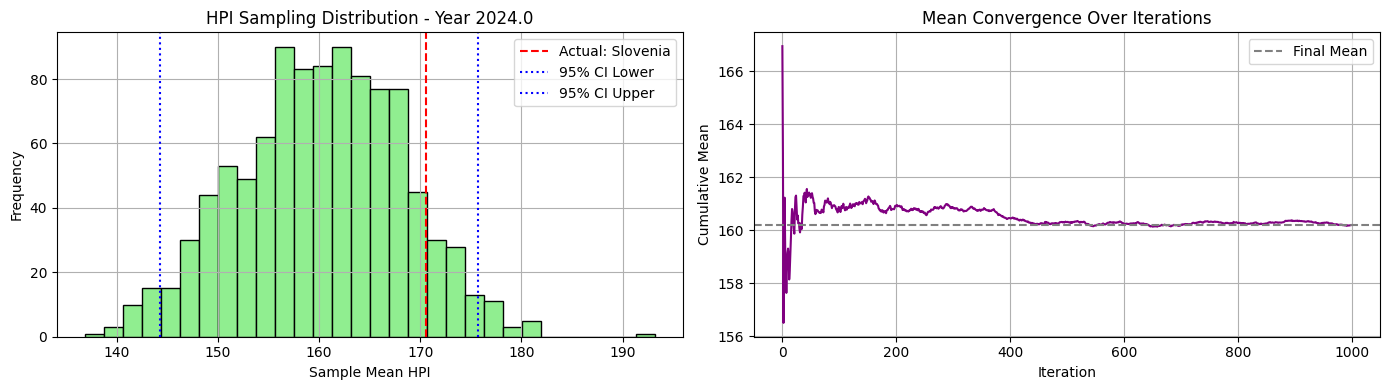

In [77]:
avg_mse_05, avg_mae_05, best_country_05, yearly_bootstrap_means_05, yearly_mean_05 = evaluate_cluster_sampling_errors(df_hpi_winsorized, df_clusters=df_continet, cluster_id="Southern Europe", cluster_column="UNregion", start_year=2016)

In [40]:
df_continet[df_continet["UNregion"]=="Northern Europe"]

,PC1,PC2,cluster,Country,ISO_A3,Continent,UNregion
11,0.831886,4.815845,1,Denmark,DNK,Europe,Northern Europe
12,-12.509577,-0.623108,0,Estonia,EST,Europe,Northern Europe
13,-10.444790,1.013120,0,Finland,FIN,Europe,Northern Europe
18,5.939521,4.952702,1,Iceland,ISL,Europe,Northern Europe
19,-9.084436,-1.973917,0,Ireland,IRL,Europe,Northern Europe
23,-12.524267,-1.347875,0,Latvia,LVA,Europe,Northern Europe
24,-12.360475,-1.801832,0,Lithuania,LTU,Europe,Northern Europe
31,5.964392,4.513662,1,Norway,NOR,Europe,Northern Europe
46,7.288906,4.521602,1,Sweden,SWE,Europe,Northern Europe
49,1.955995,2.908009,1,United Kingdom,GBR,Europe,Northern Europe


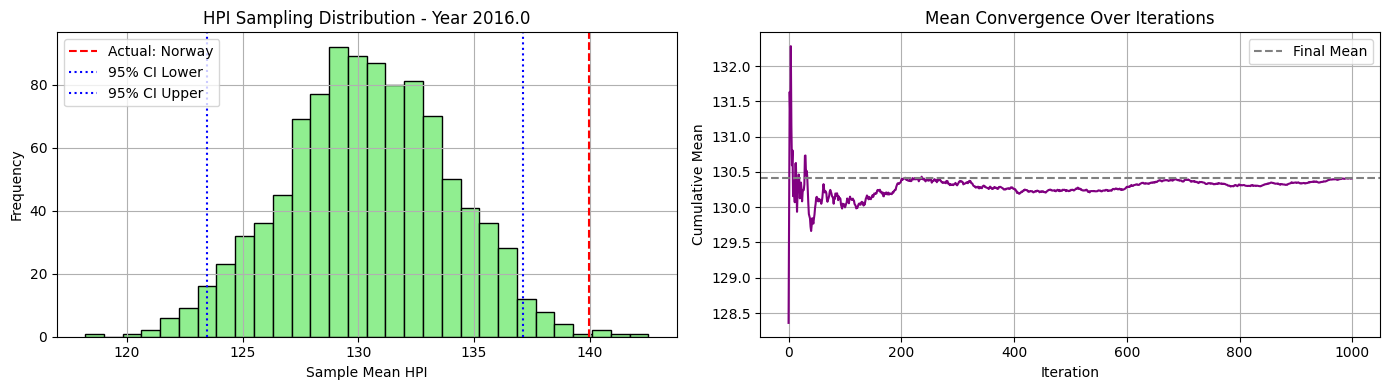

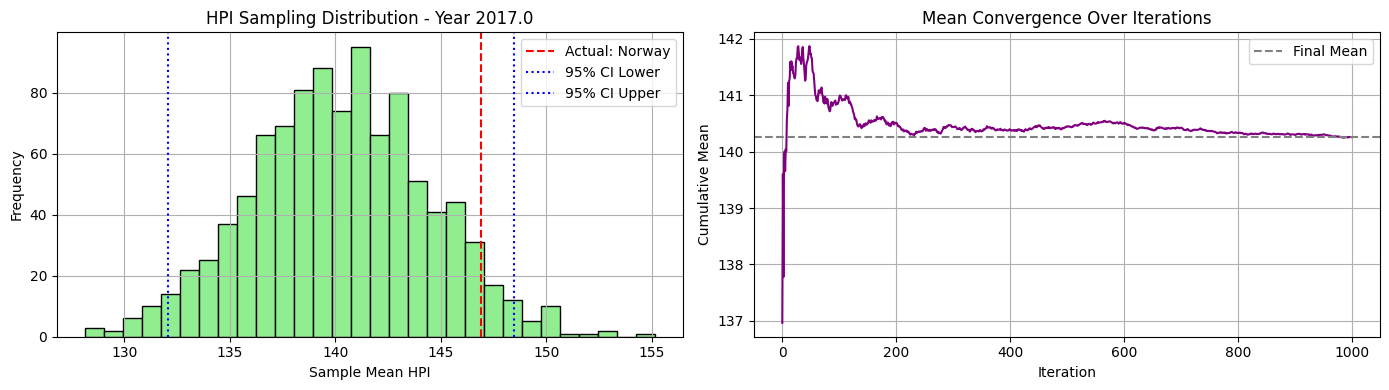

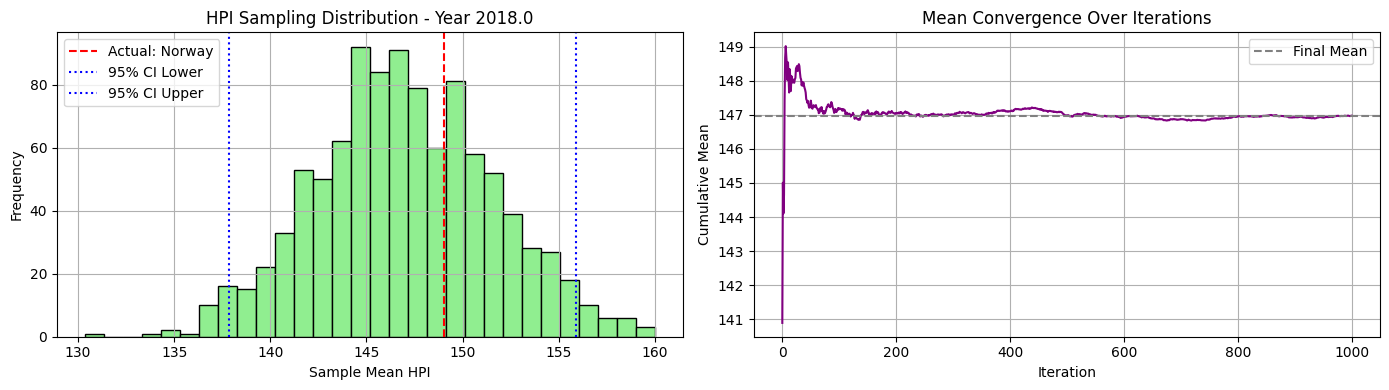

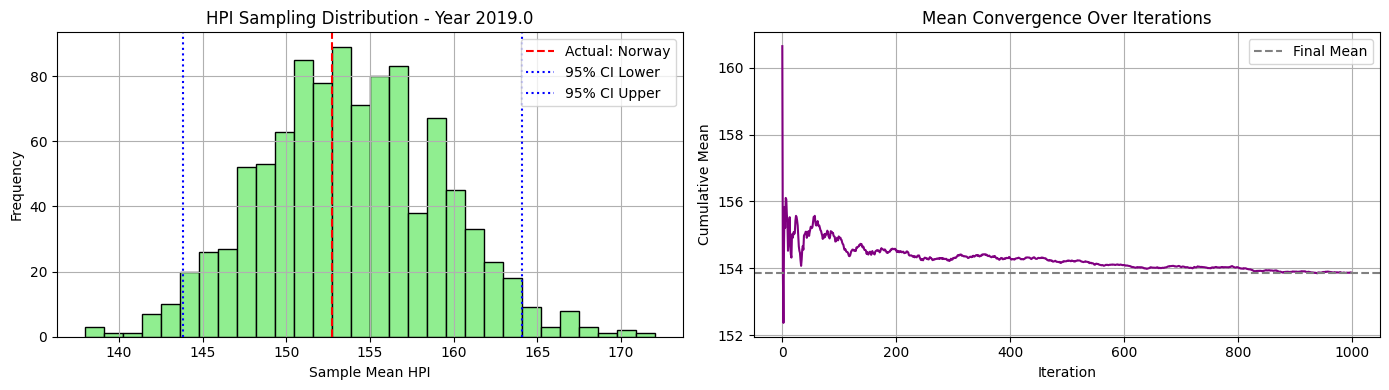

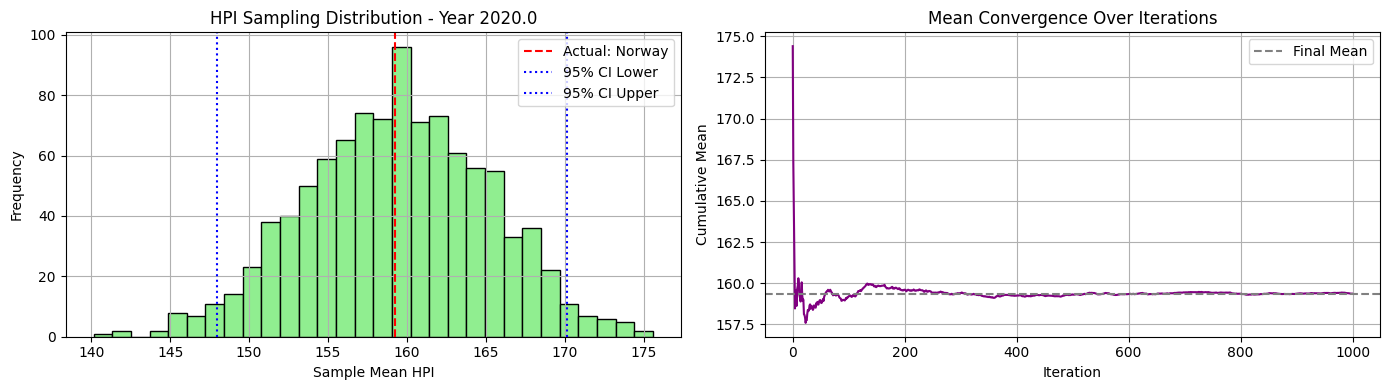

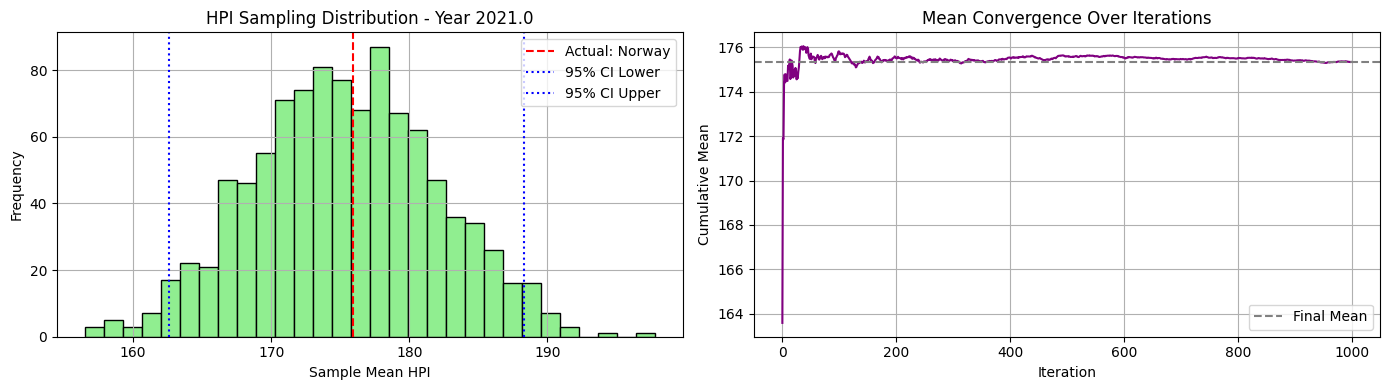

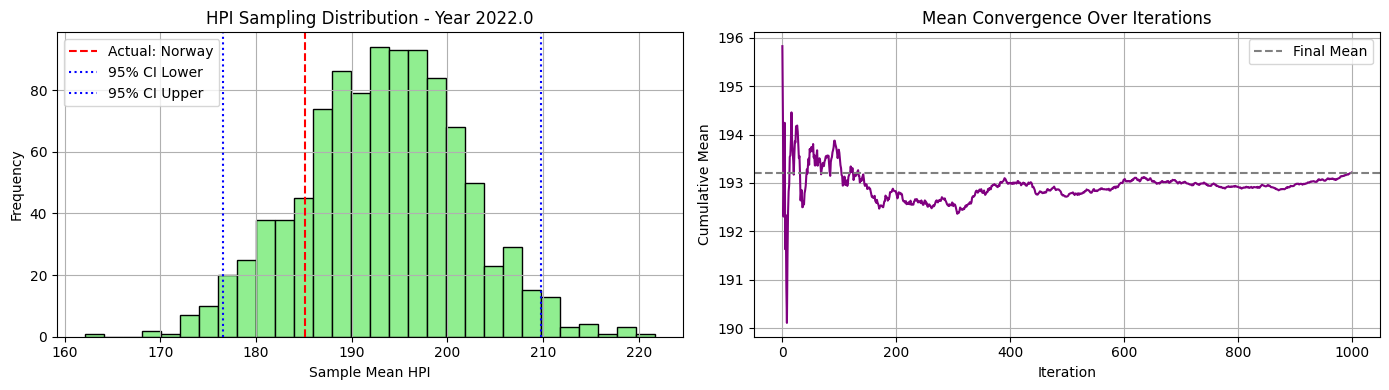

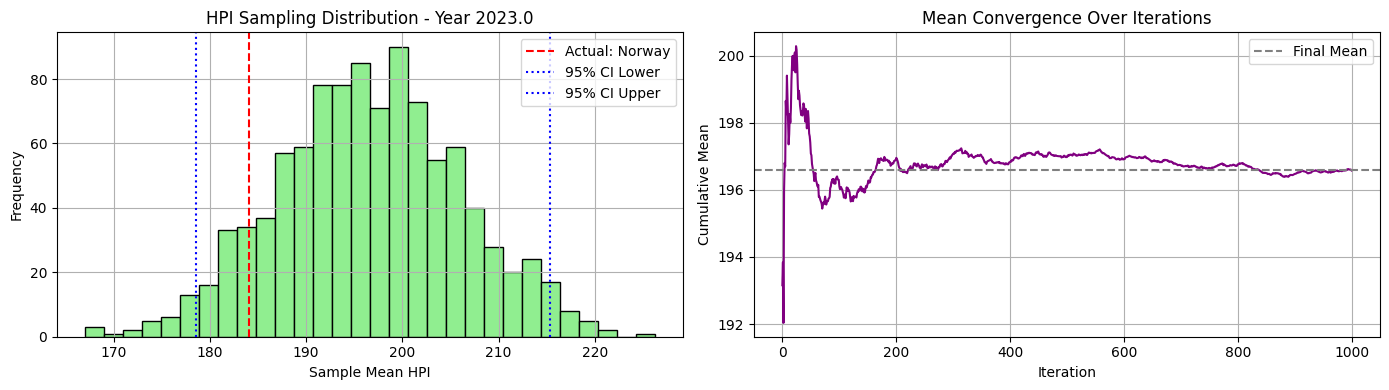

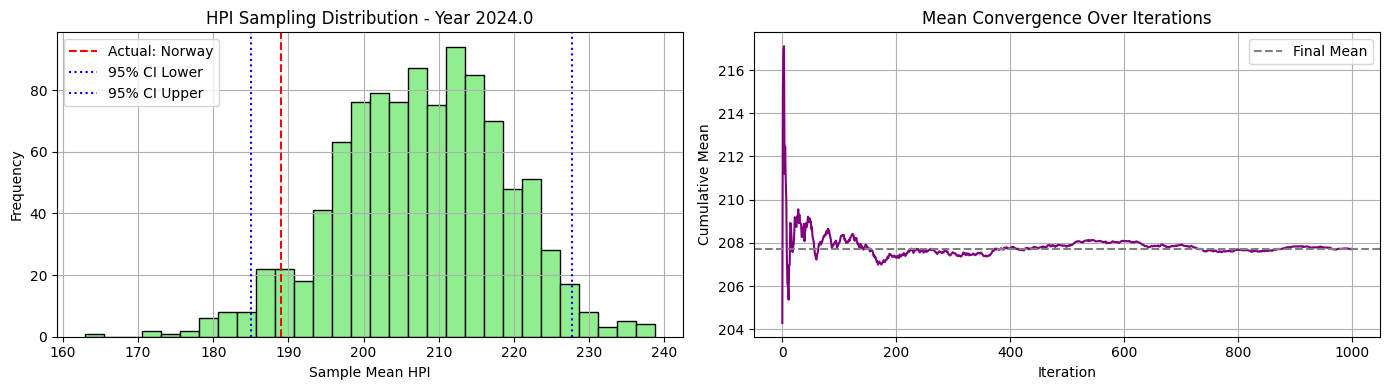

In [78]:
avg_mse_06, avg_mae_06, best_country_06, yearly_bootstrap_means_06, yearly_mean_06 = evaluate_cluster_sampling_errors(df_hpi_winsorized, df_clusters=df_continet, cluster_id="Northern Europe", cluster_column="UNregion", start_year=2016)

In [39]:
df_continet[df_continet["UNregion"]=="Western Asia"]

,PC1,PC2,cluster,Country,ISO_A3,Continent,UNregion
9,-12.524878,-1.895969,0,Cyprus,CYP,Asia,Western Asia
20,0.112871,2.014085,1,Israel,ISR,Asia,Western Asia


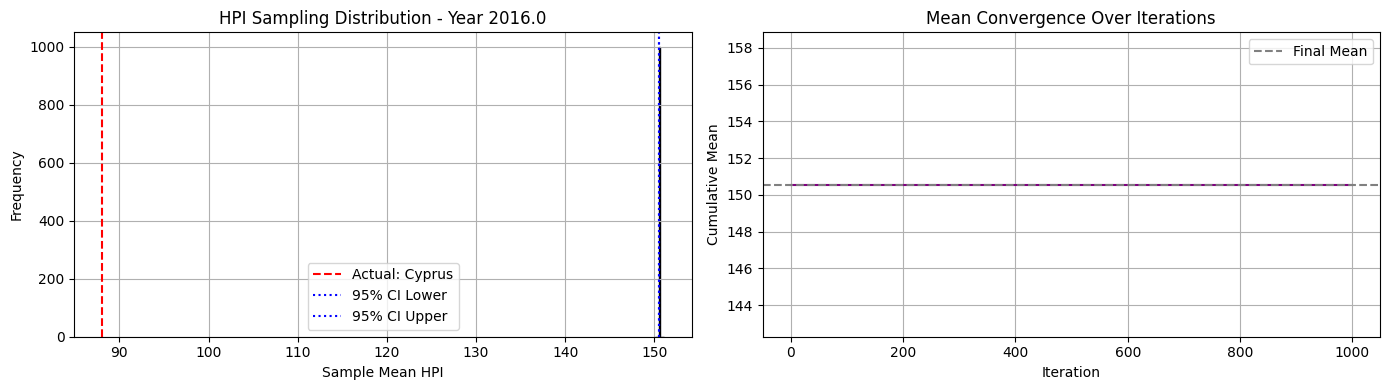

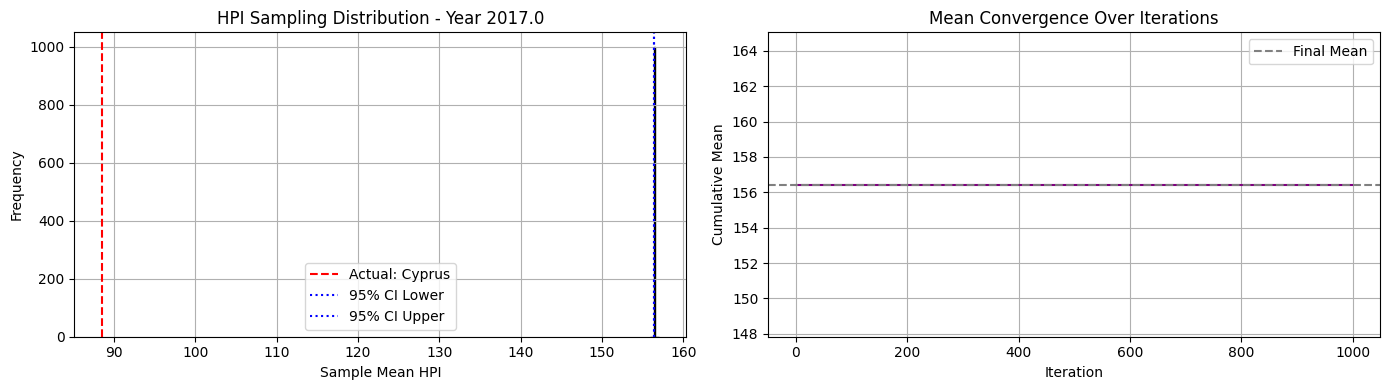

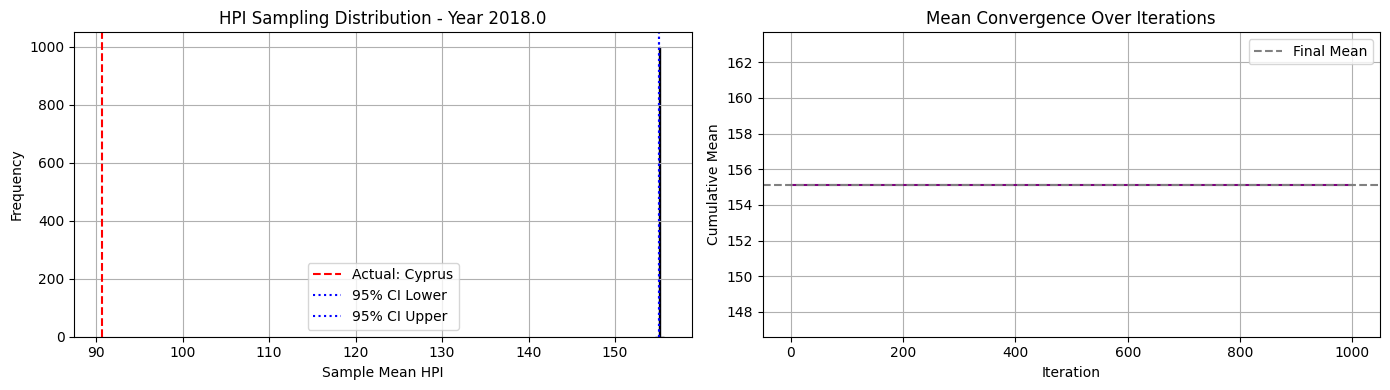

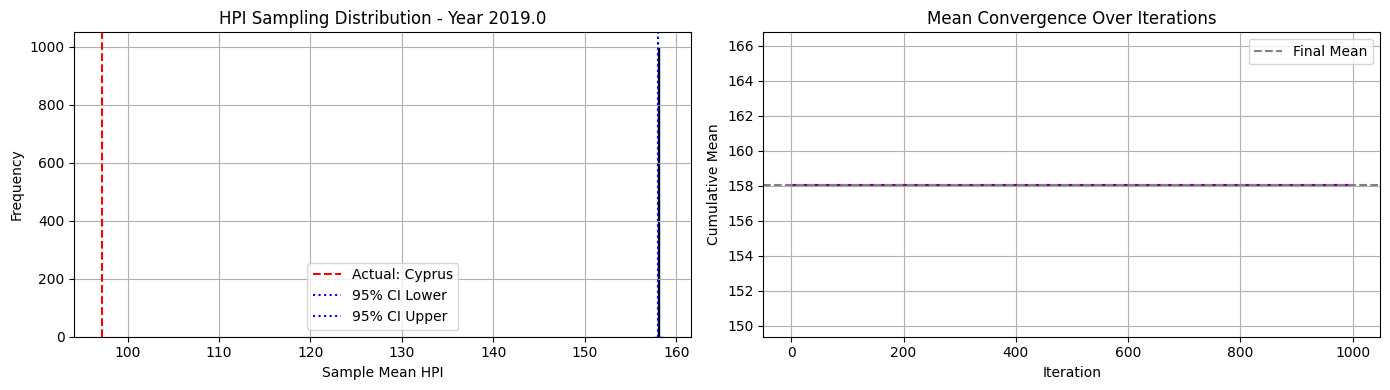

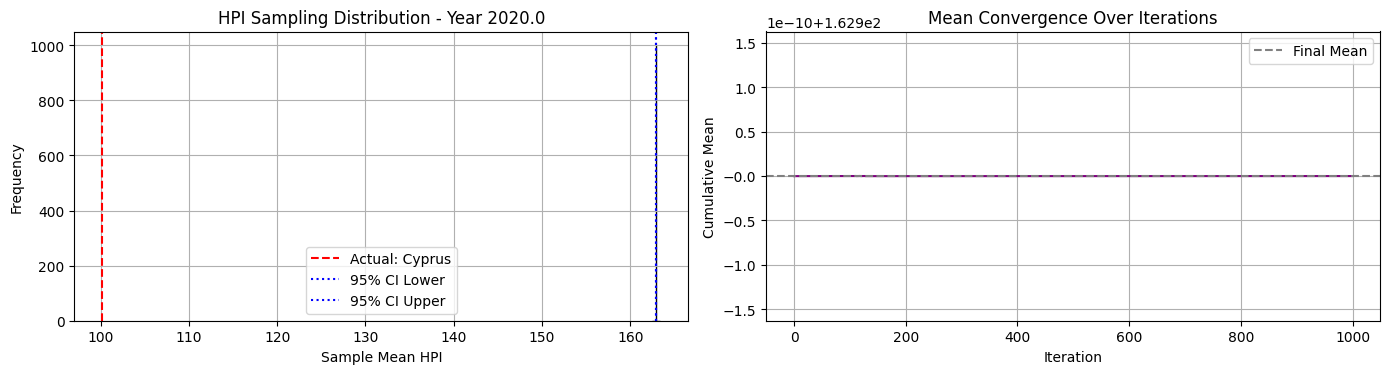

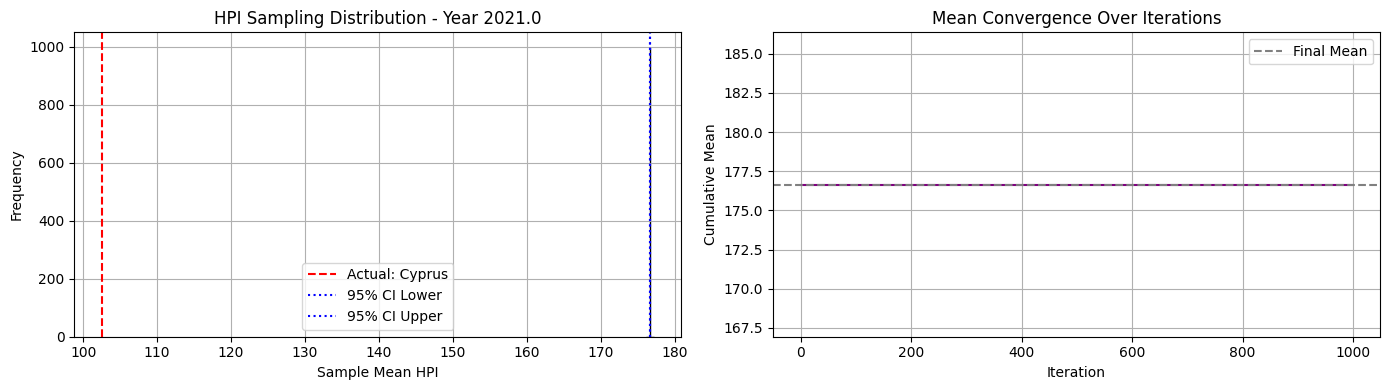

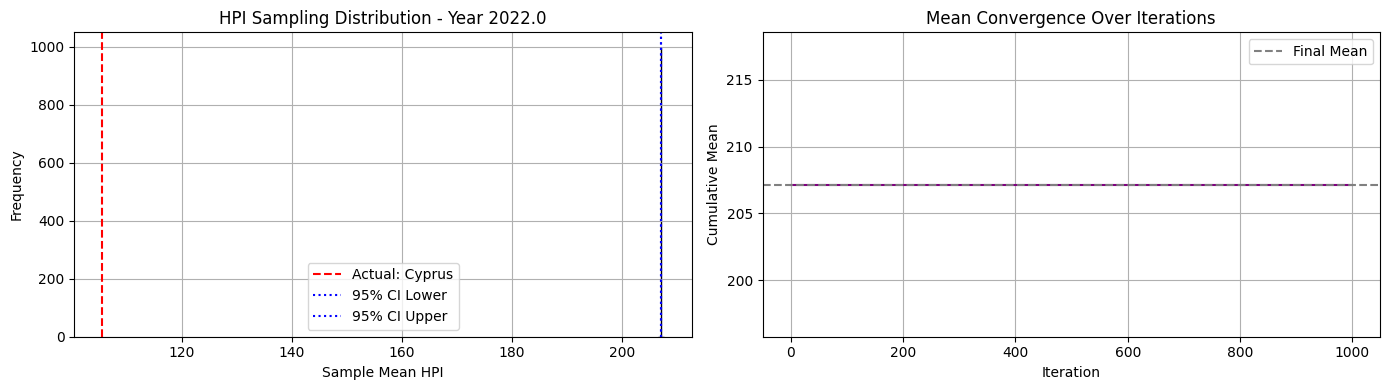

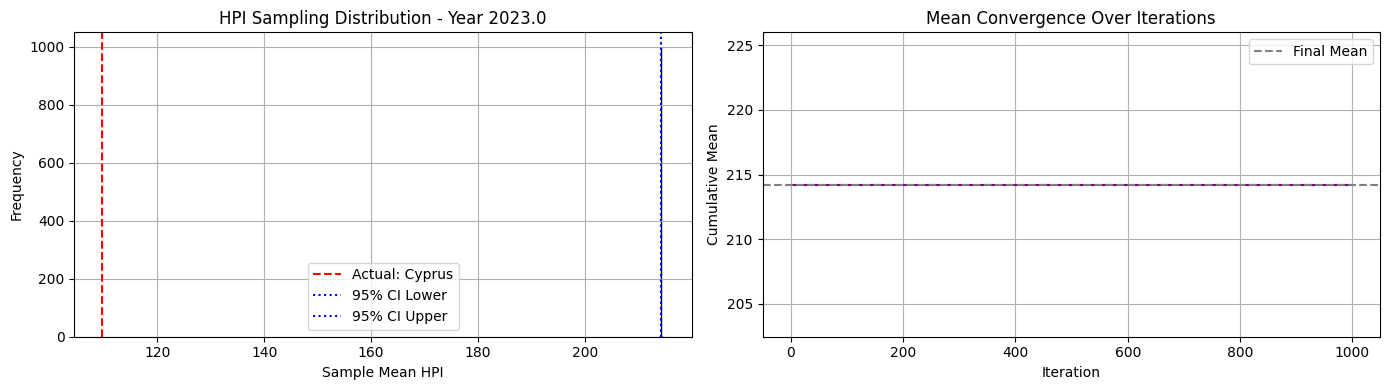

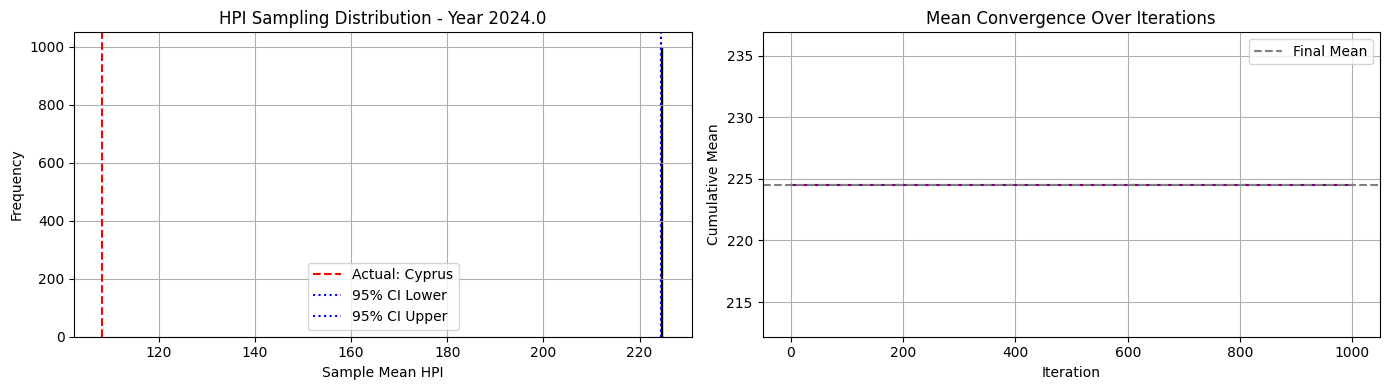

In [79]:
avg_mse_07, avg_mae_07, best_country_07, yearly_bootstrap_means_07, yearly_mean_07 = evaluate_cluster_sampling_errors(df_hpi_winsorized, df_clusters=df_continet, cluster_id="Western Asia", cluster_column="UNregion", start_year=2016)

In [41]:
df_continet[df_continet["UNregion"]=="Eastern Asia"]

,PC1,PC2,cluster,Country,ISO_A3,Continent,UNregion
22,13.302636,3.387087,1,Japan,JPN,Asia,Eastern Asia
44,13.066557,1.732150,1,South Korea,KOR,Asia,Eastern Asia


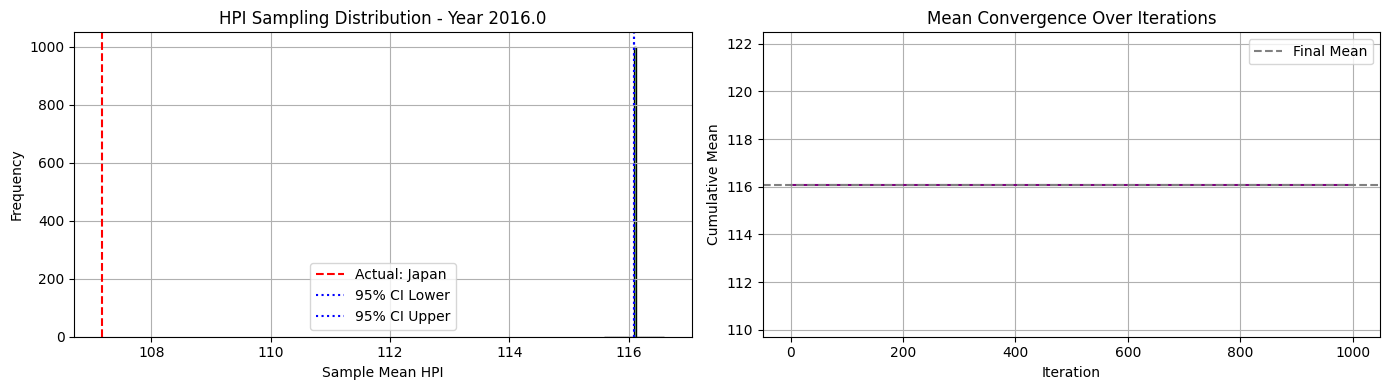

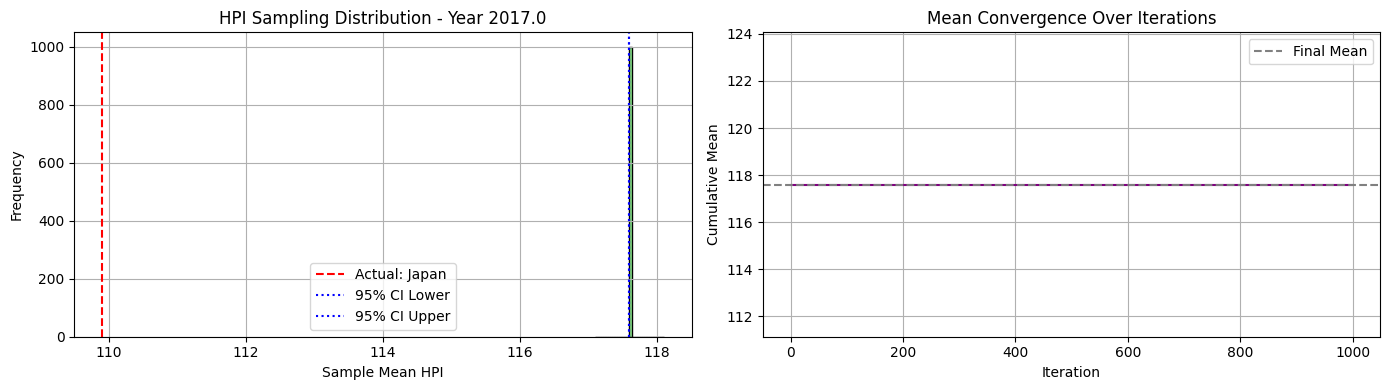

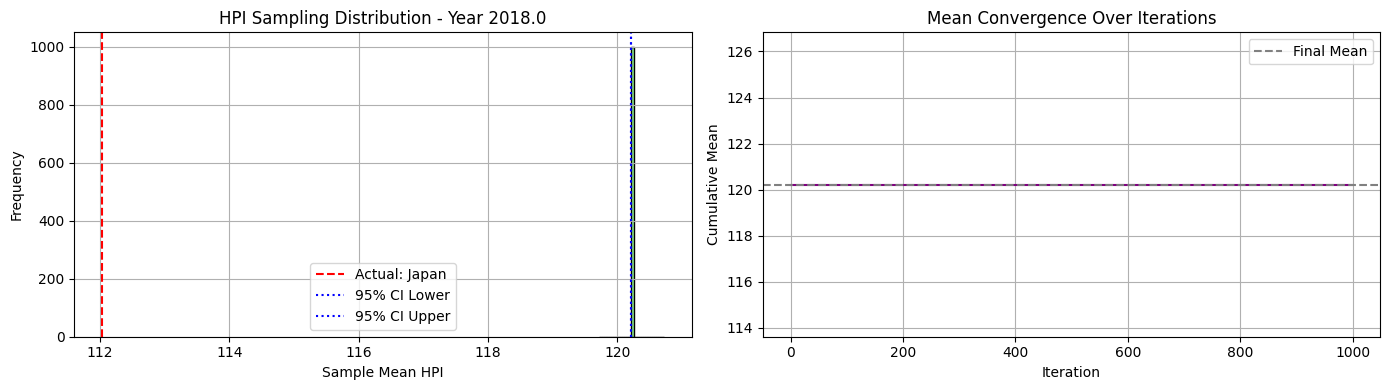

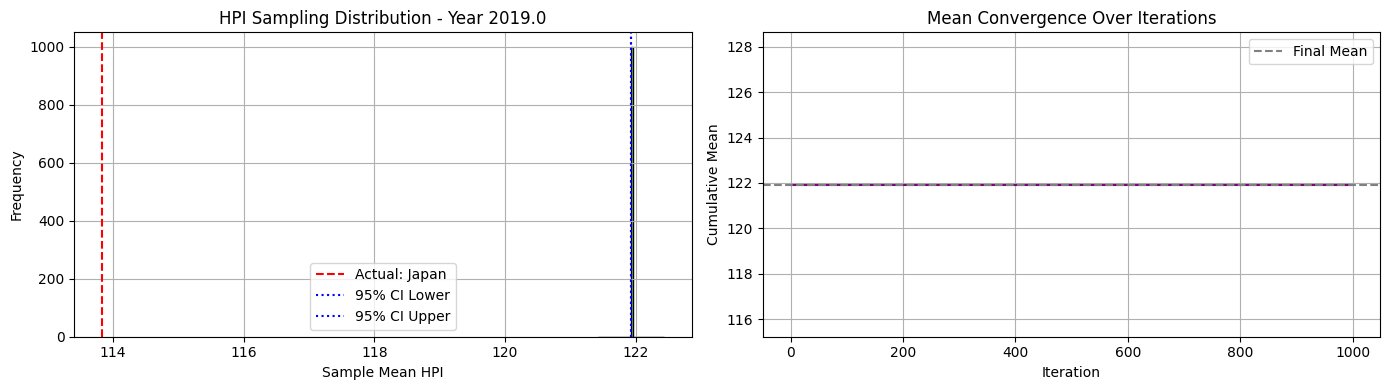

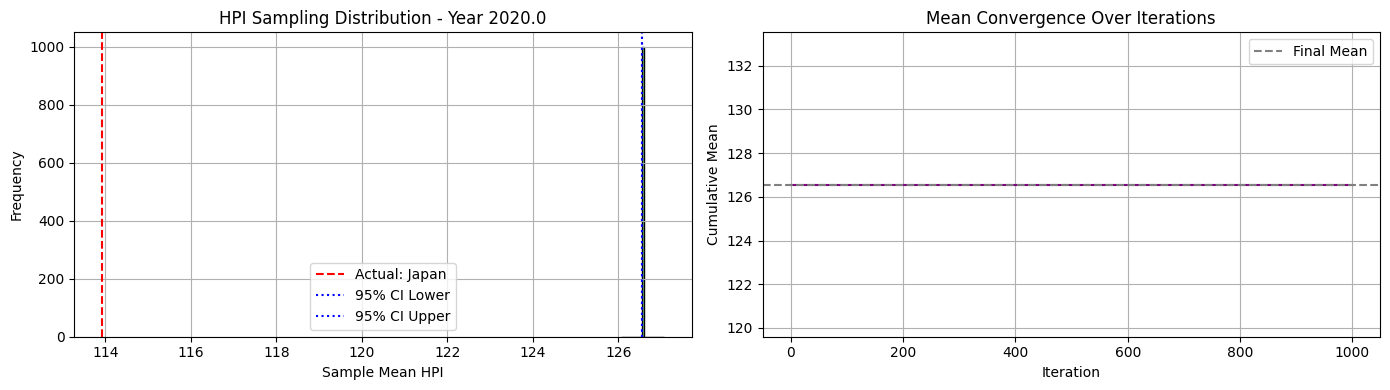

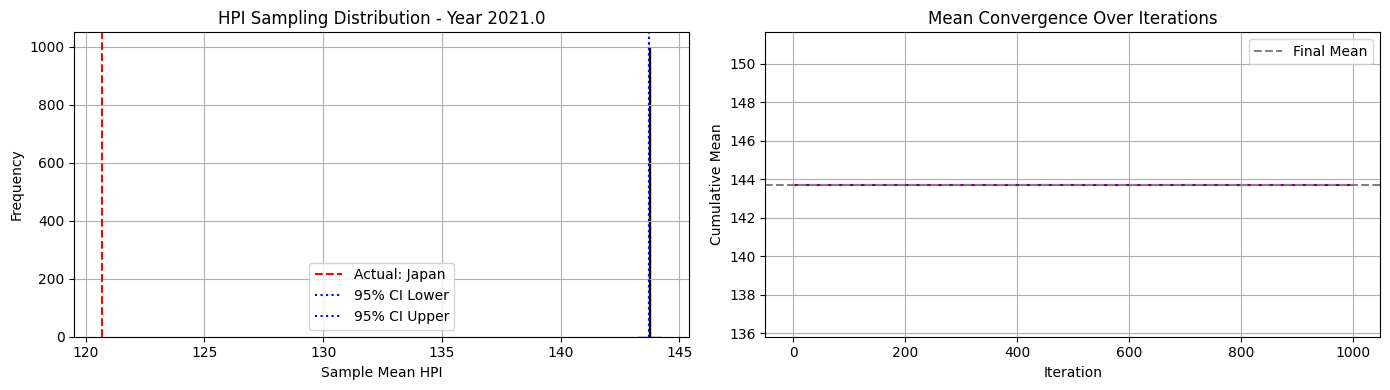

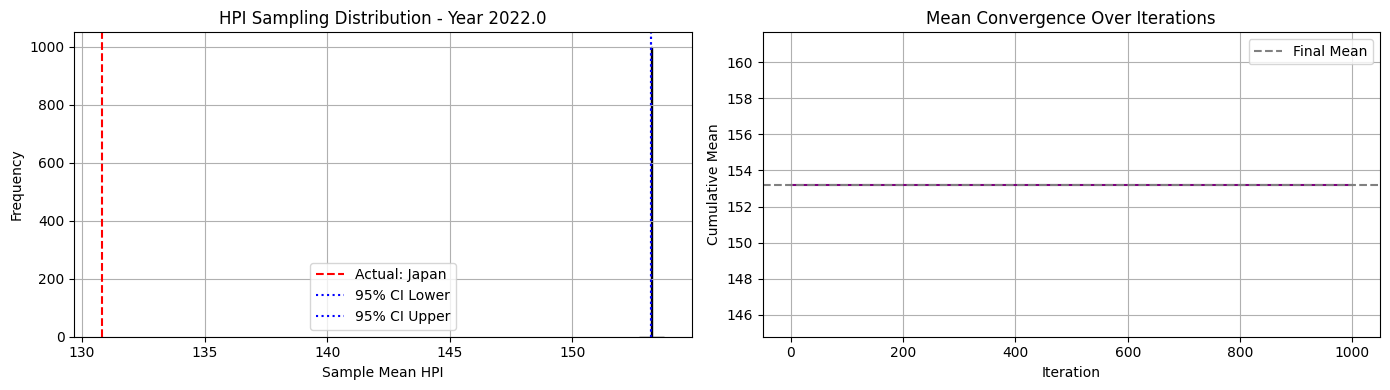

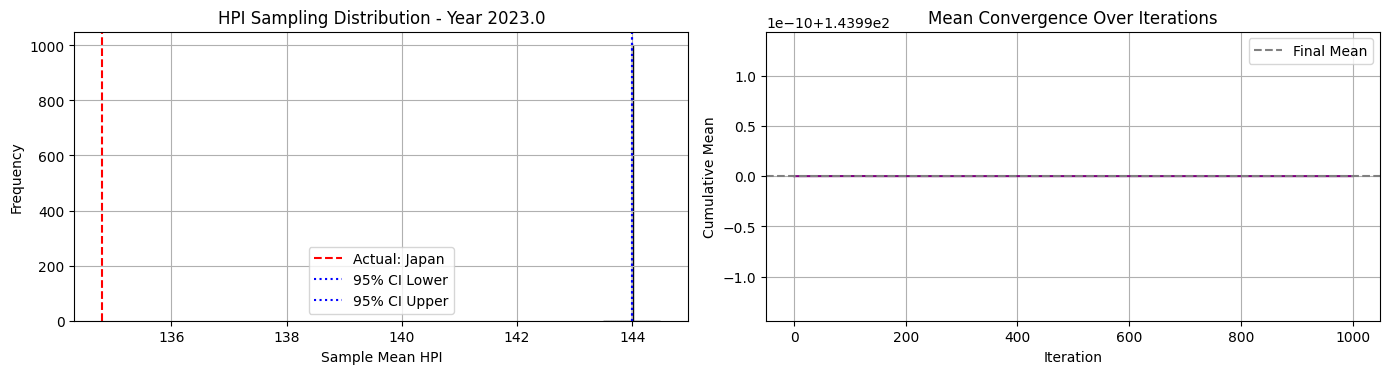

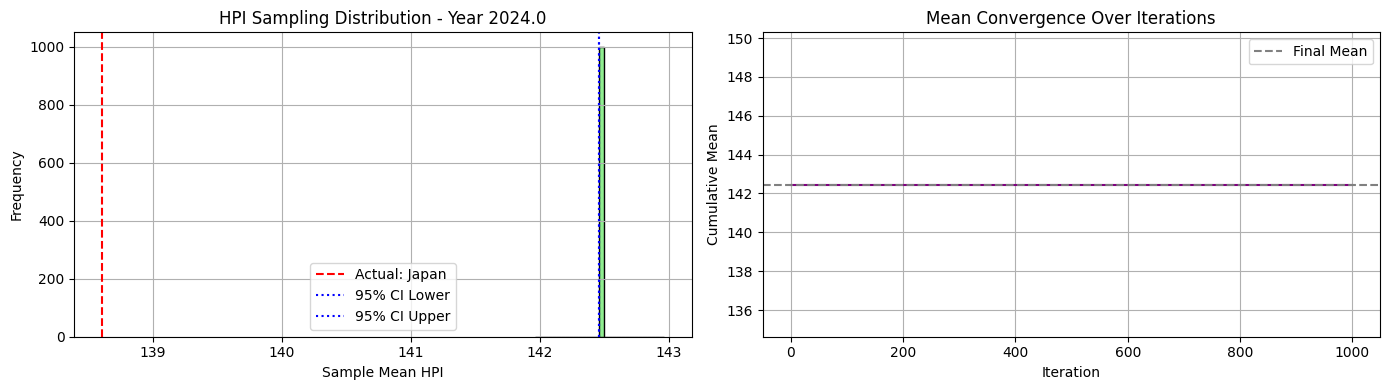

In [80]:
avg_mse_08, avg_mae_08, best_country_08, yearly_bootstrap_means_08, yearly_mean_08 = evaluate_cluster_sampling_errors(df_hpi_winsorized, df_clusters=df_continet, cluster_id="Eastern Asia", cluster_column="UNregion", start_year=2016)

In [42]:
df_continet[df_continet["UNregion"]=="South-eastern Asia"]

,PC1,PC2,cluster,Country,ISO_A3,Continent,UNregion
26,0.080285,0.776505,1,Malaysia,MYS,Asia,South-eastern Asia
34,12.456768,-4.271766,1,Philippines,PHL,Asia,South-eastern Asia
40,-4.441037,6.265166,0,Singapore,SGP,Asia,South-eastern Asia
48,12.002916,-0.255752,1,Thailand,THA,Asia,South-eastern Asia


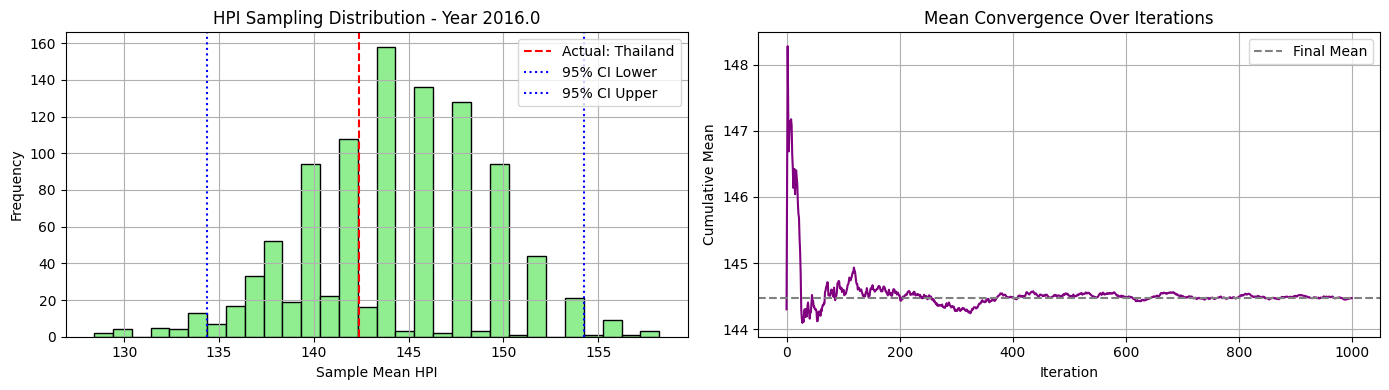

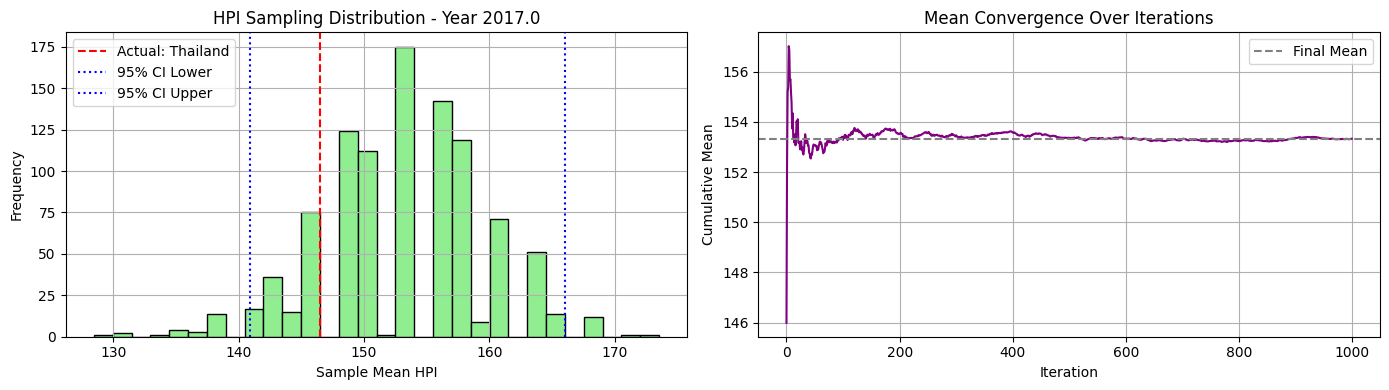

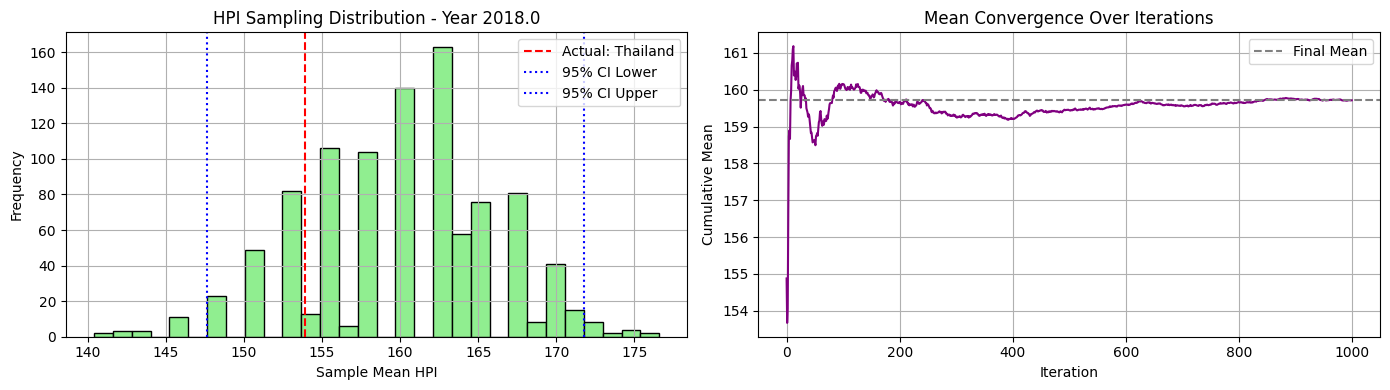

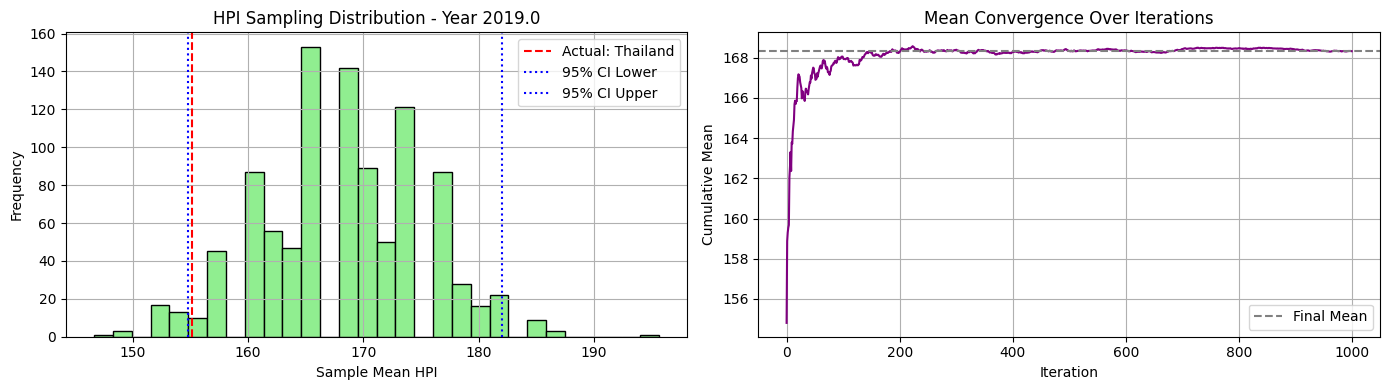

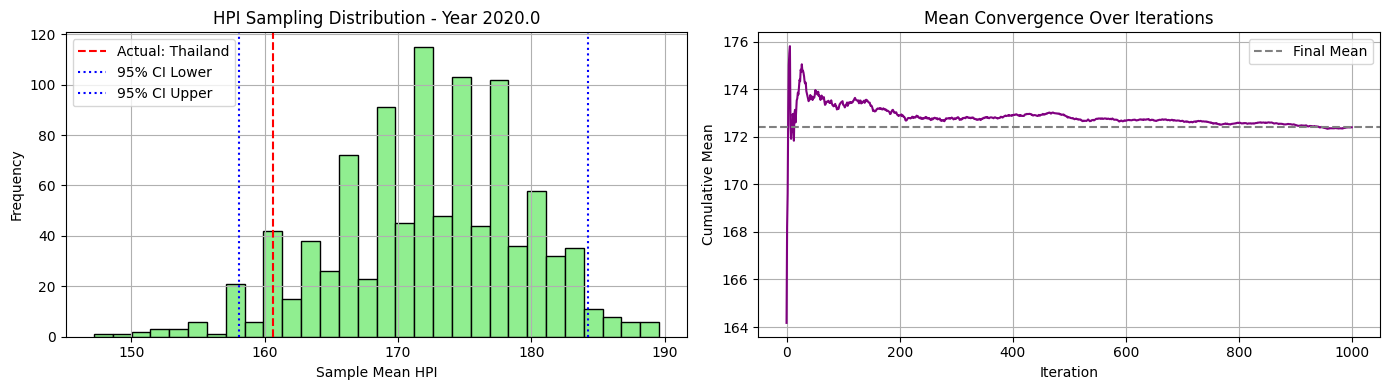

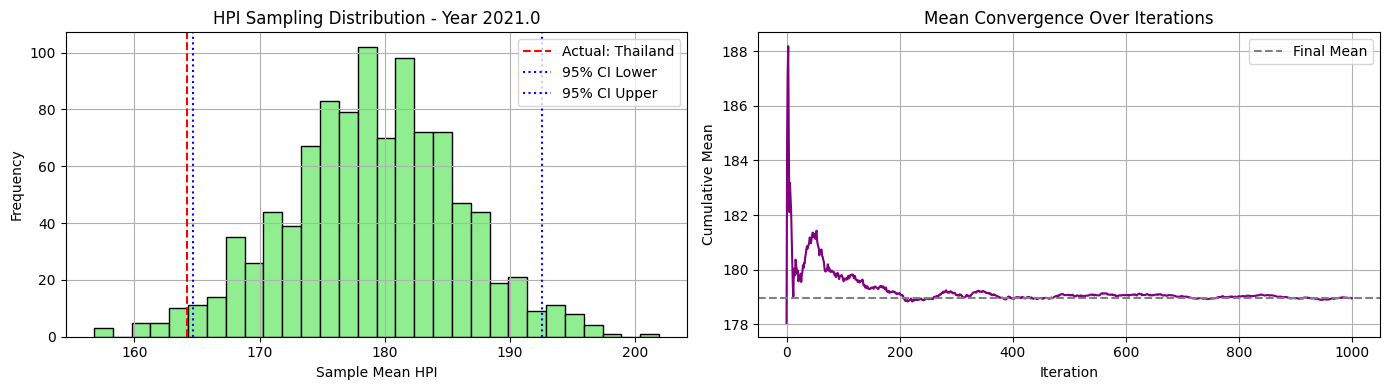

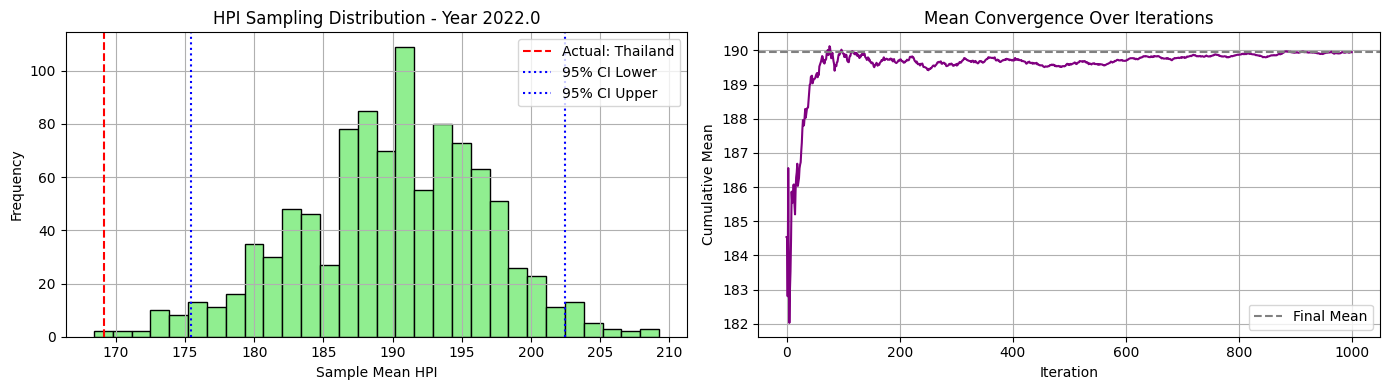

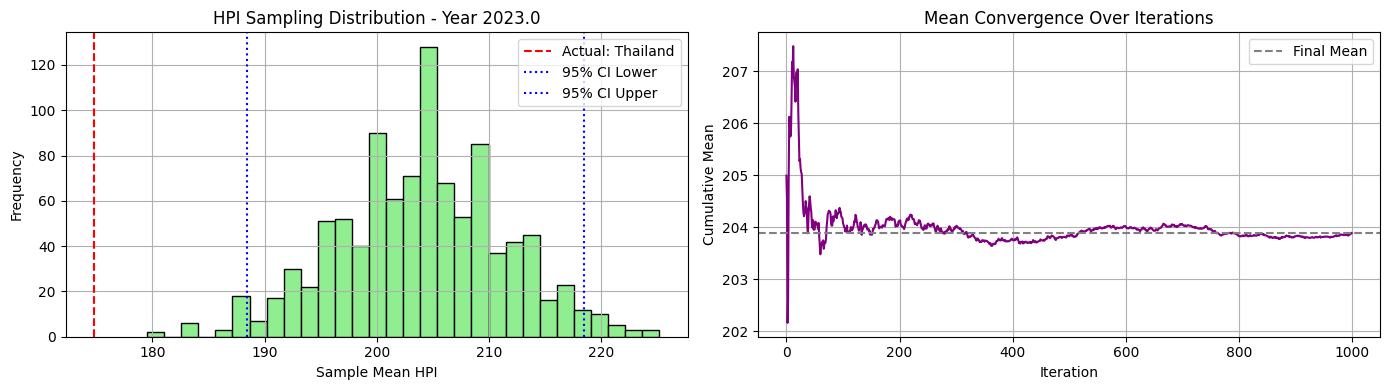

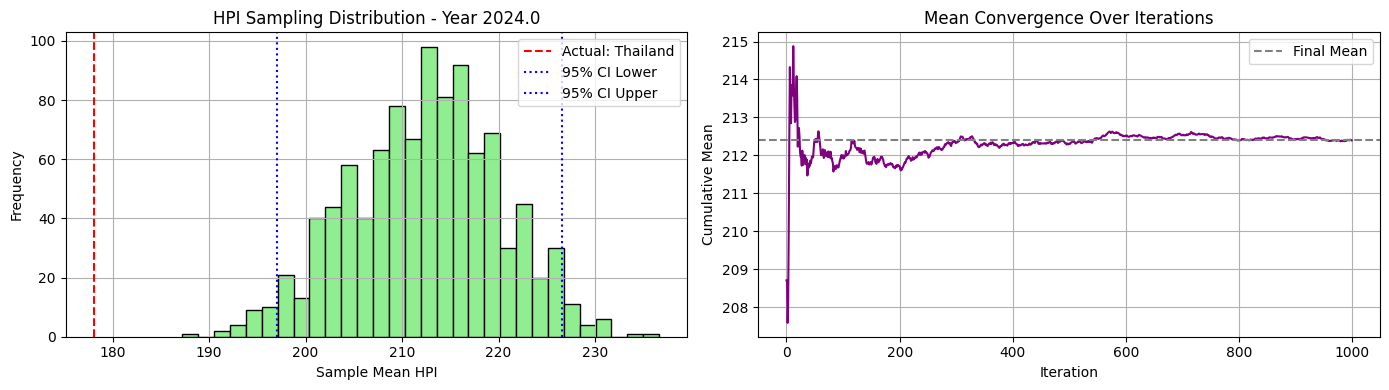

In [81]:
avg_mse_09, avg_mae_09, best_country_09, yearly_bootstrap_means_09, yearly_mean_09 = evaluate_cluster_sampling_errors(df_hpi_winsorized, df_clusters=df_continet, cluster_id="South-eastern Asia", cluster_column="UNregion", start_year=2016)

In [45]:
df_continet[df_continet["UNregion"]=="Southern Africa"]

,PC1,PC2,cluster,Country,ISO_A3,Continent,UNregion
43,6.988732,0.04535,1,South Africa,ZAF,Africa,Southern Africa


### See errors

In [83]:
df_continet.UNregion.unique()

array(['Australia and New Zealand', 'Western Europe', 'South America',
       'Eastern Europe', 'Northern America', 'Southern Europe',
       'Western Asia', 'Northern Europe', 'Eastern Asia',
       'South-eastern Asia', 'Southern Africa'], dtype=object)

In [84]:
errors_continent = {
    'Oceania': [avg_mse_00, avg_mae_00],
    'Western Europe': [avg_mse_01, avg_mae_01],
    'South America': [avg_mse_02, avg_mae_02],
    'Eastern Europe': [avg_mse_03, avg_mae_03],
    'Northern America': [avg_mse_04, avg_mae_04],
    'Southern Europe': [avg_mse_05, avg_mae_05],
    'Northern Europe': [avg_mse_06, avg_mae_06],
    'Western Asia': [avg_mse_07, avg_mae_07],
    'Eastern Asia': [avg_mse_08, avg_mae_08],
    'South-eastern Asia': [avg_mse_09, avg_mae_09]
    
}

# Convertir a DataFrame
df_errors_continent = pd.DataFrame.from_dict(errors_continent, orient='index', columns=['Average MSE', 'Average MAE'])

# Formatear valores con 4 decimales
df_errors_continent = df_errors_continent.round(4)

# Imprimir tabla
print("\n📊 Cluster Sampling Error Summary:")
print(df_errors_continent)


📊 Cluster Sampling Error Summary:
                    Average MSE  Average MAE
Oceania               2270.3195      45.3967
Western Europe         842.1323      24.7737
South America          692.4600      21.7794
Eastern Europe        1319.8657      27.8796
Northern America       355.0250      16.1539
Southern Europe        844.8330      23.5474
Northern Europe       1615.8746      32.8115
Western Asia          6726.3213      79.4156
Eastern Asia           173.4362      11.5500
South-eastern Asia    1993.2915      39.7991


In [87]:
df_errors_continent['Average MSE'].mean()

np.float64(1683.3559099999998)

In [88]:
df_errors_continent['Average MAE'].mean()

np.float64(32.31069)

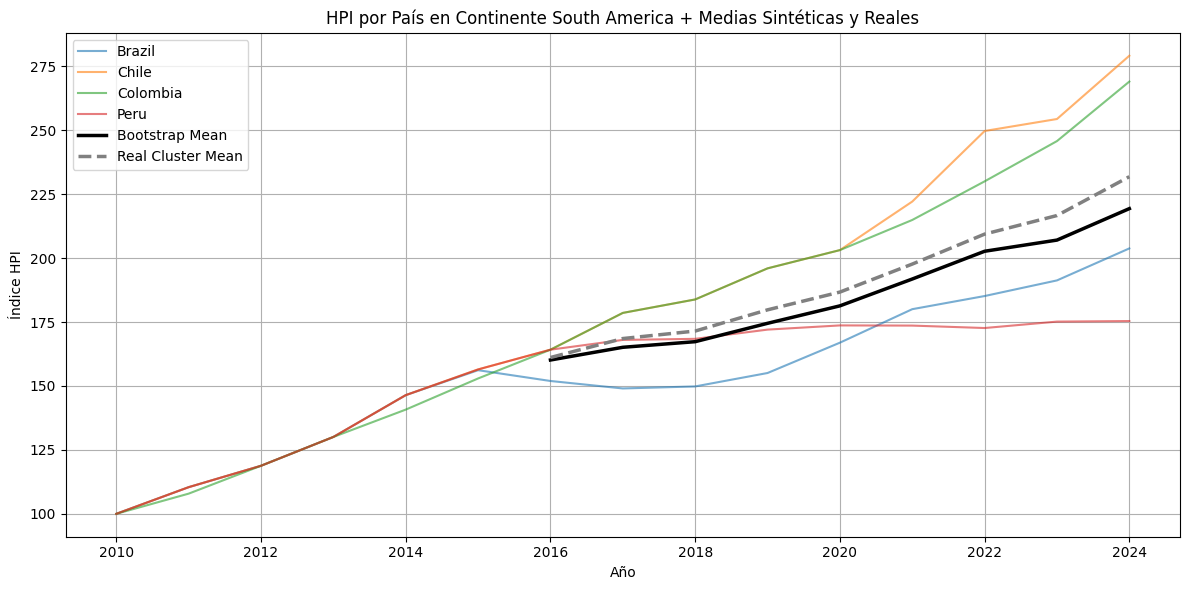

In [97]:
plot_cluster_hpi_with_bootstrap(df_hpi_winsorized, df_continet, cluster_id="South America", cluster_column="UNregion", yearly_bootstrap_means=yearly_bootstrap_means_02, yearly_mean=yearly_mean_02)

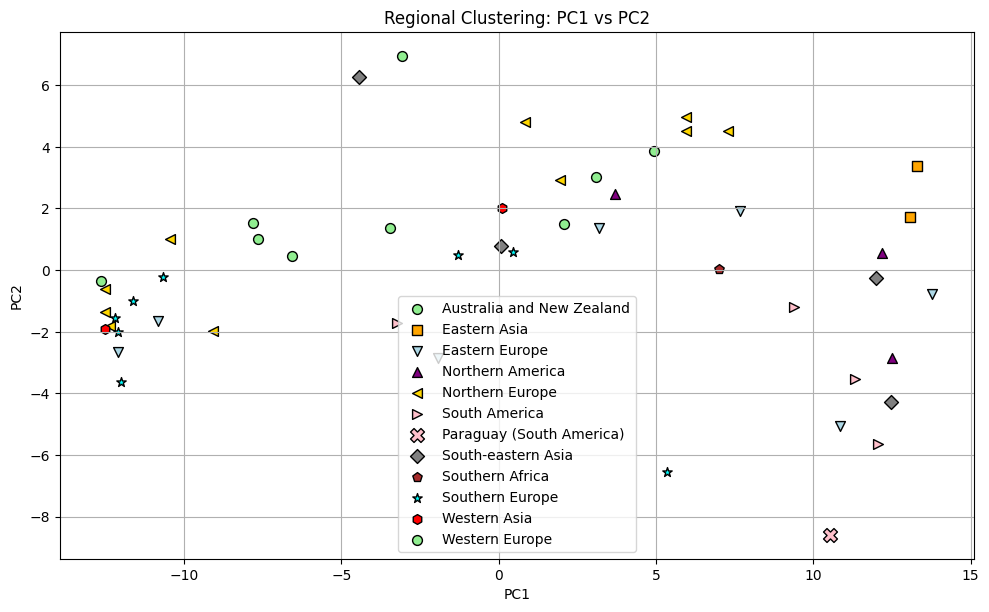

In [99]:
plot_region_clusters(df_continet, 'PC1', 'PC2')

In [103]:
from sklearn.metrics import silhouette_samples
from matplotlib import cm

In [104]:
def plot_silhouette_from_labels(df, x_col, y_col, label_col='UNregion'):
    """
    Generates a silhouette plot using predefined cluster labels (e.g., UNregion).

    Parameters:
    - df: DataFrame containing the data
    - x_col, y_col: columns for the feature space
    - label_col: column with cluster labels (e.g., UNregion)

    Returns:
    - silhouette_avg: average silhouette coefficient
    """
    X = df[[x_col, y_col]].values
    labels_raw = df[label_col].values
    unique_labels = np.unique(labels_raw)
    
    # Map string labels to integers
    label_map = {label: idx for idx, label in enumerate(unique_labels)}
    labels = np.array([label_map[label] for label in labels_raw])
    
    n_clusters = len(unique_labels)
    silhouette_vals = silhouette_samples(X, labels, metric='euclidean')
    silhouette_avg = np.mean(silhouette_vals)

    y_ax_lower, yticks = 0, []

    for i in range(n_clusters):
        cluster_vals = silhouette_vals[labels == i]
        cluster_vals.sort()
        y_ax_upper = y_ax_lower + len(cluster_vals)

        color = cm.jet(float(i) / n_clusters)
        plt.barh(
            range(y_ax_lower, y_ax_upper),
            cluster_vals,
            height=1.0,
            edgecolor='none',
            color=color
        )

        yticks.append((y_ax_lower + y_ax_upper) / 2.)
        y_ax_lower = y_ax_upper

    plt.axvline(silhouette_avg, color="red", linestyle="--", label=f"Average: {silhouette_avg:.2f}")
    plt.yticks(yticks, [f'{label}' for label in unique_labels])
    plt.ylabel('Cluster (Region)')
    plt.xlabel('Silhouette coefficient')
    plt.title('Silhouette plot by region')
    plt.legend()
    plt.tight_layout()
    plt.show()

    return silhouette_avg


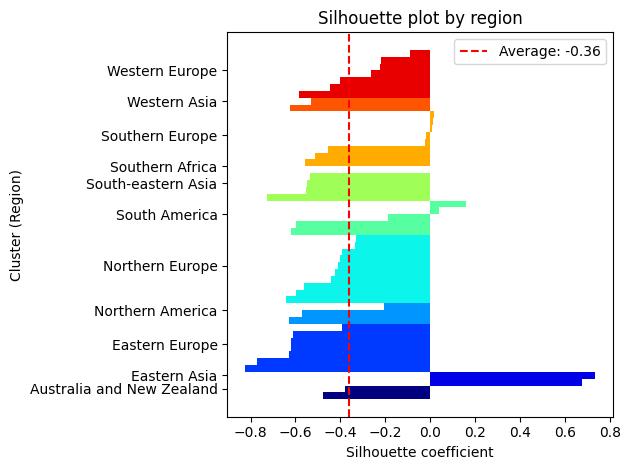

np.float64(-0.3596123122488132)

In [105]:
plot_silhouette_from_labels(df_continet, 'PC1', 'PC2', label_col='UNregion')

### Compare in the same interval of year

In [89]:
df_continet.head(8)

,PC1,PC2,cluster,Country,ISO_A3,Continent,UNregion
0,2.064226,1.489614,1,Australia,AUS,Oceania,Australia and New Zealand
1,-7.648769,0.995875,0,Austria,AUT,Europe,Western Europe
2,-6.580014,0.441960,0,Belgium,BEL,Europe,Western Europe
3,9.370254,-1.189187,1,Brazil,BRA,America,South America
4,-10.818940,-1.642285,0,Bulgaria,BGR,Europe,Eastern Europe
5,3.698850,2.479485,1,Canada,CAN,America,Northern America
6,11.313440,-3.520124,1,Chile,CHL,America,South America
7,12.057846,-5.641059,1,Colombia,COL,America,South America


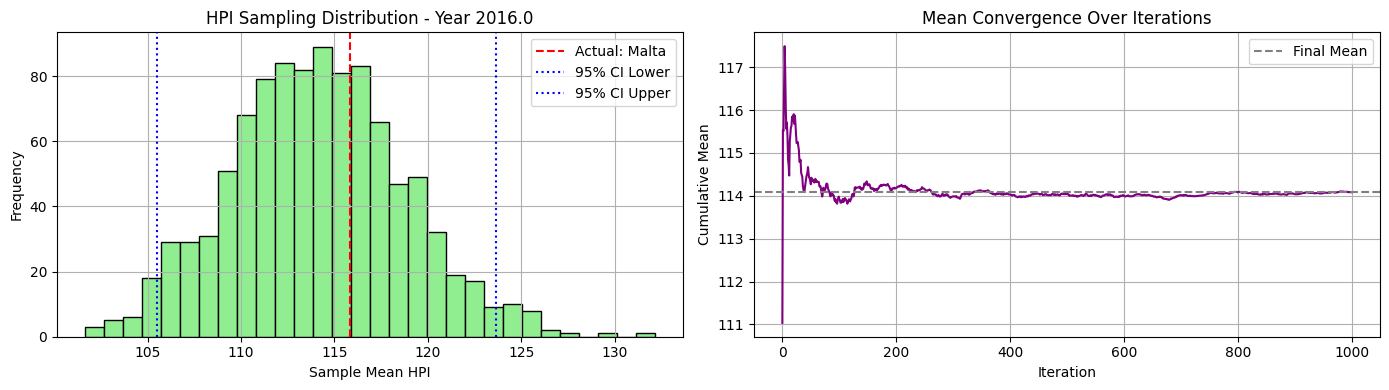

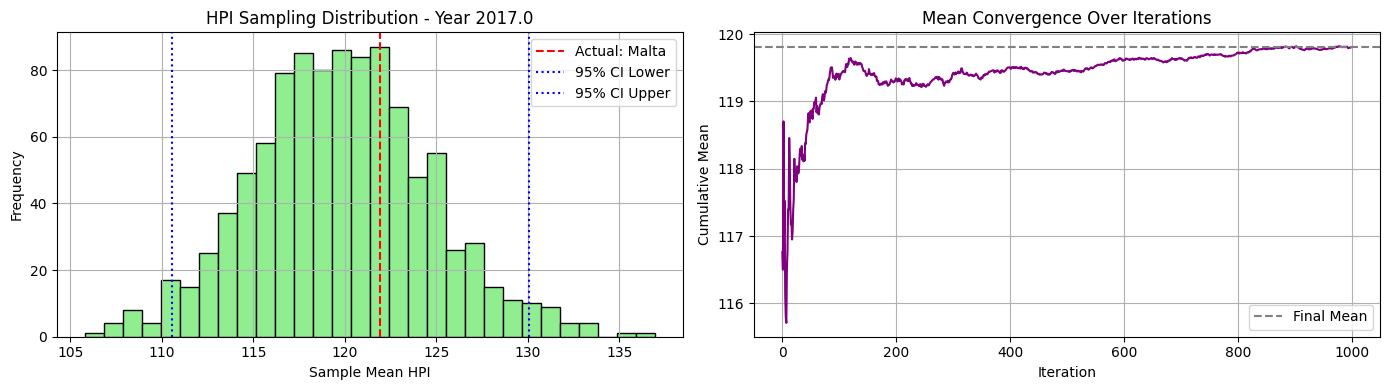

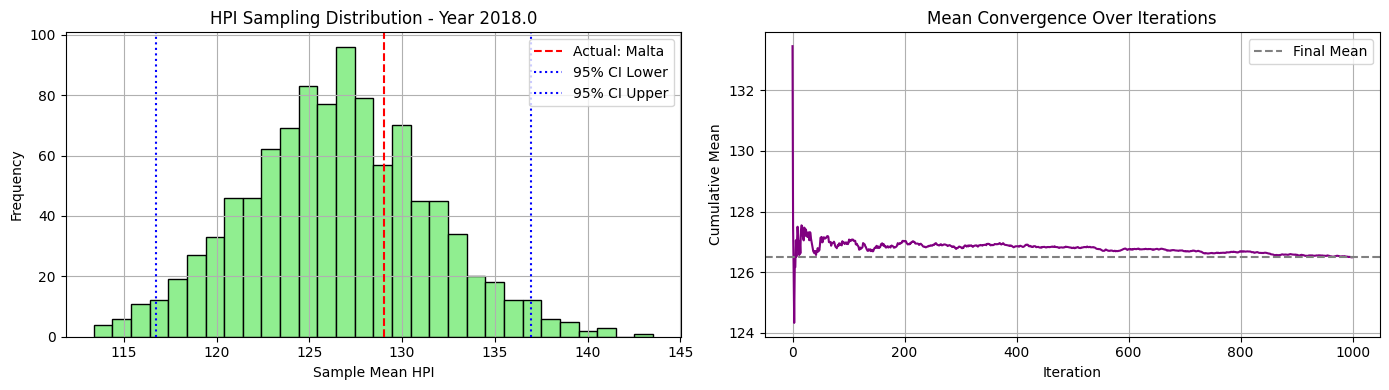

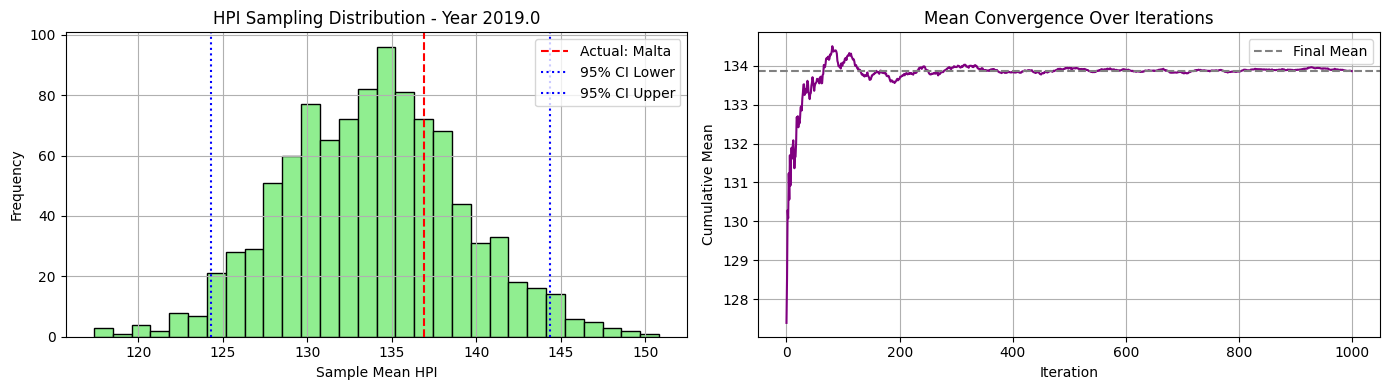

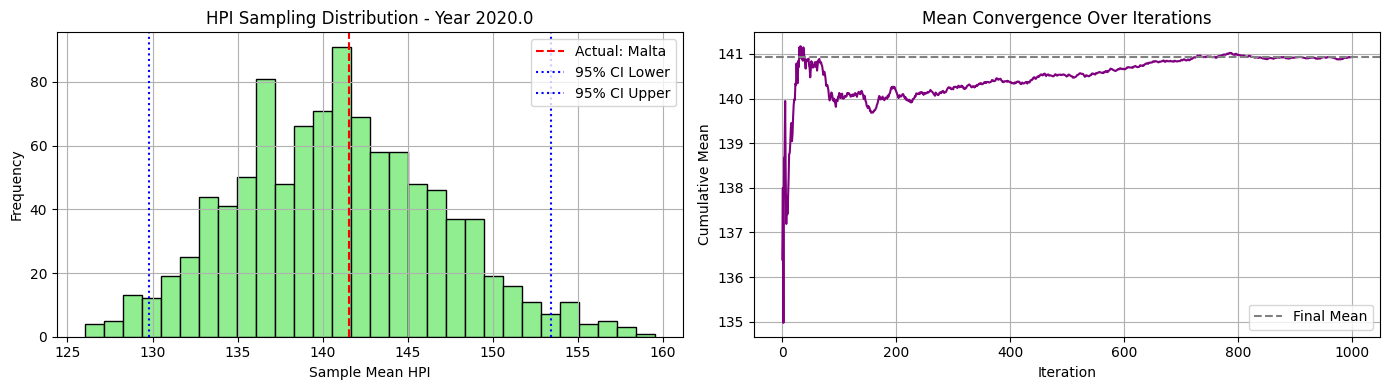

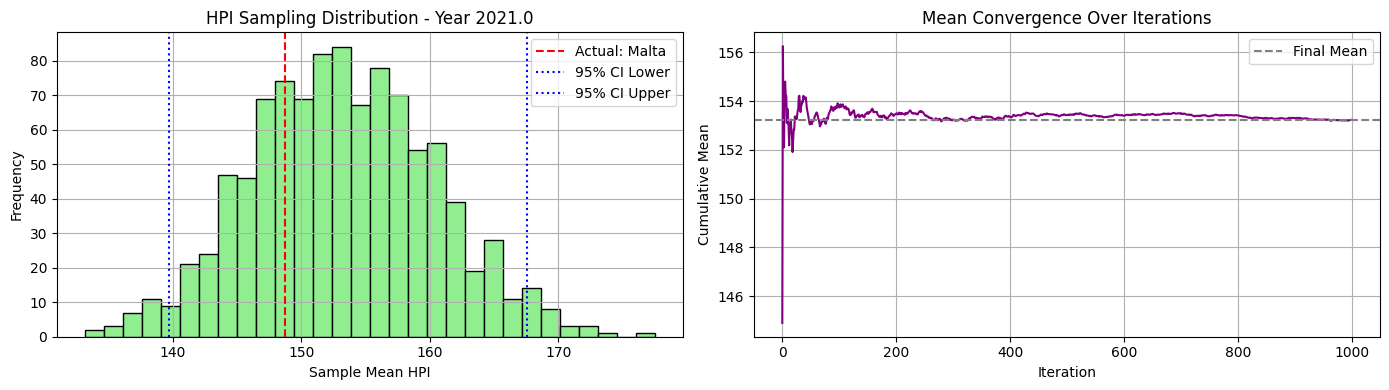

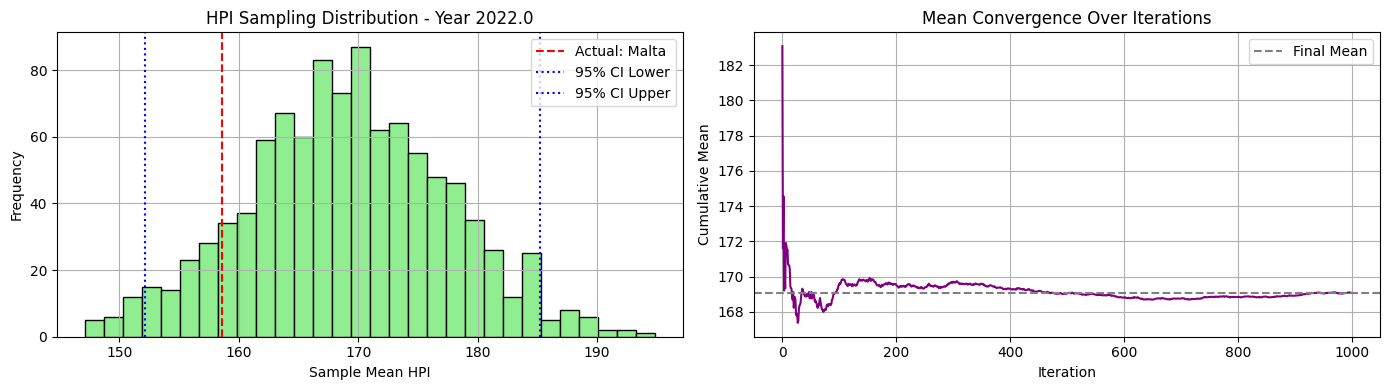

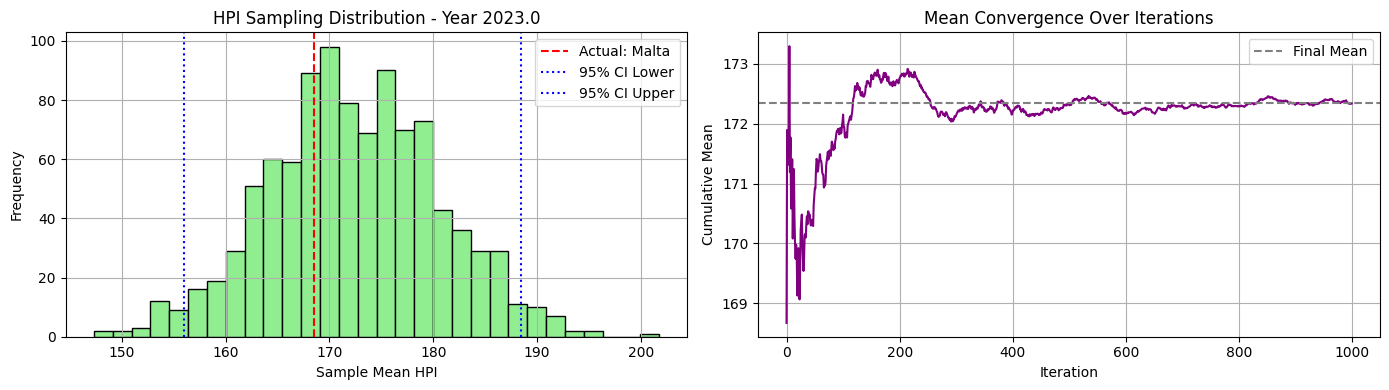

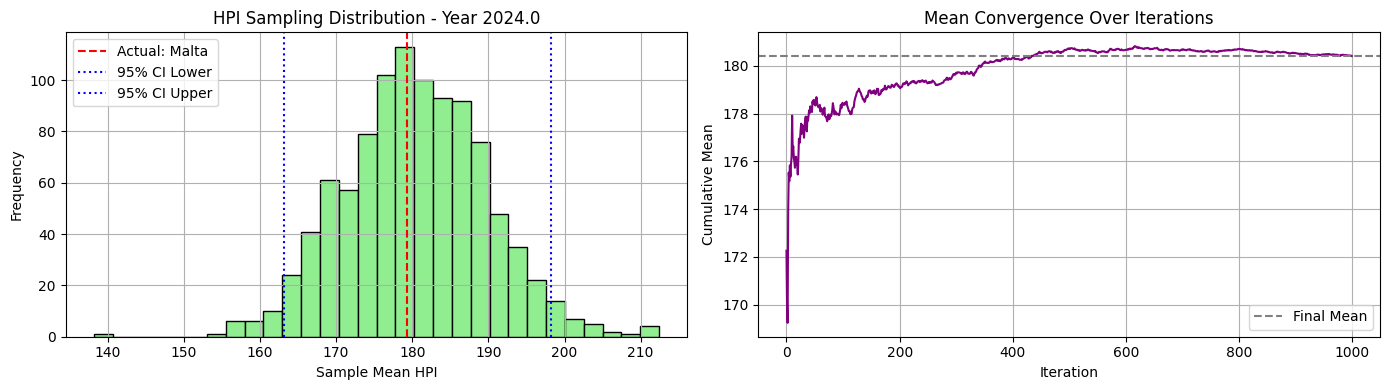

In [90]:
avg_mse_2016_00, avg_mae_2016_00, best_country_2016_00, yearly_bootstrap_means_2016_00, yearly_mean_2016_00 = evaluate_cluster_sampling_errors(df_hpi_winsorized, df_clusters=df_continet, cluster_id=0, cluster_column="cluster", start_year=2016)

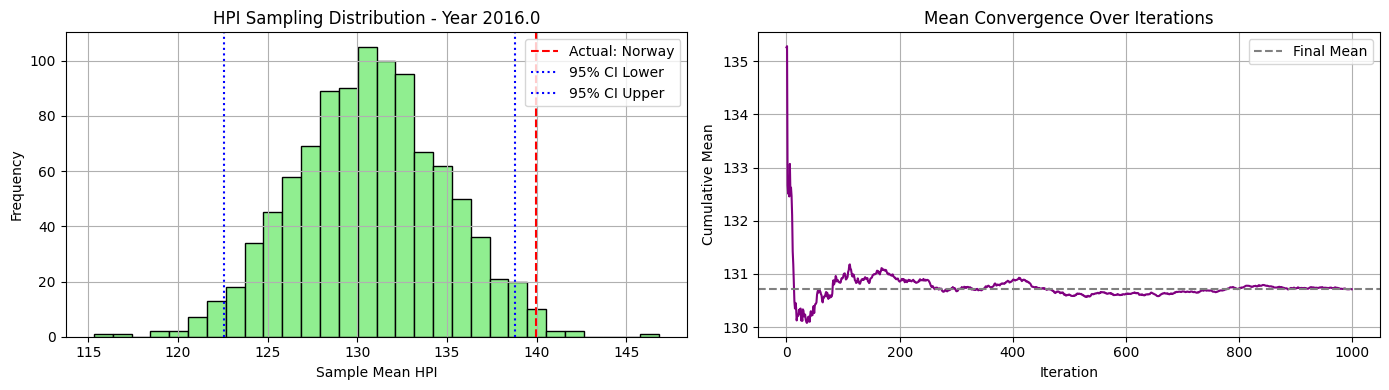

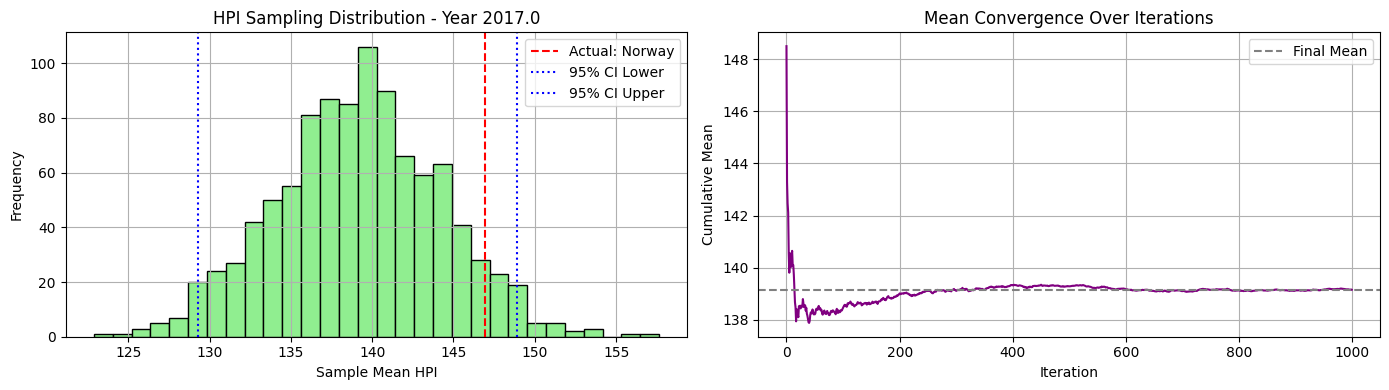

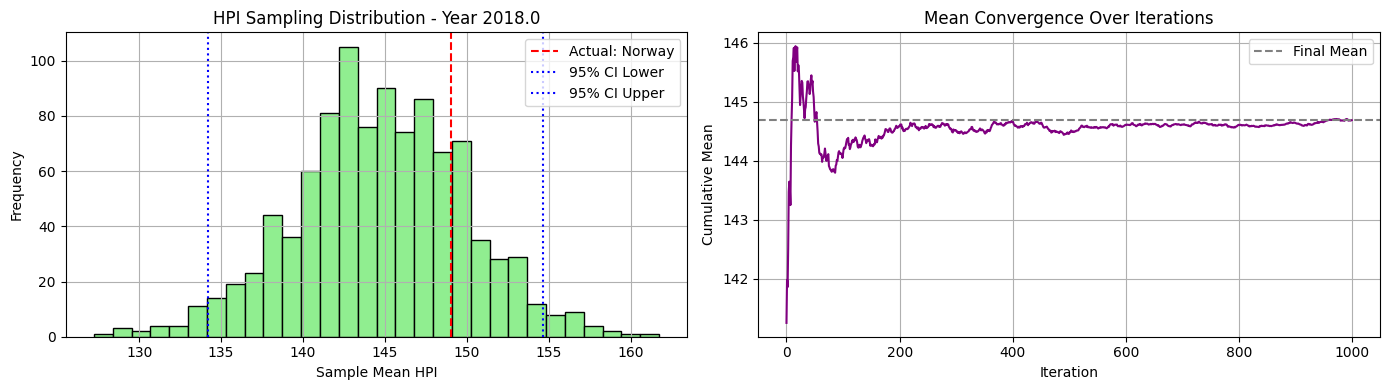

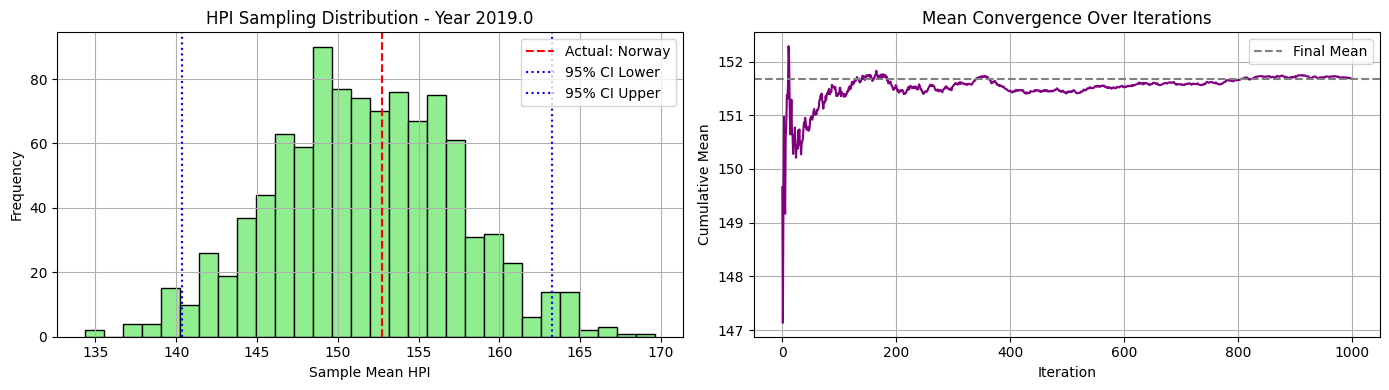

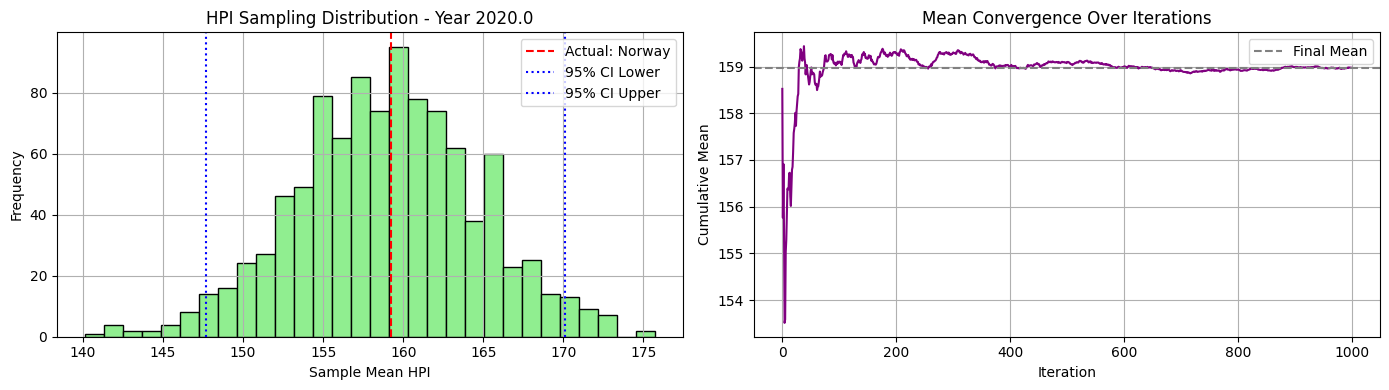

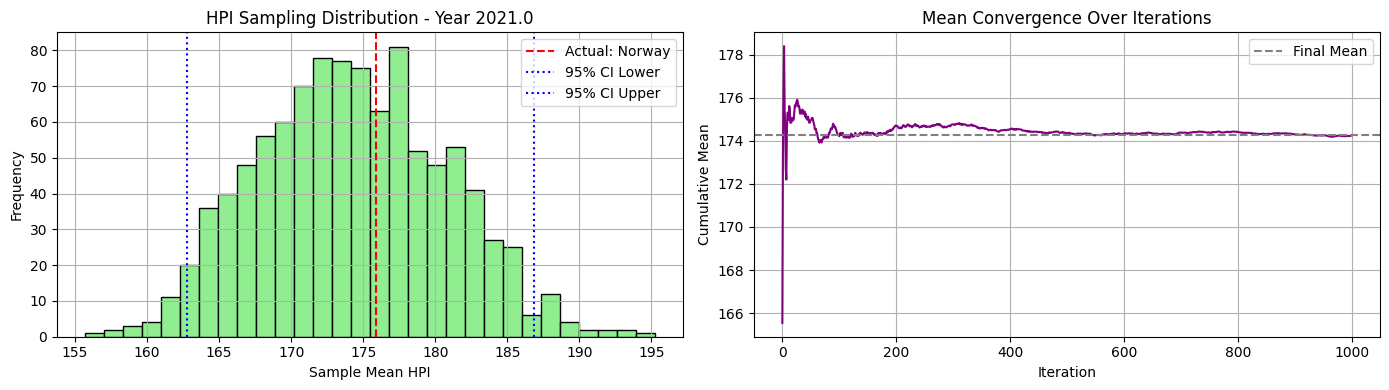

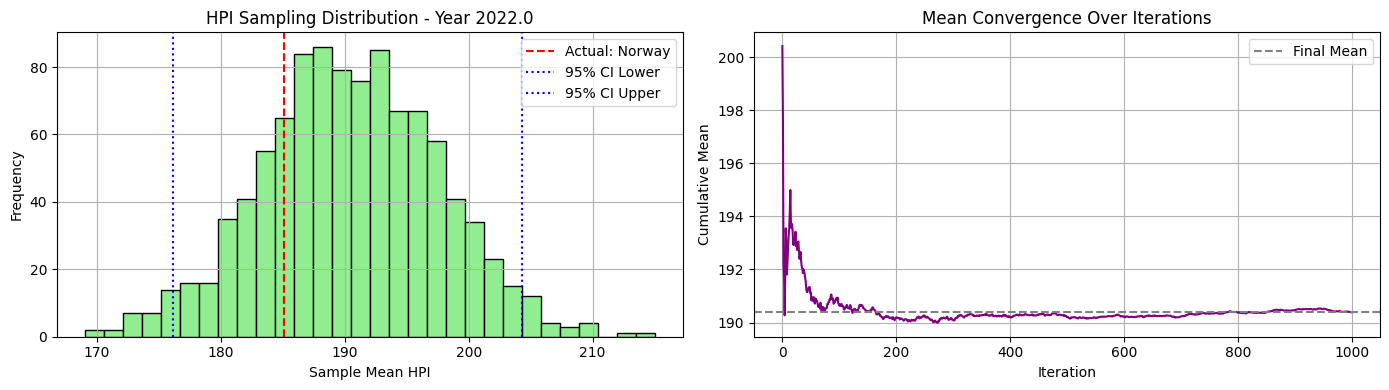

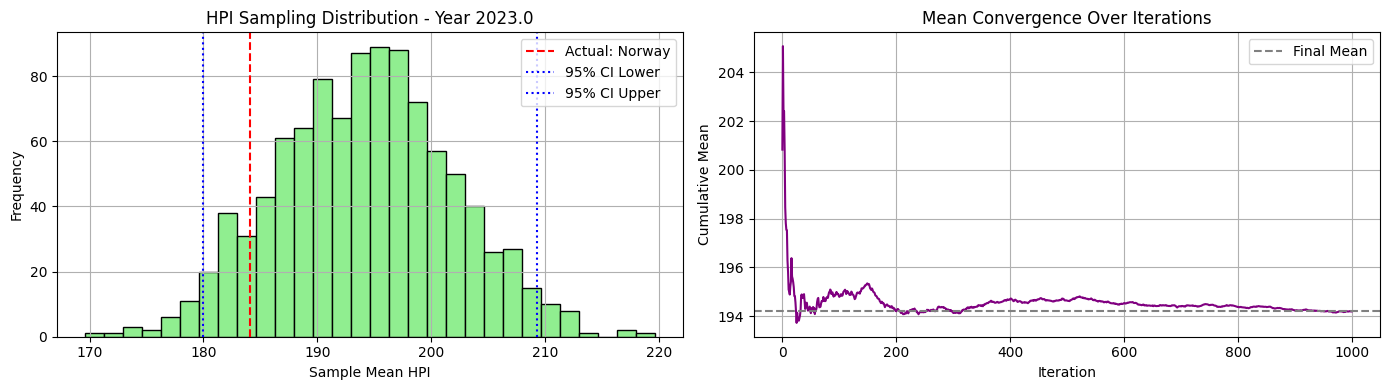

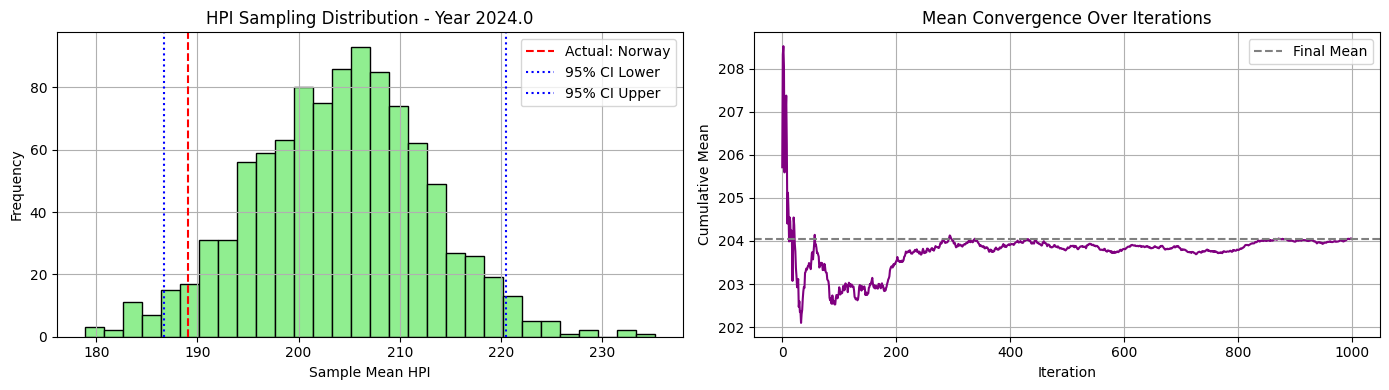

In [91]:
avg_mse_2016_01, avg_mae_2016_01, best_country_2016_01, yearly_bootstrap_means_2016_01, yearly_mean_2016_01 = evaluate_cluster_sampling_errors(df_hpi_winsorized, df_clusters=df_continet, cluster_id=1, cluster_column="cluster", start_year=2016)

In [92]:
errors_cuslter = {
    'cluster_cero': [avg_mse_2016_00, avg_mae_2016_00],
    'cluster_one': [avg_mse_2016_01, avg_mae_2016_01]    
}

# Convertir a DataFrame
df_errors_cluster = pd.DataFrame.from_dict(errors_cuslter, orient='index', columns=['Average MSE', 'Average MAE'])

# Formatear valores con 4 decimales
df_errors_cluster = df_errors_cluster.round(4)

# Imprimir tabla
print("\n📊 Cluster Sampling Error Summary:")
print(df_errors_cluster)


📊 Cluster Sampling Error Summary:
              Average MSE  Average MAE
cluster_cero    1407.7625      29.7872
cluster_one     1255.9061      28.7322


In [93]:
df_errors_cluster['Average MSE'].mean()

np.float64(1331.8343)

In [94]:
df_errors_cluster['Average MAE'].mean()

np.float64(29.2597)

### Log performance of the experiment
* Import dataframe for the logs
* Define the hyperparameter for introduce the results
* Export the dataframe

In [9]:
from datetime import datetime

In [106]:
log_df = pd.read_parquet('')

In [107]:
new_entry= {
    'experiment_name': 'kmeans_plusplus_c2_ni20_maxi500_3cpuntries_deleted_hpi_no_pca2_3_countries_exclude',
    'experiment_date': datetime.now().strftime('%Y-%m-%d %H:%M'),
    'clustering_model': 'KMeans',
    'n_clusters': 2,
    'init_method': 'k-means++',
    'n_init': 20,
    'max_iter': 500,
    'random_state': 42,
    'used_elbow_method': True,
    'used_silhouette_score': True,
    'used_2nd_derivate_for_inflection': True,
    'silhouette_score': silhoutte_score_pca2,
    'transformations_clustering': 'StandardScaler, log transformation',
    'transformations_sampling': 'Winsorization x2, rounding',
    'outliers_handling_clustering': 'Winsorization x6',
    'outliers_handling_sampling': 'Winsorization x2',
    'sampling_method': 'bootstrap',
    'mse_score': summary_c2_ni20_maxi500['mse_mean'],
    'mae_score': summary_c2_ni20_maxi500['mae_mean'],
    'sampling_seed': (32,43,52),
    'excluded_countries_count': 3,
    'used_all_variables_for_clustering': True,
    'used_pca_for_clustering': True,
    "premacroecon_conversion_transform": None,
    "countries_used_for_clustering": 50
}

In [109]:
log_df = pd.concat([log_df, pd.DataFrame([new_entry])], ignore_index=True)

In [110]:
log_df.tail()

,experiment_name,experiment_date,premacroecon_conversion_transform,countries_used_for_clustering,clustering_model,n_clusters,init_method,n_init,max_iter,random_state,...,transformations_sampling,outliers_handling_sampling,sampling_method,sampling_seed,excluded_countries_count,mse_score,mae_score,source_notebook,pca_ratio_sum,pca_ratio_values
17,kmeans_plusplus_c2_ni20_maxi500_h2_delteted4_c...,2025-09-17 15:31,None,48,KMeans,2,k-means++,20.0,500.0,42.0,...,"Delete Countries x4, Winsorization x2, rounding",Winsorization x2,bootstrap,"[32, 43, 52]",3.0,266.390743,12.178599,hypothesis_test_24.ipynb,NaN,None
18,cluster_continet_based_3_countries_exclude,2025-09-17 17:01,None,52,Continet Based,4,None,NaN,NaN,NaN,...,"Winsorization x2, rounding",Winsorization x2,bootstrap,"[23, 42, 52]",3.0,1062.159368,23.694253,hypothesis_test_25.ipynb,NaN,None
19,kmeans_plusplus_c2_ni20_maxi500_3countries_del...,2025-09-18 17:00,None,50,KMeans,2,k-means++,20.0,500.0,42.0,...,"Delete Countries x3, Winsorization x4, rounding",Winsorization x4,bootstrap,"[32, 43, 52]",3.0,262.010999,12.168987,hypothesis_test_26.ipynb,NaN,None
20,kmeans_plusplus_c2_ni20_maxi500_h2_pca3_3_coun...,2025-09-18 19:59,None,53,KMeans,2,k-means++,20.0,500.0,42.0,...,"Winsorization x2, rounding",Winsorization x2,bootstrap,"[32, 43, 52]",3.0,558.544788,16.261550,hypothesis_test_28.ipynb,0.876932,"[0.7860579623666695, 0.09087374609246396]"
21,kmeans_plusplus_c2_ni20_maxi500_3cpuntries_del...,2025-09-20 22:43,None,50,KMeans,2,k-means++,20.0,500.0,42.0,...,"Winsorization x2, rounding",Winsorization x2,bootstrap,"(32, 43, 52)",3.0,246.836518,11.583352,NaN,NaN,NaN


In [111]:
log_df.loc[21, "source_notebook"] = "hypothesis_test_29.ipynb"

In [112]:
log_df['used_all_variables_for_clustering'] = log_df['used_all_variables_for_clustering'].apply(str)

In [113]:
log_df.loc[21, "pca_ratio_sum"] = pca_2.explained_variance_ratio_.sum()

In [114]:
# Change the column dtype to object
log_df["pca_ratio_values"] = log_df["pca_ratio_values"].astype('object')

# Now you can assign the tuple to the cell
log_df.at[21, "pca_ratio_values"] = tuple(pca_2.explained_variance_ratio_)

In [115]:
log_df.at[20, "countries_used_for_clustering"] = 52

In [116]:
log_df.tail()

,experiment_name,experiment_date,premacroecon_conversion_transform,countries_used_for_clustering,clustering_model,n_clusters,init_method,n_init,max_iter,random_state,...,transformations_sampling,outliers_handling_sampling,sampling_method,sampling_seed,excluded_countries_count,mse_score,mae_score,source_notebook,pca_ratio_sum,pca_ratio_values
17,kmeans_plusplus_c2_ni20_maxi500_h2_delteted4_c...,2025-09-17 15:31,None,48,KMeans,2,k-means++,20.0,500.0,42.0,...,"Delete Countries x4, Winsorization x2, rounding",Winsorization x2,bootstrap,"[32, 43, 52]",3.0,266.390743,12.178599,hypothesis_test_24.ipynb,NaN,None
18,cluster_continet_based_3_countries_exclude,2025-09-17 17:01,None,52,Continet Based,4,None,NaN,NaN,NaN,...,"Winsorization x2, rounding",Winsorization x2,bootstrap,"[23, 42, 52]",3.0,1062.159368,23.694253,hypothesis_test_25.ipynb,NaN,None
19,kmeans_plusplus_c2_ni20_maxi500_3countries_del...,2025-09-18 17:00,None,50,KMeans,2,k-means++,20.0,500.0,42.0,...,"Delete Countries x3, Winsorization x4, rounding",Winsorization x4,bootstrap,"[32, 43, 52]",3.0,262.010999,12.168987,hypothesis_test_26.ipynb,NaN,None
20,kmeans_plusplus_c2_ni20_maxi500_h2_pca3_3_coun...,2025-09-18 19:59,None,52,KMeans,2,k-means++,20.0,500.0,42.0,...,"Winsorization x2, rounding",Winsorization x2,bootstrap,"[32, 43, 52]",3.0,558.544788,16.261550,hypothesis_test_28.ipynb,0.876932,"[0.7860579623666695, 0.09087374609246396]"
21,kmeans_plusplus_c2_ni20_maxi500_3cpuntries_del...,2025-09-20 22:43,None,50,KMeans,2,k-means++,20.0,500.0,42.0,...,"Winsorization x2, rounding",Winsorization x2,bootstrap,"(32, 43, 52)",3.0,246.836518,11.583352,hypothesis_test_29.ipynb,0.740380,"(0.6591137352377315, 0.08126612096581198)"


In [117]:
log_df.to_parquet('../data/log_performance/clean_log_performance_experiments.parquet')

### Plot Clusters

In [81]:
def plot_kmeans_clusters(df, x_col, y_col, model, cluster_col='cluster', country_col='Country', highlight_country='Paraguay'):
    # Extraer coordenadas
    X = df[[x_col, y_col]].values
    y_km = df[cluster_col].values
    countries = df[country_col].values

    # Crear figura
    plt.figure(figsize=(10, 6))

    # Colores y marcadores por cluster
    colors = ['lightgreen', 'orange', 'lightblue', 'purple', 'gold', 'pink', 'gray', 'brown', 'cyan', 'red']
    markers = ['o', 's', 'v', '^', '<', '>', 'D', 'p', '*', 'h']
    special_marker = 'X'  # marcador especial para Paraguay

    # Graficar cada cluster
    for i in range(model.n_clusters):
        cluster_mask = (y_km == i)
        cluster_color = colors[i]
        cluster_marker = markers[i]

        # Separar Paraguay del resto
        paraguay_mask = cluster_mask & (countries == highlight_country)
        others_mask = cluster_mask & (countries != highlight_country)

        # Graficar otros países del cluster
        plt.scatter(X[others_mask, 0], X[others_mask, 1],
                    s=50, c=cluster_color, marker=cluster_marker,
                    edgecolor='black', label=f'Cluster {i}')

        # Graficar Paraguay con marcador especial
        if paraguay_mask.any():
            plt.scatter(X[paraguay_mask, 0], X[paraguay_mask, 1],
                        s=100, c=cluster_color, marker=special_marker,
                        edgecolor='black', label=f'{highlight_country} (Cluster {i})')

    # Graficar centroides
    plt.scatter(model.cluster_centers_[:, 0], model.cluster_centers_[:, 1],
                s=250, marker='*', c='red', edgecolor='black', label='Centroids')

    plt.xlabel(x_col)
    plt.ylabel(y_col)
    plt.legend(scatterpoints=1)
    plt.grid(True)
    plt.tight_layout()
    plt.title(f'K-Means Clustering: {x_col} vs {y_col}')
    plt.show()

In [82]:
def plot_hpi_dispersion_by_cluster(df_hpi, df_clusters,
                                    cluster_column='cluster', country_column='Country',
                                    year_column='Year'):
    """
    Plots the dispersion of HPI values for each cluster using boxplots.

    Parameters:
    - df_hpi: DataFrame with HPI values (columns = countries, rows = years, plus 'Year' column)
    - df_clusters: DataFrame with country names and cluster assignments
    - cluster_column: Column name in df_clusters with cluster labels
    - country_column: Column name in df_clusters with country names
    - year_column: Column name in df_hpi with year values
    """
    # Crear lista para almacenar datos
    records = []

    # Iterar sobre cada cluster
    for cluster_id in sorted(df_clusters[cluster_column].unique()):
        countries = df_clusters[df_clusters[cluster_column] == cluster_id][country_column].tolist()
        cluster_countries = [c for c in countries if c in df_hpi.columns]

        if len(cluster_countries) < 2:
            continue

        # Extraer valores de HPI por país y año
        for _, row in df_hpi.iterrows():
            year = row[year_column]
            for country in cluster_countries:
                value = row.get(country, np.nan)
                if not np.isnan(value):
                    records.append({
                        'Cluster': f'Cluster {cluster_id}',
                        'Country': country,
                        'Year': year,
                        'HPI': value
                    })

    # Convertir a DataFrame
    df_plot = pd.DataFrame(records)

    # Crear boxplot
    plt.figure(figsize=(12, 6))
    sns.boxplot(hue='Cluster', y='HPI', data=df_plot, palette='Set2', x='Cluster')
    plt.title('HPI Dispersion by Cluster')
    plt.ylabel('Human Potential Index (HPI)')
    plt.xlabel('Cluster')
    plt.grid(True)
    plt.tight_layout()
    plt.show()

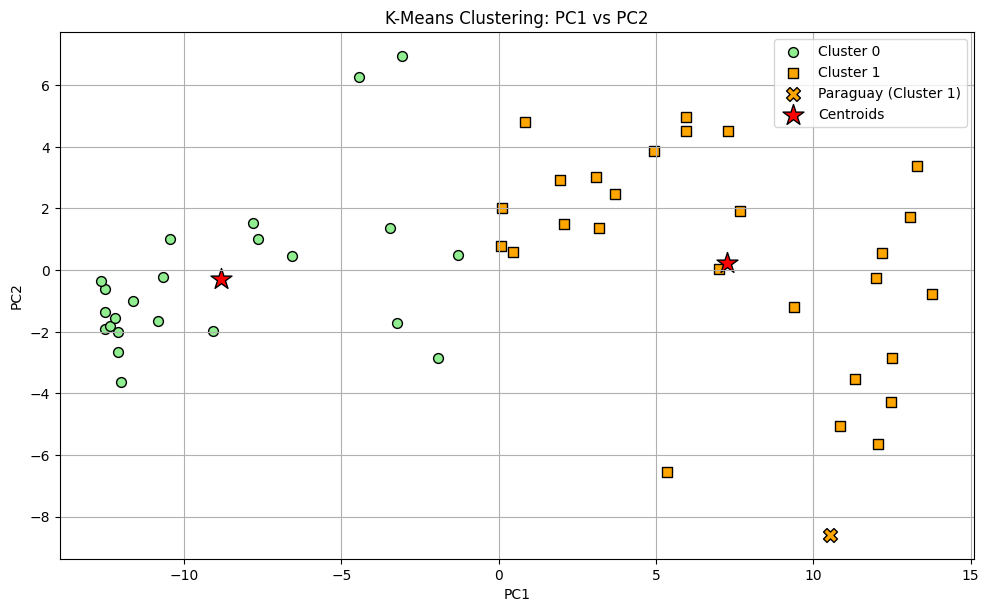

In [84]:
plot_kmeans_clusters(final_pca2, 'PC1', 'PC2', km_c2_ni20_maxi500_pca2)

### Another test of the culster model

* with the same idea as testing machine learning models
* taking into account all data points and comparing with the predicted synthetic values
* returning the mean of the MSE of all tested points

In [211]:
errors_c3 = {
    'cluster_0': [avg_mse_00, avg_mae_00],
    'cluster_1': [avg_mse_01, avg_mae_01],
    'cluster_2': [avg_mse_02, avg_mae_02]
}

In [212]:
# Convertir a DataFrame
df_errors_c3 = pd.DataFrame.from_dict(errors_c3, orient='index', columns=['Average MSE', 'Average MAE'])

# Formatear valores con 4 decimales
df_errors_c3 = df_errors_c3.round(4)

# Imprimir tabla
print("\n📊 Cluster Sampling Error Summary:")
print(df_errors_c3)


📊 Cluster Sampling Error Summary:
           Average MSE  Average MAE
cluster_0    1013.3423      23.2241
cluster_1     924.9483      22.8653
cluster_2     836.6494      21.4713


In [216]:
variances_c3 = calculate_hpi_variance_by_cluster(df_hpi_winsorized, final_pca2_c3)
for cluster_id, var in variances_c3.items():
    print(f"Cluster {cluster_id}: Avg HPI Variance = {var:.4f}")

Cluster 0: Avg HPI Variance = 952.2940
Cluster 1: Avg HPI Variance = 851.6158
Cluster 2: Avg HPI Variance = 791.5040


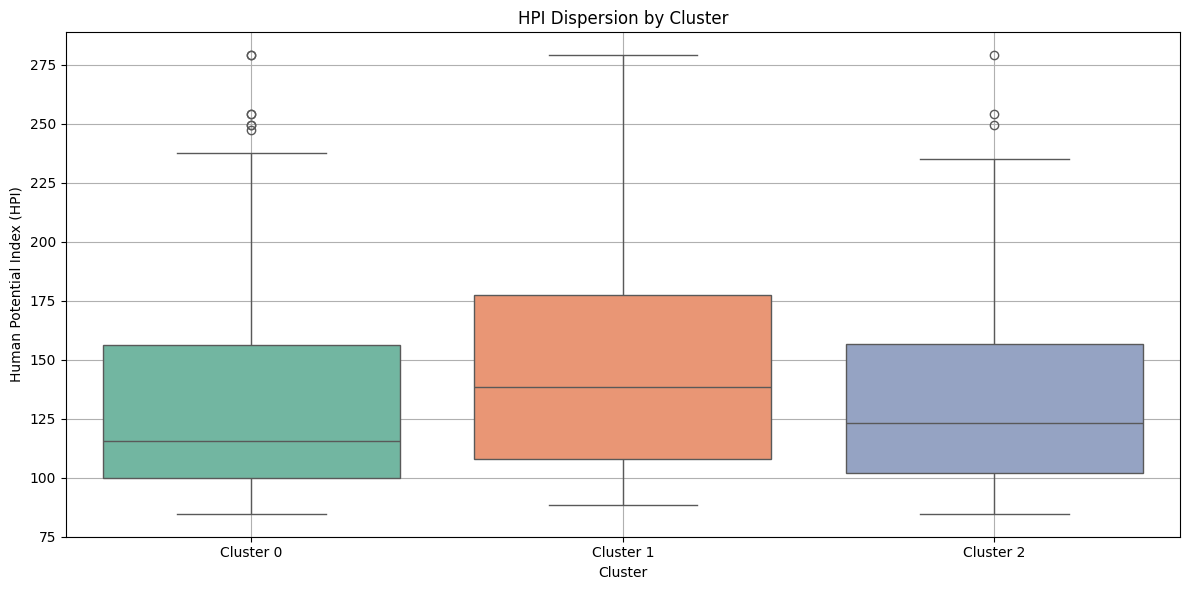

In [164]:
plot_hpi_dispersion_by_cluster(df_hpi_winsorized, final_pca2_c3)

In [218]:
iqr_points_c3 = count_points_within_iqr_by_cluster(df_hpi_winsorized, final_pca2_c3)

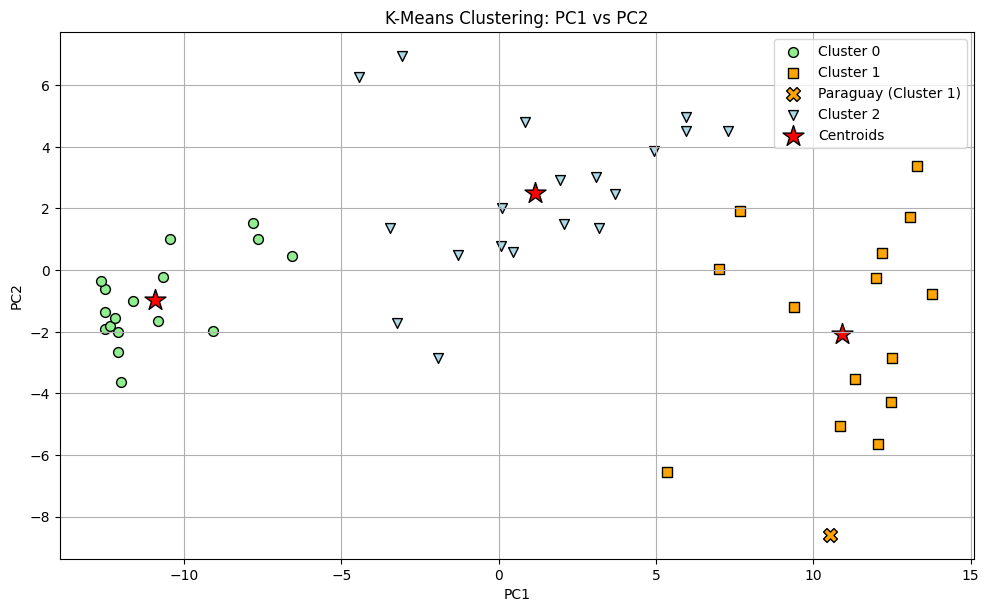

In [166]:
plot_kmeans_clusters(final_pca2_c3, 'PC1', 'PC2', km_c3_ni20_maxi500_pca2)

#### Cluster 0

In [168]:
def plot_cluster_hpi_with_bootstrap(df_hpi, df_clusters, cluster_id,
                                    yearly_bootstrap_means,
                                    yearly_mean,
                                    cluster_column='cluster', country_column='Country',
                                    year_column='Year'):
    """
    Plots HPI values for each country in a cluster over time,
    along with the synthetic bootstrap mean per year and the actual cluster mean.

    Parameters:
    - df_hpi: DataFrame with HPI values (columns = countries, rows = years, plus 'Year' column)
    - df_clusters: DataFrame with country names and cluster assignments
    - cluster_id: Cluster number to plot
    - yearly_bootstrap_means: Dict with year as key and synthetic mean value
    - yearly_mean: Dict with year as key and actual mean HPI of all countries in the cluster
    """
    # Obtener países del cluster
    cluster_countries = df_clusters[df_clusters[cluster_column] == cluster_id][country_column].tolist()
    cluster_countries = [c for c in cluster_countries if c in df_hpi.columns]

    if len(cluster_countries) == 0:
        raise ValueError("No hay países válidos en el cluster para graficar.")

    # Graficar HPI real por país
    plt.figure(figsize=(12, 6))
    for country in cluster_countries:
        country_data = df_hpi[[year_column, country]].dropna()
        plt.plot(country_data[year_column], country_data[country], label=country, alpha=0.6)

    # Graficar curva sintética del bootstrap
    bootstrap_years = sorted(yearly_bootstrap_means.keys())
    bootstrap_values = [yearly_bootstrap_means[year] for year in bootstrap_years]
    plt.plot(bootstrap_years, bootstrap_values, label='Bootstrap Mean', color='black', linewidth=2.5)

    # Graficar media real del cluster (línea discontinua)
    mean_years = sorted(yearly_mean.keys())
    mean_values = [yearly_mean[year] for year in mean_years]
    plt.plot(mean_years, mean_values, label='Real Cluster Mean', color='gray', linestyle='--', linewidth=2.5)

    # Estética del gráfico
    plt.title(f"HPI por País en Cluster {cluster_id} + Medias Sintéticas y Reales")
    plt.xlabel("Año")
    plt.ylabel("Índice HPI")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

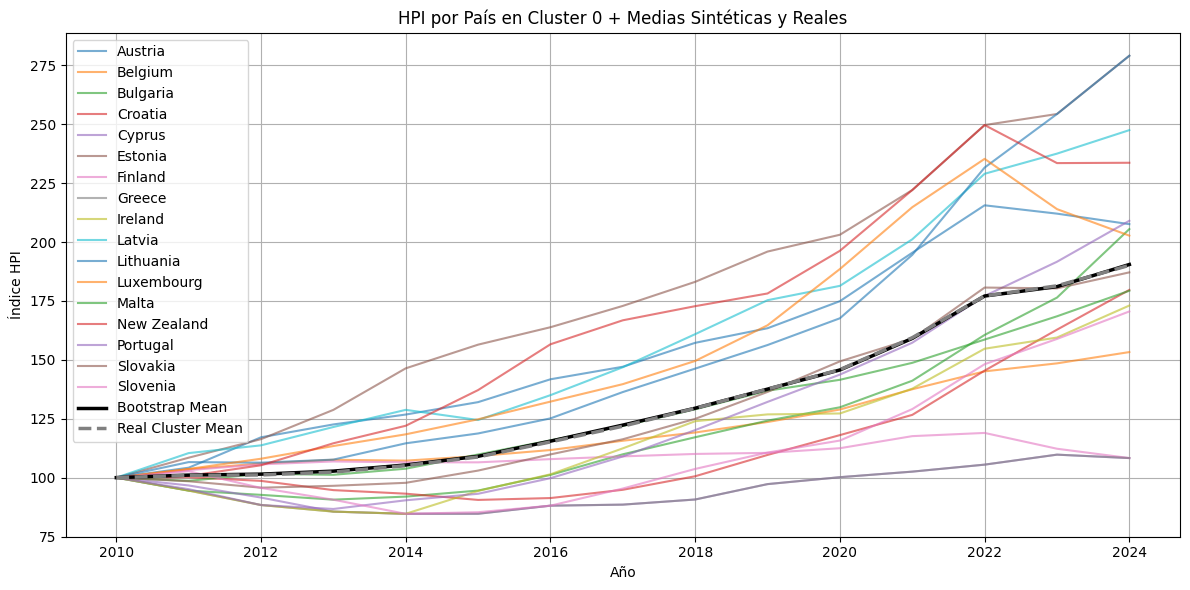

In [169]:
plot_cluster_hpi_with_bootstrap(df_hpi_winsorized, final_pca2_c3, cluster_id=0, yearly_bootstrap_means=yearly_bootstrap_means_00, yearly_mean=yearly_mean_00)

#### cluster 1

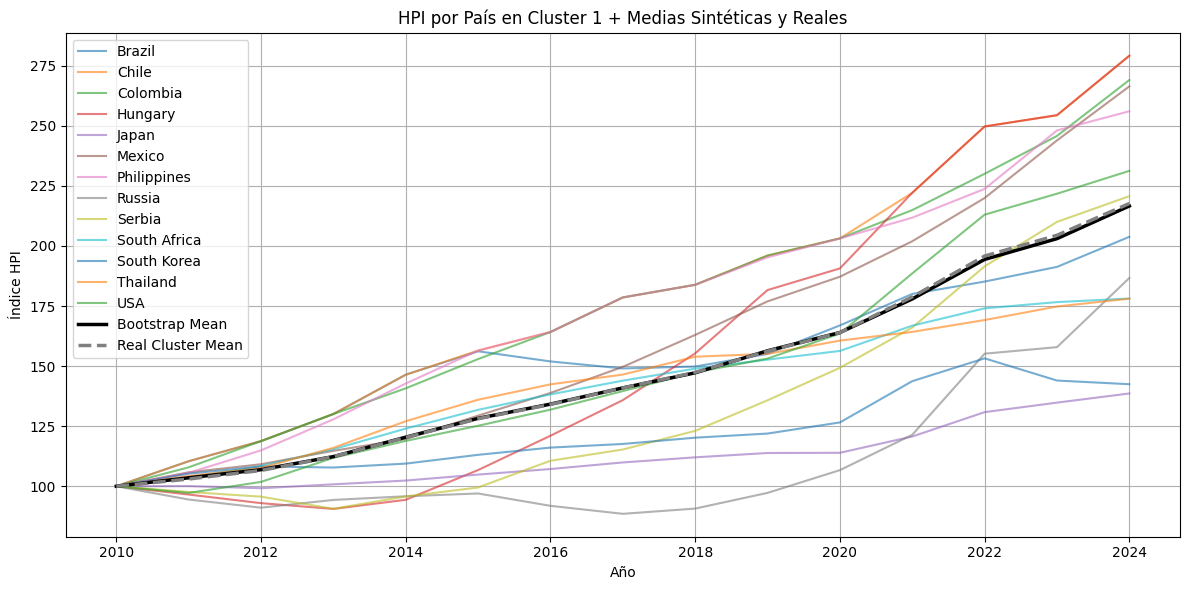

In [170]:
plot_cluster_hpi_with_bootstrap(df_hpi_winsorized, final_pca2_c3, cluster_id=1, yearly_bootstrap_means=yearly_bootstrap_means_01, yearly_mean=yearly_mean_01)

#### cluster 2

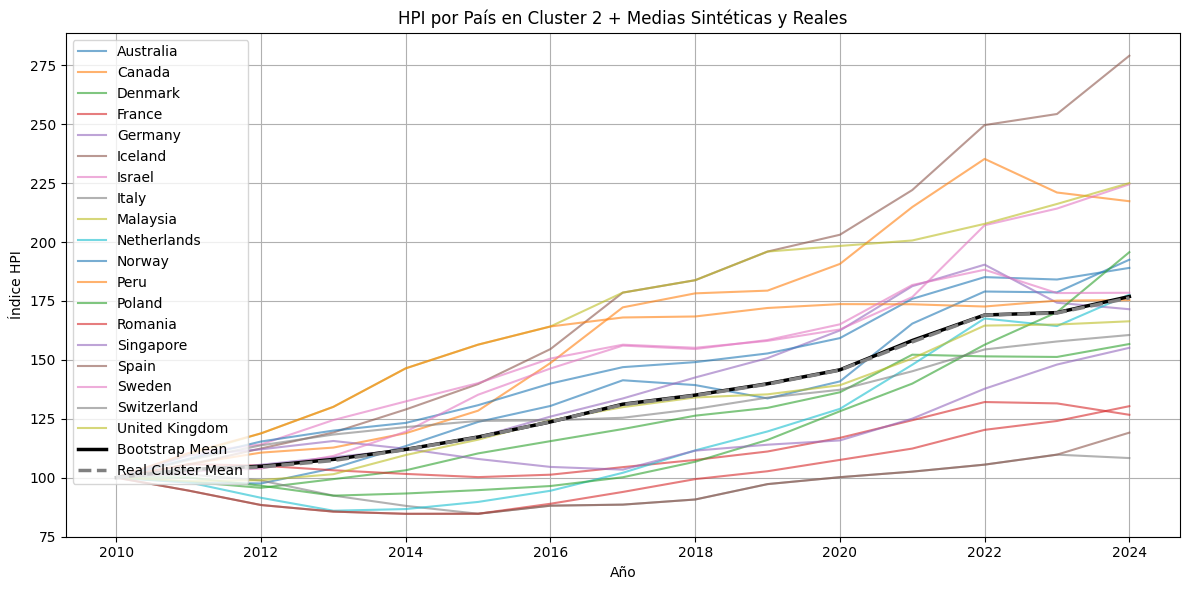

In [171]:
plot_cluster_hpi_with_bootstrap(df_hpi_winsorized, final_pca2_c3, cluster_id=2, yearly_bootstrap_means=yearly_bootstrap_means_02, yearly_mean=yearly_mean_02)

### Log performance

In [245]:
log_df = pd.read_parquet("../data/log_performance/clean_log_performance_experiments.parquet")

In [246]:
log_df.tail()

,experiment_name,experiment_date,premacroecon_conversion_transform,countries_used_for_clustering,clustering_model,n_clusters,init_method,n_init,max_iter,random_state,...,transformations_sampling,outliers_handling_sampling,sampling_method,sampling_seed,excluded_countries_count,mse_score,mae_score,source_notebook,pca_ratio_sum,pca_ratio_values
18,cluster_continet_based_3_countries_exclude,2025-09-17 17:01,None,52,Continet Based,4,None,NaN,NaN,NaN,...,"Winsorization x2, rounding",Winsorization x2,bootstrap,"[23, 42, 52]",3.0,1062.159368,23.694253,hypothesis_test_25.ipynb,NaN,None
19,kmeans_plusplus_c2_ni20_maxi500_3countries_del...,2025-09-18 17:00,None,50,KMeans,2,k-means++,20.0,500.0,42.0,...,"Delete Countries x3, Winsorization x4, rounding",Winsorization x4,bootstrap,"[32, 43, 52]",3.0,262.010999,12.168987,hypothesis_test_26.ipynb,NaN,None
20,kmeans_plusplus_c2_ni20_maxi500_h2_pca3_3_coun...,2025-09-18 19:59,None,52,KMeans,2,k-means++,20.0,500.0,42.0,...,"Winsorization x2, rounding",Winsorization x2,bootstrap,"[32, 43, 52]",3.0,558.544788,16.261550,hypothesis_test_28.ipynb,0.876932,"[0.7860579623666695, 0.09087374609246396]"
21,kmeans_plusplus_c2_ni20_maxi500_3cpuntries_del...,2025-09-20 22:43,None,50,KMeans,2,k-means++,20.0,500.0,42.0,...,"Winsorization x2, rounding",Winsorization x2,bootstrap,"[32, 43, 52]",3.0,246.836518,11.583352,hypothesis_test_29.ipynb,0.740380,"[0.6591137352377315, 0.08126612096581198]"
22,kmeans_plusplus_c3_ni20_maxi500_3countries_del...,2025-09-20 22:46,None,50,KMeans,3,k-means++,20.0,500.0,42.0,...,"Winsorization x2, rounding",Winsorization x2,bootstrap,"[32, 43, 52]",3.0,895.716945,22.740046,hypothesis_test_29.ipynb,0.740380,"[0.6591137352377315, 0.08126612096581198]"


In [247]:
new_entry= {
    'experiment_name': 'kmeans_plusplus_c3_ni20_maxi500_3countries_deleted_hpi_no_pca2_all_countries_exclude',
    'experiment_date': datetime.now().strftime('%Y-%m-%d %H:%M'),
    'clustering_model': 'KMeans',
    'n_clusters': 3,
    'init_method': 'k-means++',
    'n_init': 20,
    'max_iter': 500,
    'random_state': 42,
    'used_elbow_method': True,
    'used_silhouette_score': True,
    'used_2nd_derivate_for_inflection': True,
    'silhouette_score': silhoutte_score_c3_pca2,
    'transformations_clustering': 'StandardScaler, log transformation',
    'transformations_sampling': 'Winsorization x2, rounding',
    'outliers_handling_clustering': 'Winsorization x6',
    'outliers_handling_sampling': 'Winsorization x2',
    'sampling_method': 'bootstrap',
    'mse_score': df_errors_c3['Average MSE'].mean(),
    'mae_score': df_errors_c3['Average MAE'].mean(),
    'sampling_seed': (32,43,52),
    'excluded_countries_count': 50,
    'used_all_variables_for_clustering': True,
    'used_pca_for_clustering': True,
    "premacroecon_conversion_transform": None,
    "countries_used_for_clustering": 50
}
log_df = pd.concat([log_df, pd.DataFrame([new_entry])], ignore_index=True)
log_df.loc[23, "source_notebook"] = "hypothesis_test_29.ipynb"
log_df['used_all_variables_for_clustering'] = log_df['used_all_variables_for_clustering'].apply(str)

In [248]:
log_df.tail()

,experiment_name,experiment_date,premacroecon_conversion_transform,countries_used_for_clustering,clustering_model,n_clusters,init_method,n_init,max_iter,random_state,...,transformations_sampling,outliers_handling_sampling,sampling_method,sampling_seed,excluded_countries_count,mse_score,mae_score,source_notebook,pca_ratio_sum,pca_ratio_values
19,kmeans_plusplus_c2_ni20_maxi500_3countries_del...,2025-09-18 17:00,None,50,KMeans,2,k-means++,20.0,500.0,42.0,...,"Delete Countries x3, Winsorization x4, rounding",Winsorization x4,bootstrap,"[32, 43, 52]",3.0,262.010999,12.168987,hypothesis_test_26.ipynb,NaN,None
20,kmeans_plusplus_c2_ni20_maxi500_h2_pca3_3_coun...,2025-09-18 19:59,None,52,KMeans,2,k-means++,20.0,500.0,42.0,...,"Winsorization x2, rounding",Winsorization x2,bootstrap,"[32, 43, 52]",3.0,558.544788,16.261550,hypothesis_test_28.ipynb,0.876932,"[0.7860579623666695, 0.09087374609246396]"
21,kmeans_plusplus_c2_ni20_maxi500_3cpuntries_del...,2025-09-20 22:43,None,50,KMeans,2,k-means++,20.0,500.0,42.0,...,"Winsorization x2, rounding",Winsorization x2,bootstrap,"[32, 43, 52]",3.0,246.836518,11.583352,hypothesis_test_29.ipynb,0.740380,"[0.6591137352377315, 0.08126612096581198]"
22,kmeans_plusplus_c3_ni20_maxi500_3countries_del...,2025-09-20 22:46,None,50,KMeans,3,k-means++,20.0,500.0,42.0,...,"Winsorization x2, rounding",Winsorization x2,bootstrap,"[32, 43, 52]",3.0,895.716945,22.740046,hypothesis_test_29.ipynb,0.740380,"[0.6591137352377315, 0.08126612096581198]"
23,kmeans_plusplus_c3_ni20_maxi500_3countries_del...,2025-09-21 00:10,None,50,KMeans,3,k-means++,20.0,500.0,42.0,...,"Winsorization x2, rounding",Winsorization x2,bootstrap,"(32, 43, 52)",50.0,924.980000,22.520233,hypothesis_test_29.ipynb,NaN,NaN


In [249]:
log_df.loc[23, "pca_ratio_sum"] = pca_2.explained_variance_ratio_.sum()
# Change the column dtype to object
log_df["pca_ratio_values"] = log_df["pca_ratio_values"].astype('object')

# Now you can assign the tuple to the cell
log_df.at[23, "pca_ratio_values"] = tuple(pca_2.explained_variance_ratio_)


In [250]:
var_series = pd.Series(variances_c3, name='Avg_HPI_Variance')
iqr_series = pd.Series(iqr_points_c3, name='Points_Within_IQR')

In [221]:
var_series.head()

0    952.293966
1    851.615751
2    791.504036
Name: Avg_HPI_Variance, dtype: float64

In [222]:
iqr_series.head()

0    143
1    111
2    145
Name: Points_Within_IQR, dtype: int64

In [251]:
# Crear columnas con tipo object si no existen
if 'Cluster_HPI_Variance' not in log_df.columns:
    log_df['Cluster_HPI_Variance'] = pd.Series([None]*len(log_df), dtype='object')

if 'Cluster_IQR_Count' not in log_df.columns:
    log_df['Cluster_IQR_Count'] = pd.Series([None]*len(log_df), dtype='object')


In [252]:
for cluster_id, value in var_series.items():
    col_name = f'Variance_Cluster_{cluster_id}'
    log_df.loc[23, col_name] = value

for cluster_id, value in iqr_series.items():
    col_name = f'IQR_Count_Cluster_{cluster_id}'
    log_df.loc[23, col_name] = value

In [253]:
log_df = log_df.drop(columns=['Cluster_HPI_Variance', 'Cluster_IQR_Count'])

In [254]:
log_df.tail()

,experiment_name,experiment_date,premacroecon_conversion_transform,countries_used_for_clustering,clustering_model,n_clusters,init_method,n_init,max_iter,random_state,...,mae_score,source_notebook,pca_ratio_sum,pca_ratio_values,Variance_Cluster_0,Variance_Cluster_1,Variance_Cluster_2,IQR_Count_Cluster_0,IQR_Count_Cluster_1,IQR_Count_Cluster_2
19,kmeans_plusplus_c2_ni20_maxi500_3countries_del...,2025-09-18 17:00,None,50,KMeans,2,k-means++,20.0,500.0,42.0,...,12.168987,hypothesis_test_26.ipynb,NaN,None,NaN,NaN,NaN,NaN,NaN,NaN
20,kmeans_plusplus_c2_ni20_maxi500_h2_pca3_3_coun...,2025-09-18 19:59,None,52,KMeans,2,k-means++,20.0,500.0,42.0,...,16.261550,hypothesis_test_28.ipynb,0.876932,"[0.7860579623666695, 0.09087374609246396]",NaN,NaN,NaN,NaN,NaN,NaN
21,kmeans_plusplus_c2_ni20_maxi500_3cpuntries_del...,2025-09-20 22:43,None,50,KMeans,2,k-means++,20.0,500.0,42.0,...,11.583352,hypothesis_test_29.ipynb,0.740380,"[0.6591137352377315, 0.08126612096581198]",NaN,NaN,NaN,NaN,NaN,NaN
22,kmeans_plusplus_c3_ni20_maxi500_3countries_del...,2025-09-20 22:46,None,50,KMeans,3,k-means++,20.0,500.0,42.0,...,22.740046,hypothesis_test_29.ipynb,0.740380,"[0.6591137352377315, 0.08126612096581198]",NaN,NaN,NaN,NaN,NaN,NaN
23,kmeans_plusplus_c3_ni20_maxi500_3countries_del...,2025-09-21 00:10,None,50,KMeans,3,k-means++,20.0,500.0,42.0,...,22.520233,hypothesis_test_29.ipynb,0.740380,"(0.6591137352377315, 0.08126612096581198)",952.293966,851.615751,791.504036,143.0,111.0,145.0


In [255]:
new_entry= {
    'experiment_name': 'kmeans_plusplus_c2_ni20_maxi500_3countries_deleted_hpi_no_pca2_all_countries_exclude',
    'experiment_date': datetime.now().strftime('%Y-%m-%d %H:%M'),
    'clustering_model': 'KMeans',
    'n_clusters': 2,
    'init_method': 'k-means++',
    'n_init': 20,
    'max_iter': 500,
    'random_state': 42,
    'used_elbow_method': True,
    'used_silhouette_score': True,
    'used_2nd_derivate_for_inflection': True,
    'silhouette_score': silhoutte_score_pca2,
    'transformations_clustering': 'StandardScaler, log transformation',
    'transformations_sampling': 'Winsorization x2, rounding',
    'outliers_handling_clustering': 'Winsorization x6',
    'outliers_handling_sampling': 'Winsorization x2',
    'sampling_method': 'bootstrap',
    'mse_score': df_errors_c2['Average MSE'].mean(),
    'mae_score': df_errors_c2['Average MAE'].mean(),
    'sampling_seed': None,
    'excluded_countries_count': 50,
    'used_all_variables_for_clustering': True,
    'used_pca_for_clustering': True,
    "premacroecon_conversion_transform": None,
    "countries_used_for_clustering": 50
}

log_df = pd.concat([log_df, pd.DataFrame([new_entry])], ignore_index=True)
log_df.loc[24, "source_notebook"] = "hypothesis_test_29.ipynb"
log_df['used_all_variables_for_clustering'] = log_df['used_all_variables_for_clustering'].apply(str)
log_df.loc[24, "pca_ratio_sum"] = pca_2.explained_variance_ratio_.sum()
# Change the column dtype to object
log_df["pca_ratio_values"] = log_df["pca_ratio_values"].astype('object')

# Now you can assign the tuple to the cell
log_df.at[24, "pca_ratio_values"] = tuple(pca_2.explained_variance_ratio_)

var_series_c2 = pd.Series(variances_c2, name='Avg_HPI_Variance')
iqr_series_c2 = pd.Series(iqr_point_c2, name='Points_Within_IQR')

for cluster_id, value in var_series_c2.items():
    col_name = f'Variance_Cluster_{cluster_id}'
    log_df.loc[24, col_name] = value

for cluster_id, value in iqr_series_c2.items():
    col_name = f'IQR_Count_Cluster_{cluster_id}'
    log_df.loc[24, col_name] = value


In [262]:
log_df.to_parquet('../data/log_performance/clean_log_performance_experiments.parquet')